
<div style="background-color: lightgreen; color: black; padding: 20px; box-sizing: border-box; width: 99%;">

👋 <b>Olá! Eu sou o Dot, seu revisor de IA.</b>

🎉 <b>Parabéns! Você foi aprovado no seu projeto.</b>

Parabéns, esta é uma análise completa e bem organizada que merece a aprovação! Você corrigiu todos os principais problemas da rodada anterior: os heatmaps de coorte agora usam o último mês completo, a comparação de LTV usa um horizonte fixo de 6 meses, o ROMI segue a definição padrão líquida do investimento, a fonte 7 é tratada explicitamente, e as recomendações incluem valores concretos de orçamento respaldados por CAC, ROMI, payback e LTV. Para trabalhos futuros, verifique novamente se cada interpretação corresponde às suas próprias tabelas (por exemplo, volume de tickets versus volume de pedidos), mostre os números que você cita nos outputs visíveis e elimine fragmentos de texto remanescentes e colunas com rótulos incorretos. Mantenha esse nível de cuidado e rigor nos seus próximos projetos!

Se você tiver alguma dificuldade ou erro, fique à vontade para entrar em contato com nossa equipe de suporte clicando no ícone de chat no canto superior direito ou enviando um e-mail para [helpme@tripleten.com](mailto:helpme@tripleten.com).

<hr style="margin-top: 20px; margin-bottom: 20px;">

<details>
<summary><b style="cursor: pointer;">💡 Clique aqui para ver como ler meus comentários (Legenda de cores)</b></summary>
<div style="margin-top: 15px;">
Veja meus comentários abaixo. <b>Peço gentilmente que não os mova, modifique nem exclua</b>.

Você encontrará meus comentários destacados em caixas verdes, amarelas ou vermelhas como estas:

<div class="alert alert-block alert-success">
Sucesso. Tudo foi feito corretamente.
</div>

<div class="alert alert-block alert-warning">
Observações. Algumas recomendações.
</div>

<div class="alert alert-block alert-danger">
A corrigir. O bloco requer algumas correções.
</div>
</div>
</details>

</div>



# Análise de Negócios — Y.Afisha

# 1. Introdução

A Y.Afisha pretende otimizar os seus investimentos em marketing, identificando quais as origens de publicidade que proporcionam os melhores resultados e contribuem para o crescimento do negócio.

Neste projeto, atuaremos como analistas de dados do departamento analítico da empresa, com o objetivo de compreender o comportamento dos utilizadores, analisar o desempenho das vendas e avaliar a eficiência dos investimentos em marketing.

Para isso, serão analisados três conjuntos de dados:

- **visits:** registos das visitas e sessões dos utilizadores no site.
- **orders:** histórico de pedidos realizados pelos clientes e respetivas receitas.
- **costs:** despesas de marketing associadas às diferentes origens de publicidade.

## Objetivos do projeto

1. **Análise do Produto:** compreender como os utilizadores interagem com o site, analisando as visitas, sessões, duração, conversão e comportamento dos utilizadores.

2. **Análise das Vendas:** avaliar o comportamento de compra dos clientes, o número de pedidos, a frequência de compras, o valor médio dos pedidos e o Lifetime Value (LTV), incluindo a análise de coortes.

3. **Análise de Marketing:** analisar os investimentos em publicidade, calcular o Custo de Aquisição de Clientes (CAC) e avaliar a relação entre as receitas geradas e as despesas de marketing por origem de aquisição.

## Objetivo final

Identificar as origens de publicidade mais eficientes e formular recomendações fundamentadas em métricas e indicadores de desempenho, de modo a contribuir para uma melhor distribuição do orçamento de marketing da Y.Afisha e para a otimização dos seus resultados.


<div class="alert alert-block alert-success">

Sua introdução está clara e bem organizada. Ela apresenta o objetivo de negócio, descreve os três datasets e divide os objetivos em Produto, Vendas e Marketing. Opcionalmente, mencione o período abrangido (junho de 2017 a maio de 2018) para completar o contexto.

</div>

## 2.  Preparação dos dados
### 2.1 Importação das bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 2.2 Otimização do conjunto de dados `visits`

In [2]:
# Carregamento de pequena amostra
df_visits = pd.read_csv(
    '/datasets/visits_log_us.csv',
    nrows=500
)

In [3]:
# Inspecionar os dados
df_visits.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Device     500 non-null    object
 1   End Ts     500 non-null    object
 2   Source Id  500 non-null    int64 
 3   Start Ts   500 non-null    object
 4   Uid        500 non-null    uint64
dtypes: int64(1), object(3), uint64(1)
memory usage: 113.1 KB


In [4]:
# Identificar as categorias
df_visits['Device'].value_counts()

desktop    363
touch      137
Name: Device, dtype: int64

In [5]:
# Converter a coluna Device
df_visits['Device'] = df_visits['Device'].astype('category')

In [6]:
# Converter as colunas de datas
df_visits['Start Ts'] = pd.to_datetime(df_visits['Start Ts'])

df_visits['End Ts'] = pd.to_datetime(df_visits['End Ts'])

In [7]:
# Verificar o resultado
df_visits.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Device     500 non-null    category      
 1   End Ts     500 non-null    datetime64[ns]
 2   Source Id  500 non-null    int64         
 3   Start Ts   500 non-null    datetime64[ns]
 4   Uid        500 non-null    uint64        
dtypes: category(1), datetime64[ns](2), int64(1), uint64(1)
memory usage: 16.5 KB


### 2.2.1 Carregamento do ficheiro completo

In [8]:
# Carregamento do ficheiro completo
df_visits = pd.read_csv(
    '/datasets/visits_log_us.csv',
    dtype={
        'Device': 'category', 
        'Source_Id': 'int16'
    },
    parse_dates=['Start Ts', 'End Ts']
)

### 2.3 Otimização do conjunto de dados `orders`

In [9]:
# Carregamento de pequena amostra
df_orders = pd.read_csv(
    '/datasets/orders_log_us.csv',
    nrows=500
)

In [10]:
# Inspecionar os dados
df_orders.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Buy Ts   500 non-null    object 
 1   Revenue  500 non-null    float64
 2   Uid      500 non-null    uint64 
dtypes: float64(1), object(1), uint64(1)
memory usage: 45.0 KB


In [11]:
# Converter a coluna Buy Ts para datetime
df_orders['Buy Ts'] = pd.to_datetime(df_orders['Buy Ts'])


In [12]:
# Verificar o resultado
df_orders.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Buy Ts   500 non-null    datetime64[ns]
 1   Revenue  500 non-null    float64       
 2   Uid      500 non-null    uint64        
dtypes: datetime64[ns](1), float64(1), uint64(1)
memory usage: 11.8 KB


### 2.3.1 Carregamento do ficheiro completo

In [13]:
# Carregar o ficheiro completo já otimizado
df_orders = pd.read_csv(
    '/datasets/orders_log_us.csv',
    parse_dates=['Buy Ts']
)

### 2.4 Otimização do conjunto de dados `costs`

In [14]:
# Carregamento de pequena amostra
df_costs = pd.read_csv('/datasets/costs_us.csv')

In [15]:
# Inspecionar os dados
df_costs.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2542 entries, 0 to 2541
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   source_id  2542 non-null   int64  
 1   dt         2542 non-null   object 
 2   costs      2542 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 206.2 KB


In [16]:
# Identificar as origens de publicidade
df_costs['source_id'].value_counts()

5     364
2     363
4     363
10    363
1     363
3     363
9     363
Name: source_id, dtype: int64

In [17]:
# Converter a coluna dt para datetime
df_costs['dt'] = pd.to_datetime(df_costs['dt'])

In [18]:
# Verificar o resultado
df_costs.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2542 entries, 0 to 2541
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   source_id  2542 non-null   int64         
 1   dt         2542 non-null   datetime64[ns]
 2   costs      2542 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 59.7 KB


### 2.4.1 Carregamento do ficheiro completo

In [19]:
# Carregar o ficheiro completo já otimizado

df_costs = pd.read_csv(
    '/datasets/costs_us.csv',
    parse_dates=['dt']
)

### 2.5 Verificação dos dados

In [20]:
# Verificar a estrutura dos três DataFrames
print('VISITS')
df_visits.info(memory_usage='deep')

print('\nORDERS')
df_orders.info(memory_usage='deep')

print('\nCOSTS')
df_costs.info(memory_usage='deep')

VISITS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   Device     359400 non-null  category      
 1   End Ts     359400 non-null  datetime64[ns]
 2   Source Id  359400 non-null  int64         
 3   Start Ts   359400 non-null  datetime64[ns]
 4   Uid        359400 non-null  uint64        
dtypes: category(1), datetime64[ns](2), int64(1), uint64(1)
memory usage: 11.3 MB

ORDERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Buy Ts   50415 non-null  datetime64[ns]
 1   Revenue  50415 non-null  float64       
 2   Uid      50415 non-null  uint64        
dtypes: datetime64[ns](1), float64(1), uint64(1)
memory usage: 1.2 MB

COSTS
<class 'pandas.core.frame.DataFrame'>
RangeInde

In [21]:
# Verificar o número de linhas e colunas
print('Visits:', df_visits.shape)
print('Orders:', df_orders.shape)
print('Costs:', df_costs.shape)

Visits: (359400, 5)
Orders: (50415, 3)
Costs: (2542, 3)


In [22]:
# Verificar valores ausentes no DataFrame dos pedidos
print('Valores ausentes — orders')
display(df_orders.isna().sum())

Valores ausentes — orders


Buy Ts     0
Revenue    0
Uid        0
dtype: int64

In [23]:
# Verificar dublicados
print('Duplicados em visits:', df_visits.duplicated().sum())
print('Duplicados em orders:', df_orders.duplicated().sum())
print('Duplicados em costs:', df_costs.duplicated().sum())

print('Período das visitas:', df_visits['Start Ts'].min(), 'a', df_visits['Start Ts'].max())
print('Período dos pedidos:', df_orders['Buy Ts'].min(), 'a', df_orders['Buy Ts'].max())
print('Período dos custos:', df_costs['dt'].min(), 'a', df_costs['dt'].max())

Duplicados em visits: 0
Duplicados em orders: 0
Duplicados em costs: 0
Período das visitas: 2017-06-01 00:01:00 a 2018-05-31 23:59:00
Período dos pedidos: 2017-06-01 00:10:00 a 2018-06-01 00:02:00
Período dos custos: 2017-06-01 00:00:00 a 2018-05-31 00:00:00


## Análise do Produto
### 3. Como os utilizadores utilizam o produto?

#### 3.1 Preparar as datas das sessões

In [24]:
# Extrair a data de cada sessão
df_visits['session_date'] = (
    df_visits['Start Ts'].dt.date
)

# Identificar o período semanal
df_visits['session_week'] = (
    df_visits['Start Ts'].dt.to_period('W')
)

# Identificar o período mensal
df_visits['session_month'] = (
    df_visits['Start Ts'].dt.to_period('M')
)

# Calcular a duração das sessões em minutos
df_visits['session_duration_min'] = (
    df_visits['End Ts'] - df_visits['Start Ts']
).dt.total_seconds() / 60

In [25]:
# Verificar o resultado
df_visits[['Start Ts', 'session_month',
           'session_week', 'session_date', 'session_duration_min']].head()

,Start Ts,session_month,session_week,session_date,session_duration_min
0,2017-12-20 17:20:00,2017-12,2017-12-18/2017-12-24,2017-12-20,18.0
1,2018-02-19 16:53:00,2018-02,2018-02-19/2018-02-25,2018-02-19,28.0
2,2017-07-01 01:54:00,2017-07,2017-06-26/2017-07-02,2017-07-01,0.0
3,2018-05-20 10:59:00,2018-05,2018-05-14/2018-05-20,2018-05-20,24.0
4,2017-12-27 14:06:00,2017-12,2017-12-25/2017-12-31,2017-12-27,0.0


#### 3.2 Sessões por dia, duração e frequência de retorno

In [26]:
# Calcular sessões por dia e por utilizador
sessions_per_day = df_visits.groupby('session_date').size()
sessions_per_user = df_visits.groupby('Uid').size()

# Duração das sessões
print(f'Sessões médias por dia: {sessions_per_day.mean():.2f}')
print(f'Duração média da sessão: {df_visits["session_duration_min"].mean():.2f} minutos')
print(f'Duração mediana da sessão: {df_visits["session_duration_min"].median():.2f} minutos')
print(f'Sessões médias por utilizador: {sessions_per_user.mean():.2f}')
print(f'Mediana de sessões por utilizador: {sessions_per_user.median():.0f}')

# Avaliar a frequencia de retorno
returning_users_share = (sessions_per_user > 1).mean() * 100
print(f'Utilizadores com mais de uma sessão: {returning_users_share:.2f}%')

Sessões médias por dia: 987.36
Duração média da sessão: 10.72 minutos
Duração mediana da sessão: 5.00 minutos
Sessões médias por utilizador: 1.58
Mediana de sessões por utilizador: 1
Utilizadores com mais de uma sessão: 22.85%


#### 3.2.1 Visualizar o número de sessões por dia

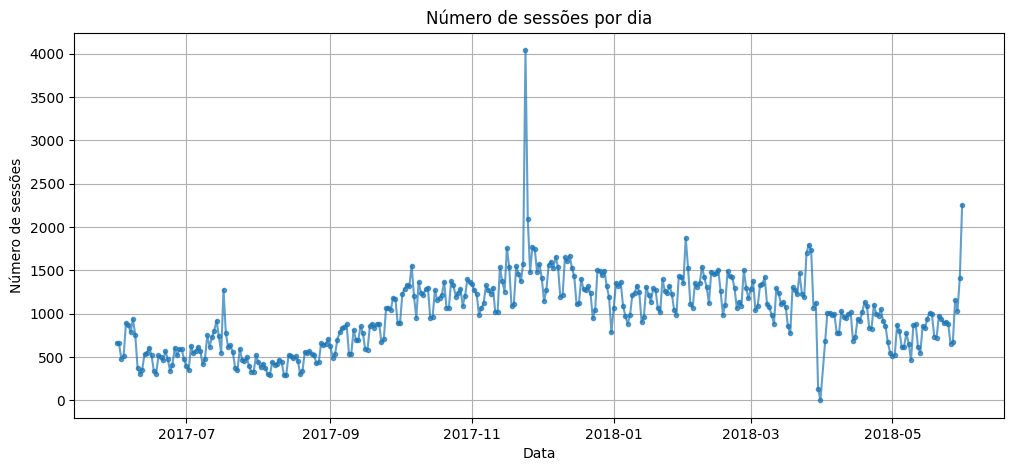

In [27]:
# Visualizar as sessões diárias
sessions_per_day.plot(
    kind='line', figsize=(12, 5), marker='.', alpha=0.7
)
plt.title('Número de sessões por dia')
plt.xlabel('Data')
plt.ylabel('Número de sessões')
plt.grid()
plt.show()

#### 3.3 Analisar a duração das sessões por dispositivo e origem

In [28]:
# Calcular a duração média das sessões por dispositivo e origem
session_duration_segmented = df_visits.groupby(
    ['Source Id', 'Device'],
    observed=True
)['session_duration_min'].mean().unstack()

# Verificar os resultados
display(session_duration_segmented)

Device,touch,desktop
Source Id,,
1,12.435093,18.873823
2,10.100664,15.413309
3,7.159114,10.255159
4,7.507979,10.251037
5,6.459259,9.559075
6,3.000000,26.800000
7,8.000000,10.714286
9,7.421870,10.061870
10,7.641560,12.267146


#### 3.3.1 Visualizar a duração média das sessões

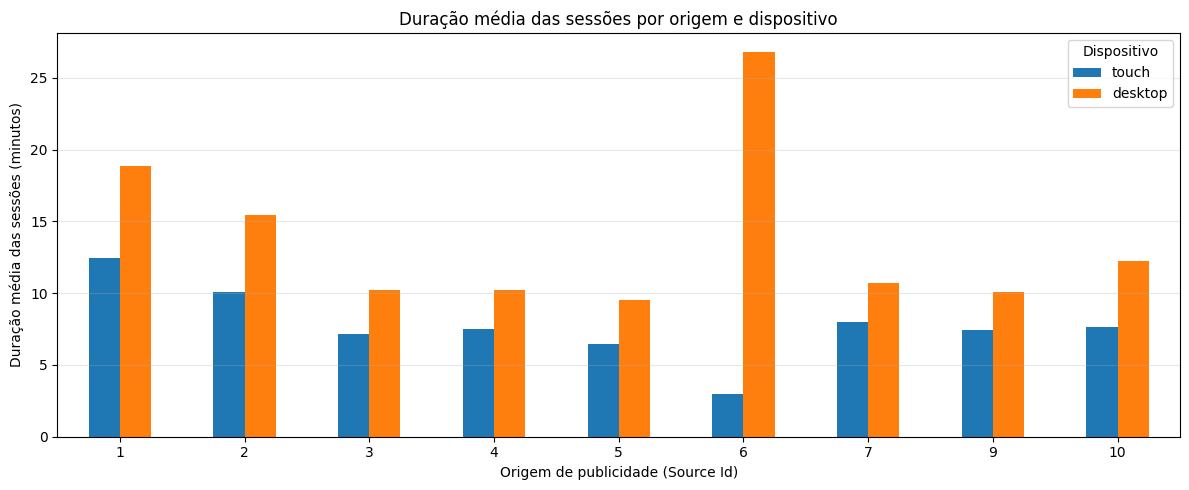

In [29]:
# Visualizar a duração média das sessões por dispositivo e origem
session_duration_segmented.plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Duração média das sessões por origem e dispositivo')
plt.xlabel('Origem de publicidade (Source Id)')
plt.ylabel('Duração média das sessões (minutos)')
plt.xticks(rotation=0)
plt.legend(title='Dispositivo')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### 3.3.2 Verificar o volume de sessões por segmento

In [30]:
# Contar o número de sessões por origem e dispositivo
sessions_by_source_device = df_visits.groupby(
    ['Source Id', 'Device'],
    observed=True
).size().unstack(fill_value=0)

display(sessions_by_source_device)

Device,touch,desktop
Source Id,,
1,8220,25901
2,11965,35661
3,19833,65777
4,34154,67640
5,16836,50069
6,1,5
7,8,28
9,3158,10119
10,2658,7367


**Interpretação e Conclusão — Duração das sessões por dispositivo e origem**

A análise da duração média das sessões por origem publicitária e dispositivo revelou diferenças consistentes no comportamento dos utilizadores.

O desktop apresentou uma duração média superior à do touch em todas as origens analisadas. Destaca-se a origem 1, com aproximadamente 18,87 minutos em desktop e 12,44 minutos em touch, indicando um maior tempo de permanência dos utilizadores provenientes dessa origem.

A origem 2 também apresentou resultados relevantes, com médias de 15,41 minutos em desktop e 10,10 minutos em touch.

Importa, contudo, considerar o volume de sessões de cada segmento. As origens 6 e 7 apresentam um número muito reduzido de observações, pelo que as respetivas médias devem ser interpretadas com cautela.

Em síntese, os resultados sugerem que os utilizadores de desktop tendem a permanecer mais tempo no site do que os utilizadores de touch. Estas diferenças justificam uma investigação adicional sobre o comportamento dos utilizadores e a experiência de navegação em cada dispositivo.

#### 3.4 Analisar a frequência de retorno por dispositivo e origem
#### 3.4.1 Identificar a primeira sessão de cada utilizador

In [31]:
# Identificar a primeira sessão de cada utilizador
first_session_users = df_visits.sort_values(
    'Start Ts'
).drop_duplicates('Uid')[
    ['Uid', 'Source Id', 'Device']
]

# Verificar os resultados
display(first_session_users.head(10))

,Uid,Source Id,Device
308527,13890188992670018146,5,desktop
260646,16152015161748786004,3,desktop
245715,16706502037388497502,3,desktop
235930,8842918131297115663,3,desktop
11727,10329302124590727494,1,desktop
278203,17384547788533003069,4,desktop
352873,16109239769442553005,2,desktop
69744,11627257723692907447,2,desktop
190436,17903680561304213844,2,desktop
16194,13136692283820170315,2,touch


#### 3.4.2 Calcular o número total de sessões por utilizador

In [32]:
# Contar todas as sessões realizadas por cada utilizador
total_sessions_per_user = df_visits.groupby(
    'Uid'
).size().reset_index(name='total_sessions')

# Verificar os resultados
display(total_sessions_per_user.head(10))

,Uid,total_sessions
0,11863502262781,1
1,49537067089222,1
2,297729379853735,1
3,313578113262317,3
4,325320750514679,2
5,397399764396656,1
6,407573351275847,1
7,498809019029702,1
8,526778907996220,4
9,577434573913691,2


#### 3.4.3 Associar a primeira sessão ao número total de sessões

In [33]:
# Associar a primeira origem e dispositivo ao total de sessões
user_return_analysis = first_session_users.merge(
    total_sessions_per_user,
    on='Uid',
    how='left'
)

# Identificar utilizadores recorrentes
user_return_analysis['returning_user'] = (
    user_return_analysis['total_sessions'] > 1
)

# Verificar os resultados
display(user_return_analysis.head(10))

,Uid,Source Id,Device,total_sessions,returning_user
0,13890188992670018146,5,desktop,1,False
1,16152015161748786004,3,desktop,1,False
2,16706502037388497502,3,desktop,1,False
3,8842918131297115663,3,desktop,1,False
4,10329302124590727494,1,desktop,1,False
5,17384547788533003069,4,desktop,1,False
6,16109239769442553005,2,desktop,1,False
7,11627257723692907447,2,desktop,1,False
8,17903680561304213844,2,desktop,1,False
9,13136692283820170315,2,touch,2,True


#### 3.4.4 Calcular a frequência de retorno por origem e dispositivo

In [34]:
# Calcular métricas de retorno por origem e dispositivo
returning_users_summary = user_return_analysis.groupby(
    ['Source Id', 'Device'],
    observed=True
).agg(
    total_users=('Uid', 'nunique'),
    returning_users=('returning_user', 'sum'),
    return_rate=('returning_user', 'mean')
).reset_index()

# Converter a taxa de retorno em percentagem
returning_users_summary['return_rate'] *= 100

# Verificar os resultados
display(returning_users_summary)

,Source Id,Device,total_users,returning_users,return_rate
0,1,desktop,6347,2391,37.671341
1,1,touch,3122,976,31.262012
2,2,desktop,11771,3990,33.896865
3,2,touch,5845,1614,27.613345
4,3,desktop,50190,11759,23.428970
5,3,touch,15926,3589,22.535477
6,4,desktop,46965,9775,20.813372
7,4,touch,25381,4858,19.140302
8,5,desktop,35822,6949,19.398694
9,5,touch,13415,2425,18.076780


#### 3.4.5 Visualizar a frequência de retorno

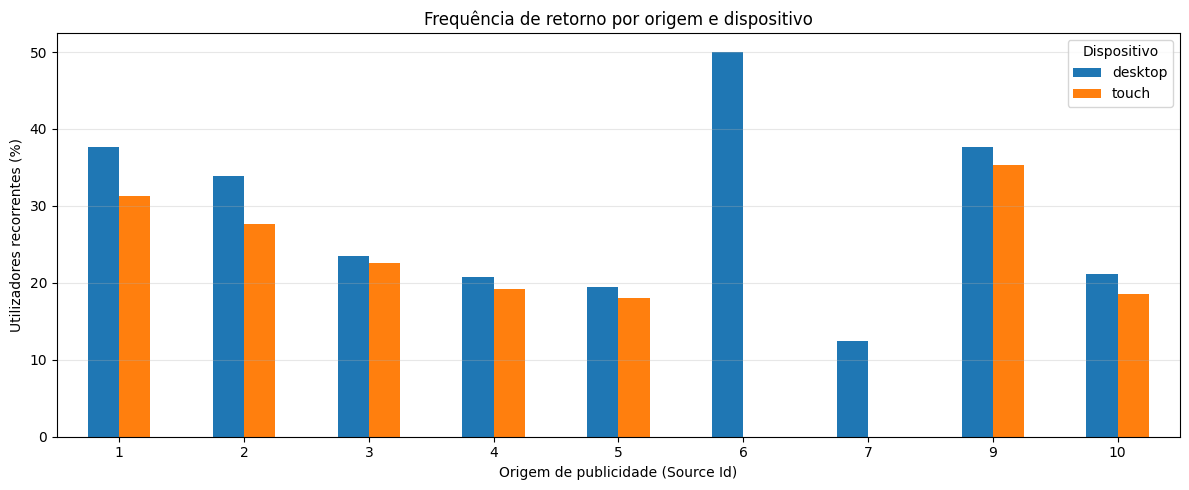

In [35]:
# Visualizar a frequência de retorno por origem e dispositivo
returning_users_summary.pivot(
    index='Source Id',
    columns='Device',
    values='return_rate'
).plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Frequência de retorno por origem e dispositivo')
plt.xlabel('Origem de publicidade (Source Id)')
plt.ylabel('Utilizadores recorrentes (%)')
plt.xticks(rotation=0)
plt.legend(title='Dispositivo')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretação da frequência de retorno por origem e dispositivo**

A análise da frequência de retorno revela diferenças no comportamento dos utilizadores consoante a origem publicitária e o dispositivo utilizado na primeira sessão.

De forma geral, o **desktop apresenta taxas de retorno superiores às do touch** na maioria das origens publicitárias, sugerindo uma maior propensão dos utilizadores adquiridos através deste dispositivo para regressarem ao site.

Entre as origens com maior volume de utilizadores, destacam-se:

- **Origem 1:** apresenta uma das melhores taxas de retorno, com aproximadamente 37,7% no desktop e 31,3% no touch.
- **Origem 2:** regista taxas de aproximadamente 33,9% no desktop e 27,6% no touch.
- **Origem 9:** também apresenta resultados expressivos, com aproximadamente 37,6% no desktop e 35,4% no touch.

A **origem 3**, apesar de apresentar o maior volume de utilizadores, regista taxas de retorno mais moderadas, de aproximadamente 23,4% no desktop e 22,5% no touch.

É importante interpretar com cautela os resultados das origens 6 e 7, uma vez que apresentam um número reduzido de utilizadores. Por exemplo, a taxa de 50% da origem 6 corresponde apenas a 1 utilizador recorrente em 2, não sendo suficiente para concluir que se trata de uma origem com desempenho superior.

**Conclusão:** as origens 1 e 9 apresentam resultados particularmente interessantes em termos de frequência de retorno, enquanto a origem 3 se destaca sobretudo pelo volume de utilizadores adquiridos. Estas diferenças mostram que atrair mais utilizadores não significa necessariamente conseguir maior fidelização.

Na próxima análise, cruzaremos a duração média das sessões com a frequência de retorno por origem e dispositivo, permitindo compreender melhor não só quantos utilizadores regressam, mas também quanto tempo permanecem no site.

#### 3.5 Analisar a duração e a frequência de retorno por origem e dispositivo
#### 3.5.1 Associar as sessões à origem e ao dispositivo de aquisição

In [36]:
# Associar todas as sessões à origem e dispositivo de aquisição
visits_by_acquisition = df_visits.merge(
    first_session_users[['Uid', 'Source Id', 'Device']],
    on='Uid',
    how='left',
    suffixes=('_session', '_acquisition')
)

# Verificar o resultado
display(visits_by_acquisition.head())

,Device_session,End Ts,Source Id_session,Start Ts,Uid,session_date,session_week,session_month,session_duration_min,Source Id_acquisition,Device_acquisition
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062,2017-12-20,2017-12-18/2017-12-24,2017-12,18.0,4,touch
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740,2018-02-19,2018-02-19/2018-02-25,2018-02,28.0,2,desktop
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527,2017-07-01,2017-06-26/2017-07-02,2017-07,0.0,5,touch
3,desktop,2018-05-20 11:23:00,9,2018-05-20 10:59:00,16174680259334210214,2018-05-20,2018-05-14/2018-05-20,2018-05,24.0,4,desktop
4,desktop,2017-12-27 14:06:00,3,2017-12-27 14:06:00,9969694820036681168,2017-12-27,2017-12-25/2017-12-31,2017-12,0.0,3,desktop


#### 3.5.2 Calcular a duração média das sessões por segmento de aquisição

In [37]:
# Calcular a duração média das sessões por origem e dispositivo de aquisição
duration_by_acquisition = visits_by_acquisition.groupby(
    ['Source Id_acquisition', 'Device_acquisition'],
    observed=True
).agg(
    avg_session_duration=('session_duration_min', 'mean'),
    total_sessions=('Uid', 'size'),
    users_with_sessions=('Uid', 'nunique')
).reset_index()

# Renomear as colunas
duration_by_acquisition = duration_by_acquisition.rename(
    columns={
        'Source Id_acquisition': 'Source Id',
        'Device_acquisition': 'Device'
    }
)

# Verificar os resultados
display(duration_by_acquisition)

,Source Id,Device,avg_session_duration,total_sessions,users_with_sessions
0,1,touch,12.213958,5550,3122
1,1,desktop,17.173282,18351,6347
2,2,touch,10.403146,10186,5845
3,2,desktop,15.572715,31644,11771
4,3,touch,8.413925,23448,15926
5,3,desktop,10.803533,76015,50190
6,4,touch,7.909398,34806,25381
7,4,desktop,10.424242,68466,46965
8,5,touch,6.964004,17694,13415
9,5,desktop,9.771382,50270,35822


#### 3.5.3 Associar a duração média à frequência de retorno

In [38]:
# Associar duração média e frequência de retorno
engagement_by_source_device = duration_by_acquisition.merge(
    returning_users_summary,
    on=['Source Id', 'Device'],
    how='left'
)

# Ordenar os resultados
engagement_by_source_device = engagement_by_source_device.sort_values(
    ['Source Id', 'Device']
)

# Apresentar os resultados
display(engagement_by_source_device)

,Source Id,Device,avg_session_duration,total_sessions,users_with_sessions,total_users,returning_users,return_rate
1,1,desktop,17.173282,18351,6347,6347,2391,37.671341
0,1,touch,12.213958,5550,3122,3122,976,31.262012
3,2,desktop,15.572715,31644,11771,11771,3990,33.896865
2,2,touch,10.403146,10186,5845,5845,1614,27.613345
5,3,desktop,10.803533,76015,50190,50190,11759,23.428970
4,3,touch,8.413925,23448,15926,15926,3589,22.535477
7,4,desktop,10.424242,68466,46965,46965,9775,20.813372
6,4,touch,7.909398,34806,25381,25381,4858,19.140302
9,5,desktop,9.771382,50270,35822,35822,6949,19.398694
8,5,touch,6.964004,17694,13415,13415,2425,18.076780


#### 3.5.4 Visualizar: duração e frequência de retorno

#### Gráfico 1 — Duração média das sessões

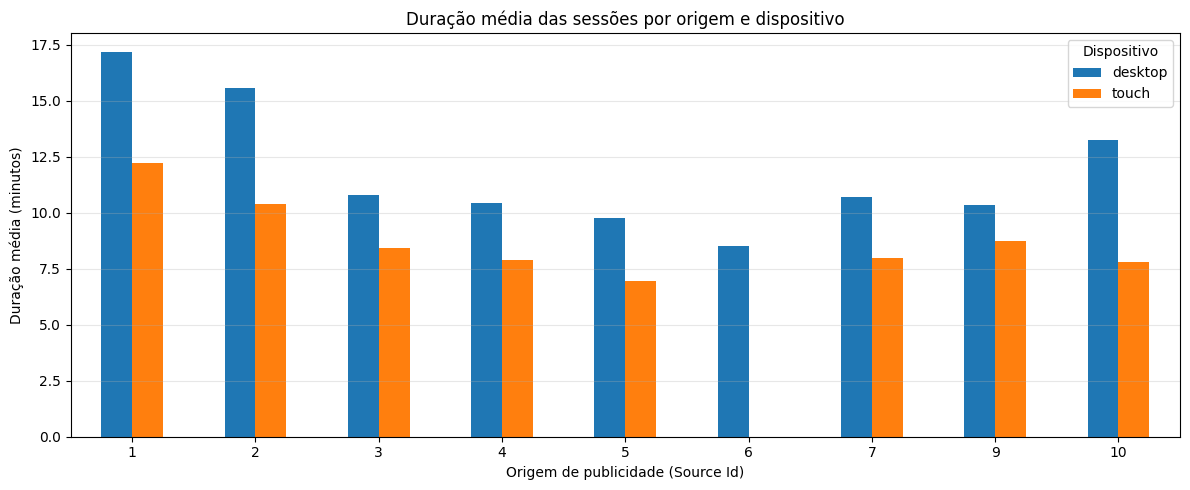

In [39]:
# Visualizar a duração média das sessões por origem e dispositivo
duration_by_acquisition.pivot(
    index='Source Id',
    columns='Device',
    values='avg_session_duration'
).plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Duração média das sessões por origem e dispositivo')
plt.xlabel('Origem de publicidade (Source Id)')
plt.ylabel('Duração média (minutos)')
plt.xticks(rotation=0)
plt.legend(title='Dispositivo')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### Gráfico 2 — Frequência de retorno

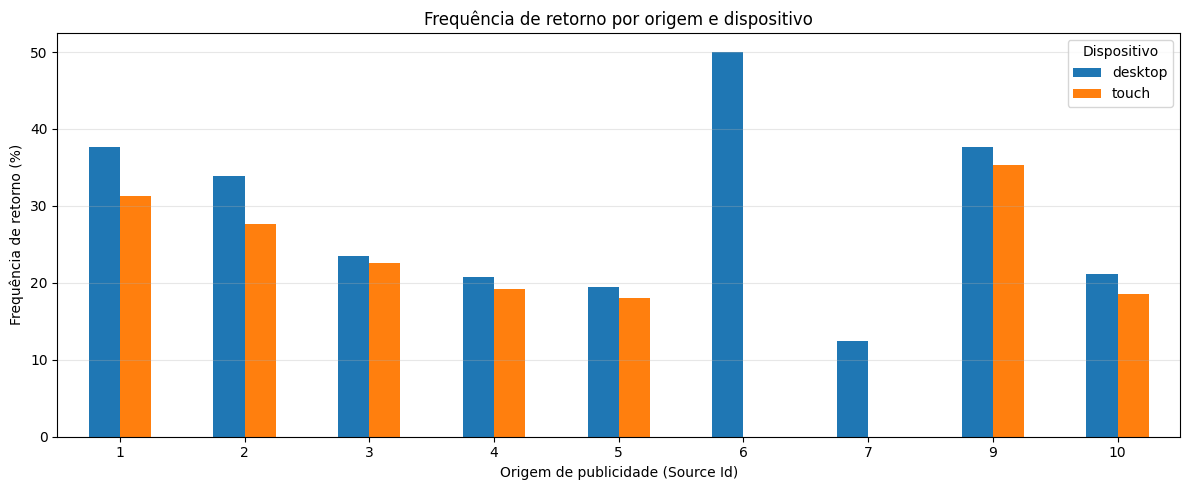

In [40]:
# Visualizar a frequência de retorno por origem e dispositivo
returning_users_summary.pivot(
    index='Source Id',
    columns='Device',
    values='return_rate'
).plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Frequência de retorno por origem e dispositivo')
plt.xlabel('Origem de publicidade (Source Id)')
plt.ylabel('Frequência de retorno (%)')
plt.xticks(rotation=0)
plt.legend(title='Dispositivo')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretação da duração das sessões e frequência de retorno por origem e dispositivo**

A análise conjunta da duração média das sessões e da frequência de retorno permite identificar diferenças importantes no comportamento dos utilizadores adquiridos através das diferentes origens publicitárias e dispositivos.

De forma geral, o **desktop apresenta sessões mais longas e taxas de retorno superiores às do touch** na maioria das origens analisadas.

A **origem 1** destaca-se por combinar uma duração média elevada das sessões com uma frequência de retorno significativa, tanto no desktop como no touch. A **origem 9** também apresenta resultados interessantes, sobretudo pela elevada frequência de retorno, apesar de registar sessões médias mais curtas do que a origem 1.

Por outro lado, a **origem 3**, apesar de apresentar o maior volume de utilizadores adquiridos, regista uma duração média e uma frequência de retorno mais moderadas. Este resultado demonstra que um maior volume de aquisição não implica necessariamente um maior envolvimento ou fidelização dos utilizadores.

É importante salientar que a duração das sessões e a frequência de retorno são indicadores distintos. Uma sessão mais longa não significa obrigatoriamente que o utilizador tenha maior probabilidade de regressar, como demonstram os resultados da origem 9.

As origens 6 e 7 apresentam amostras reduzidas, pelo que os respetivos resultados devem ser interpretados com cautela.

**Conclusão:** a origem 1 apresenta uma combinação particularmente interessante de duração das sessões e frequência de retorno, enquanto a origem 9 se destaca pela capacidade de atrair utilizadores que regressam ao site, mesmo com sessões de menor duração. Estes resultados reforçam a importância de avaliar a qualidade da aquisição para além do número de utilizadores atraídos, considerando também o seu comportamento após a primeira visita.

#### 3.6 DAU, WAU e MAU

In [41]:
# Calcular DAU - utilizadores ativos por dia
dau = df_visits.groupby('session_date')['Uid'].nunique()

# Calcular WAU - utilizadores ativos por semana
wau = df_visits.groupby('session_week')['Uid'].nunique()

# Calcular MAU - utilizadores ativos por mês
mau = df_visits.groupby('session_month')['Uid'].nunique()

In [42]:
# # Apresentar as primeiras observações
print('DAU:')
display(dau.head())

print('WAU:')
display(wau.head())

print('MAU:')
display(mau.head())

DAU:


session_date
2017-06-01    605
2017-06-02    608
2017-06-03    445
2017-06-04    476
2017-06-05    820
Name: Uid, dtype: int64

WAU:


session_week
2017-05-29/2017-06-04    2021
2017-06-05/2017-06-11    4129
2017-06-12/2017-06-18    2812
2017-06-19/2017-06-25    2878
2017-06-26/2017-07-02    3064
Freq: W-SUN, Name: Uid, dtype: int64

MAU:


session_month
2017-06    13259
2017-07    14183
2017-08    11631
2017-09    18975
2017-10    29692
Freq: M, Name: Uid, dtype: int64

#### 3.6.1 Obter valores médios

In [43]:
# Calcular a média de utilizadores ativos
print(f'DAU médio: {dau.mean():.2f}')

print(f'WAU médio: {wau.mean():.2f}')

print(f'MAU médio: {mau.mean():.2f}')

DAU médio: 907.99
WAU médio: 5716.25
MAU médio: 23228.42


#### 3.6.2 Calcular a proporção de utilizadores ativos

In [44]:
# Calcular os Sticky Factors
sticky_wau = dau.mean() / wau.mean() * 100

sticky_mau = dau.mean() / mau.mean() * 100

print(f'Sticky Factor semanal: {sticky_wau:.2f}%')

print(f'Sticky Factor mensal: {sticky_mau:.2f}%')

Sticky Factor semanal: 15.88%
Sticky Factor mensal: 3.91%


#### 3.7 DAU por dispositivo

In [45]:
# Calcular utilizadores ativos diariamente por dispositivo
dau_device = df_visits.groupby(
    ['session_date', 'Device']
)['Uid'].nunique().unstack()

display(dau_device.head())

Device,desktop,touch
session_date,,
2017-06-01,455,153
2017-06-02,458,152
2017-06-03,307,139
2017-06-04,326,153
2017-06-05,631,195


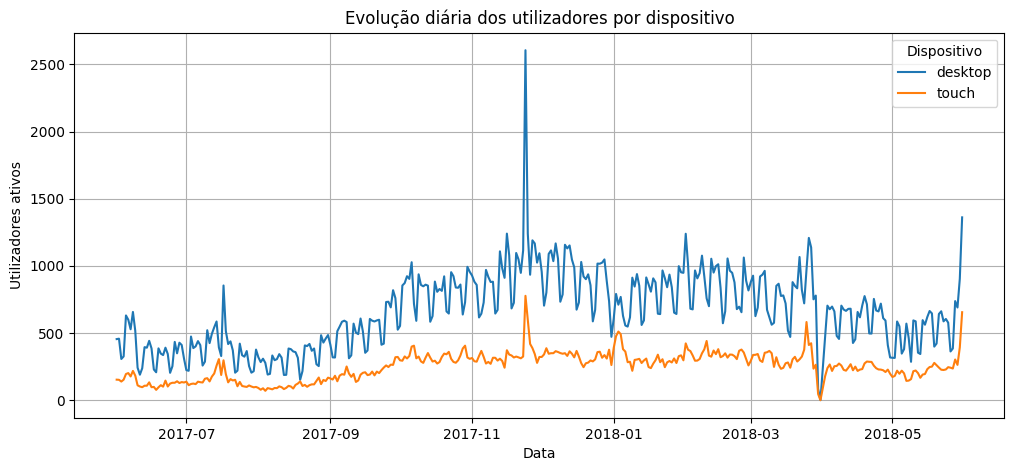

In [46]:
# Visualizar DAU por dispositivo
dau_device.plot(
    figsize=(12, 5)
)

plt.title('Evolução diária dos utilizadores por dispositivo')
plt.xlabel('Data')
plt.ylabel('Utilizadores ativos')
plt.legend(title='Dispositivo')
plt.grid()
plt.show()

#### 3.7.1 DAU por origem de publicidade

In [47]:
# Calcular utilizadores ativos diariamente por origem
dau_source = df_visits.groupby(
    ['session_date', 'Source Id']
)['Uid'].nunique().unstack()

display(dau_source.head())

Source Id,1,2,3,4,5,6,7,9,10
session_date,,,,,,,,,
2017-06-01,61.0,79.0,182.0,138.0,114.0,NaN,NaN,51.0,9.0
2017-06-02,50.0,91.0,179.0,155.0,116.0,NaN,NaN,15.0,21.0
2017-06-03,37.0,60.0,123.0,109.0,87.0,NaN,NaN,22.0,19.0
2017-06-04,44.0,58.0,140.0,113.0,106.0,NaN,NaN,14.0,18.0
2017-06-05,73.0,100.0,264.0,171.0,135.0,NaN,NaN,78.0,33.0


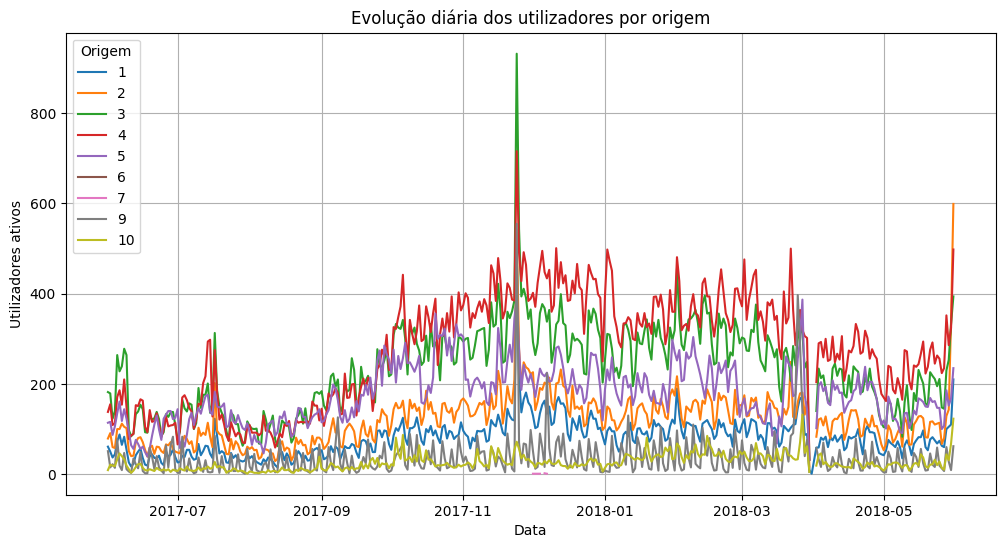

In [48]:
# Visualizar DAU por origem
dau_source.plot(
    figsize=(12, 6)
)

plt.title('Evolução diária dos utilizadores por origem')
plt.xlabel('Data')
plt.ylabel('Utilizadores ativos')
plt.legend(title='Origem')
plt.grid()
plt.show()

#### 3.8 WAU por dispositivo e origem

In [49]:
# WAU por dispositivo
wau_device = df_visits.groupby(
    ['session_week', 'Device']
)['Uid'].nunique().unstack()

# WAU por origem
wau_source = df_visits.groupby(
    ['session_week', 'Source Id']
)['Uid'].nunique().unstack()

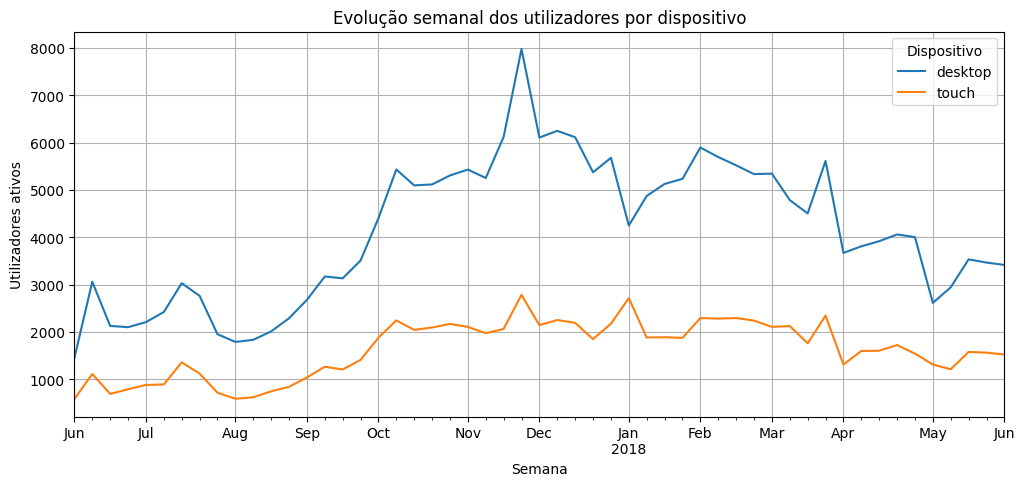

In [50]:
# Visualizar WAU por dispositivo
wau_device.plot(figsize=(12, 5))

plt.title('Evolução semanal dos utilizadores por dispositivo')
plt.xlabel('Semana')
plt.ylabel('Utilizadores ativos')
plt.legend(title='Dispositivo')
plt.grid()
plt.show()

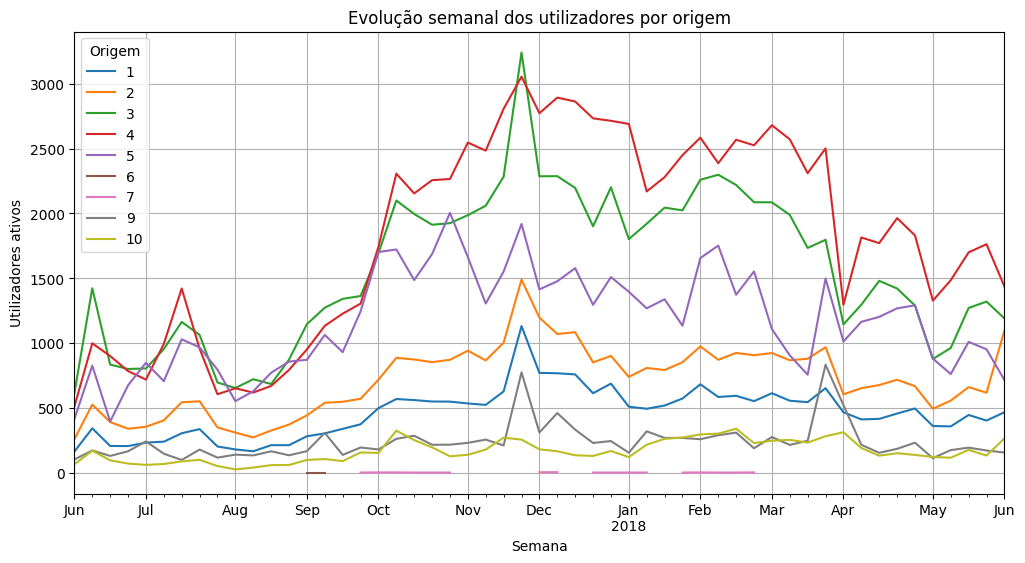

In [51]:
# Visualizar WAU por origem
wau_source.plot(figsize=(12, 6))

plt.title('Evolução semanal dos utilizadores por origem')
plt.xlabel('Semana')
plt.ylabel('Utilizadores ativos')
plt.legend(title='Origem')
plt.grid()
plt.show()

#### 3.9 MAU por dispositivo e origem

In [52]:
# MAU por dispositivo
mau_device = df_visits.groupby(
    ['session_month', 'Device']
)['Uid'].nunique().unstack()

# MAU por origem
mau_source = df_visits.groupby(
    ['session_month', 'Source Id']
)['Uid'].nunique().unstack()

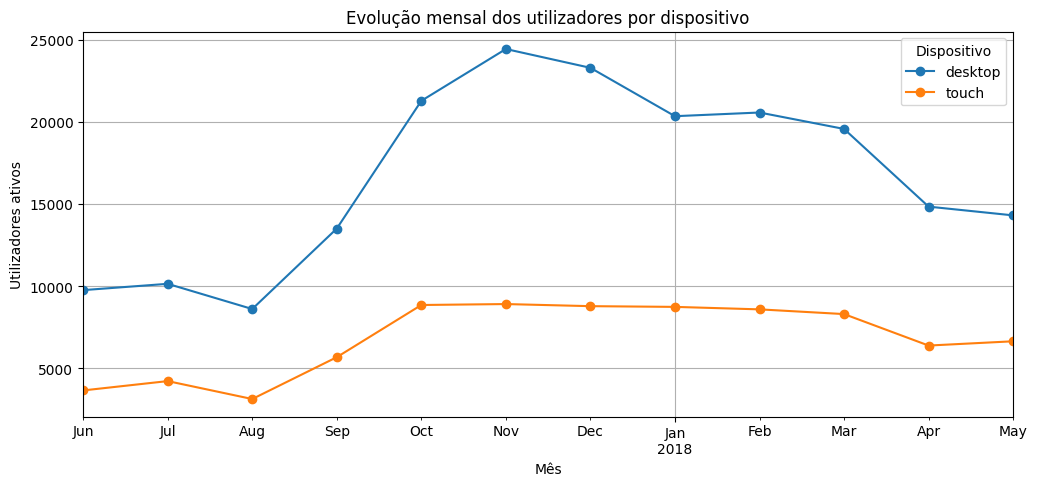

In [53]:
# Visualizar MAU por dispositivo
mau_device.plot(
    figsize=(12, 5),
    marker='o'
)

plt.title('Evolução mensal dos utilizadores por dispositivo')
plt.xlabel('Mês')
plt.ylabel('Utilizadores ativos')
plt.legend(title='Dispositivo')
plt.grid()
plt.show()

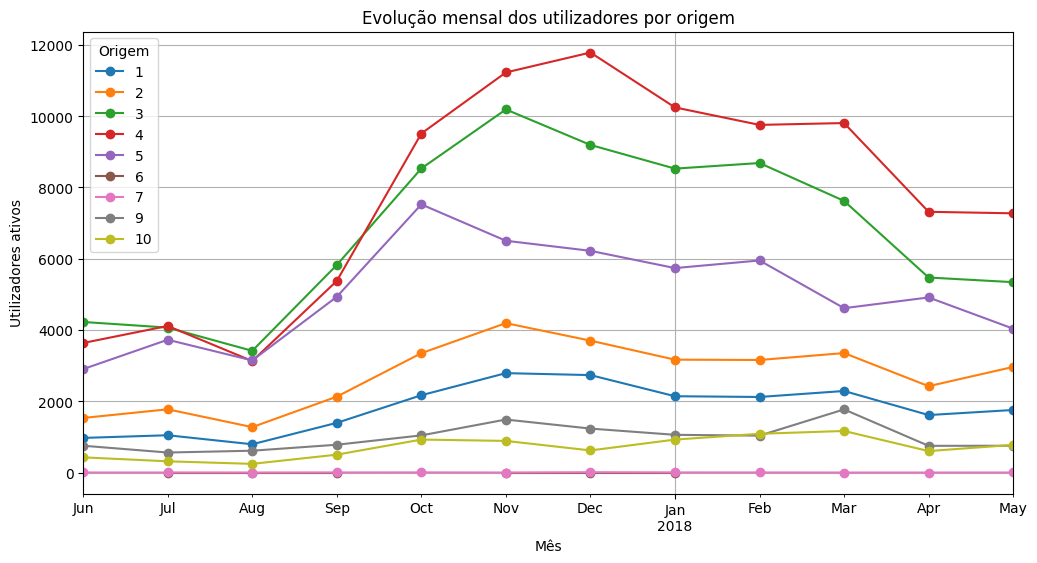

In [54]:
# Vizualizar MAU por origem
mau_source.plot(
    figsize=(12, 6),
    marker='o'
)

plt.title('Evolução mensal dos utilizadores por origem')
plt.xlabel('Mês')
plt.ylabel('Utilizadores ativos')
plt.legend(title='Origem')
plt.grid()
plt.show()

### Interpretação e Conclusão Geral — Análise do Produto

A análise da utilização do produto permitiu identificar padrões importantes relativamente à atividade, duração das sessões, frequência de retorno e distribuição dos utilizadores por dispositivo e origem de publicidade.

**Atividade dos utilizadores (DAU, WAU e MAU)**

Durante o período analisado, registámos uma média de **908 utilizadores ativos diariamente (DAU)**, **5.716 semanalmente (WAU)** e **23.228 mensalmente (MAU)**. Os Sticky Factors foram de **15,88% na periodicidade semanal** e **3,91% na mensal**. Estes resultados mostram que a audiência mensal é consideravelmente superior à utilização diária, sugerindo que existe margem para aumentar a frequência de utilização do produto.

A evolução temporal revela um crescimento significativo da atividade entre setembro e novembro de 2017. O MAU atingiu o seu ponto mais elevado em novembro, seguido de uma redução gradual nos meses seguintes. O DAU e o WAU apresentam igualmente oscilações, com uma tendência de diminuição da atividade durante parte de 2018.

**Sessões e comportamento dos utilizadores**

Registámos uma média de **987,36 sessões por dia** e **1,58 sessões por utilizador** durante o período observado. A mediana foi de apenas uma sessão por utilizador, indicando que pelo menos metade dos utilizadores realizou uma única sessão.

Relativamente à duração, obtivemos uma média de **10,72 minutos** e uma mediana de **5 minutos**. A diferença entre estes valores sugere uma distribuição assimétrica, na qual algumas sessões mais longas influenciam a média.

Verificámos ainda que **22,85% dos utilizadores tiveram mais de uma sessão** durante o período analisado. Este resultado indica que uma parte dos utilizadores regressou ao produto, mas também evidencia uma oportunidade para melhorar a recorrência e o envolvimento da audiência.

**Utilização por dispositivo**

O desktop destacou-se como o principal dispositivo de acesso, com **164.523 utilizadores únicos**, enquanto o touch registou **71.345 utilizadores únicos**.

A evolução mensal mostra que ambos os dispositivos acompanharam o crescimento da atividade durante o segundo semestre de 2017. No entanto, o desktop atingiu um pico de utilização em novembro, seguido de uma diminuição mais acentuada até maio de 2018. O touch apresentou uma evolução mais estável durante parte do período, embora também tenha registado uma redução nos últimos meses.

Estes resultados demonstram a importância do desktop na utilização do produto, sem desvalorizar a participação dos dispositivos touch.

**Utilização por origem de publicidade**

As origens 4 e 3 destacaram-se pelo maior número de utilizadores únicos, com **83.525 e 74.756**, respetivamente. Seguiram-se as origens 5, com 56.974 utilizadores, e 2, com 26.245.

A evolução mensal confirma a predominância das origens 3 e 4, sobretudo durante o período de maior atividade, entre outubro e dezembro de 2017. Contudo, ambas registaram uma redução significativa nos últimos meses analisados.

As origens 1, 2, 5, 9 e 10 apresentaram volumes inferiores, enquanto as origens 6 e 7 tiveram uma participação residual.

**Conclusão de negócio**

Em termos gerais, a análise demonstra que a aplicação conseguiu atrair uma audiência considerável, especialmente através do desktop e das origens de publicidade 3 e 4. Contudo, o crescimento observado durante o segundo semestre de 2017 não se manteve até ao final do período analisado.

A percentagem de utilizadores com mais de uma sessão, de 22,85%, e os Sticky Factors relativamente baixos sugerem oportunidades para melhorar a retenção e incentivar uma utilização mais frequente.

Recomenda-se, por isso, investigar os fatores associados à diminuição da atividade em 2018, melhorar a experiência de utilização nos diferentes dispositivos e desenvolver estratégias que incentivem os utilizadores a regressar ao produto.

Por fim, embora as origens 3 e 4 apresentem os maiores volumes de utilizadores, a sua eficácia comercial deverá ser avaliada conjuntamente com métricas de conversão, LTV, CAC e retorno do investimento, antes de serem tomadas decisões sobre a redistribuição do orçamento de marketing.

## Análise das Vendas
### 4. Quando os utilizadores começam a comprar?

#### 4.1 Primeira visita de cada Utilizador

In [55]:
# Identificar a primeira visita de cada utilizador
first_visits = df_visits.groupby('Uid')['Start Ts'].min()

# Apresentar as primeiras observações
display(first_visits.head())

Uid
11863502262781    2018-03-01 17:27:00
49537067089222    2018-02-06 15:55:00
297729379853735   2017-06-07 18:47:00
313578113262317   2017-09-18 22:49:00
325320750514679   2017-09-30 14:29:00
Name: Start Ts, dtype: datetime64[ns]

#### 4.2 Primeira compra de cada utilizador

In [56]:
# Identificar a primeira compra de cada utilizador
first_orders = df_orders.groupby('Uid')['Buy Ts'].min()

# Apresentar as primeiras observações
display(first_orders.head())

Uid
313578113262317    2018-01-03 21:51:00
1575281904278712   2017-06-03 10:13:00
2429014661409475   2017-10-11 18:33:00
2464366381792757   2018-01-28 15:54:00
2551852515556206   2017-11-24 10:14:00
Name: Buy Ts, dtype: datetime64[ns]

#### 4.3 Calcular o tempo até à primeira compra

In [57]:
# Combinar a primeira visita e a primeira compra de cada utilizador
conversion = pd.concat([first_visits, first_orders], axis=1)

# Verificar o resultado
display(conversion.head())

,Start Ts,Buy Ts
Uid,,
11863502262781,2018-03-01 17:27:00,NaT
49537067089222,2018-02-06 15:55:00,NaT
297729379853735,2017-06-07 18:47:00,NaT
313578113262317,2017-09-18 22:49:00,2018-01-03 21:51:00
325320750514679,2017-09-30 14:29:00,NaT


In [58]:
# Calcular o tempo entre a primeira visita e a primeira compra
conversion['conversion_time'] = (
    conversion['Buy Ts'] - conversion['Start Ts']
)

# Verificar o resultado
display(conversion.head())

,Start Ts,Buy Ts,conversion_time
Uid,,,
11863502262781,2018-03-01 17:27:00,NaT,NaT
49537067089222,2018-02-06 15:55:00,NaT,NaT
297729379853735,2017-06-07 18:47:00,NaT,NaT
313578113262317,2017-09-18 22:49:00,2018-01-03 21:51:00,106 days 23:02:00
325320750514679,2017-09-30 14:29:00,NaT,NaT


#### 4.4 Calcular o tempo de conversão em dias

In [59]:
# Converter o tempo de conversão em dias
conversion['conversion_days'] = conversion['conversion_time'].dt.days

# Verificar o resultado
display(conversion.head())

,Start Ts,Buy Ts,conversion_time,conversion_days
Uid,,,,
11863502262781,2018-03-01 17:27:00,NaT,NaT,NaN
49537067089222,2018-02-06 15:55:00,NaT,NaT,NaN
297729379853735,2017-06-07 18:47:00,NaT,NaT,NaN
313578113262317,2017-09-18 22:49:00,2018-01-03 21:51:00,106 days 23:02:00,106.0
325320750514679,2017-09-30 14:29:00,NaT,NaT,NaN


#### 4.5 Analisar o tempo de conversão

In [60]:
# Calcular estatísticas do tempo de conversão
print(f"Tempo médio: {conversion['conversion_days'].mean():.2f} dias")

print(f"Tempo mediano: {conversion['conversion_days'].median():.2f} dias")

print(f"Tempo mínimo: {conversion['conversion_days'].min():.2f} dias")

Tempo médio: 16.73 dias
Tempo mediano: 0.00 dias
Tempo mínimo: 0.00 dias


#### 4.6 Calcular a taxa de conversão geral

Até agora, analisámos o tempo necessário para os utilizadores realizarem a primeira compra, considerando apenas aqueles que efetivamente se tornaram clientes.

Agora vamos calcular a taxa de conversão geral, ou seja, a percentagem de visitantes únicos que realizaram pelo menos uma compra durante o período analisado.

Para isso, vamos comparar o número de compradores únicos com o número total de visitantes únicos.

In [61]:
# Calcular o número total de visitantes e compradores únicos
total_visitors = df_visits['Uid'].nunique()

total_buyers = df_orders['Uid'].nunique()

# Calcular a taxa de conversão geral
conversion_rate = (total_buyers / total_visitors) * 100

# Apresentar os resultados
print(f'Total de visitantes únicos: {total_visitors}')
print(f'Total de compradores únicos: {total_buyers}')
print(f'Taxa de conversão geral: {conversion_rate:.2f}%')


Total de visitantes únicos: 228169
Total de compradores únicos: 36523
Taxa de conversão geral: 16.01%


#### 4.7 Analisar a conversão por período de tempo

Agora vamos analisar a rapidez com que os visitantes se transformam em clientes.

Para isso, vamos calcular a percentagem acumulada de compradores que realizaram a primeira compra em até 0, 1, 7 e 30 dias após a primeira visita.

Esta análise permitirá identificar a rapidez da conversão e perceber que proporção dos visitantes se transforma em cliente nos primeiros dias de contacto com o site.

In [62]:
# Definir o número total de visitantes e compradores
total_visitors = len(conversion)

total_buyers = conversion['conversion_days'].notna().sum()

# Definir os períodos de conversão em dias
periods = [0, 1, 7, 30]

# Calcular as conversões acumuladas
for days in periods:
    buyers_converted = conversion['conversion_days'].le(days).sum()

    # Percentagem em relação aos compradores
    buyer_percentage = (buyers_converted / total_buyers) * 100

    # Percentagem em relação a todos os visitantes
    visitor_percentage = (buyers_converted / total_visitors) * 100

    print(f'Conversão até {days} dia(s):')
    print(f'Compradores: {buyers_converted}')
    print(f'% dos compradores: {buyer_percentage:.2f}%')
    print(f'% dos visitantes: {visitor_percentage:.2f}%')
    print('-' * 40)

Conversão até 0 dia(s):
Compradores: 26363
% dos compradores: 72.18%
% dos visitantes: 11.55%
----------------------------------------
Conversão até 1 dia(s):
Compradores: 27374
% dos compradores: 74.95%
% dos visitantes: 12.00%
----------------------------------------
Conversão até 7 dia(s):
Compradores: 29443
% dos compradores: 80.61%
% dos visitantes: 12.90%
----------------------------------------
Conversão até 30 dia(s):
Compradores: 31621
% dos compradores: 86.58%
% dos visitantes: 13.86%
----------------------------------------


**Interpretação e conclusão — Conversão por período de tempo**

A análise demonstra que a maioria dos compradores realiza a primeira compra pouco tempo depois da primeira visita ao site.

- **Conversão rápida:** 72,18% dos compradores realizaram a primeira compra em menos de 24 horas.
- **Conversão até 7 dias:** 80,61% dos compradores já tinham convertido neste período.
- **Conversão até 30 dias:** 86,58% dos compradores realizaram a primeira compra nos primeiros 30 dias.

Quando consideramos todos os visitantes, verificamos que apenas 11,55% se tornam compradores em menos de 24 horas e 13,86% nos primeiros 30 dias.

**Dedução:** os resultados indicam que a maioria dos clientes que efetivamente compram apresenta um processo de decisão relativamente rápido. No entanto, existe uma diferença significativa entre o número total de visitantes e o número de compradores, o que evidencia uma oportunidade para melhorar a conversão de visitantes em clientes.

Será importante investigar se a rapidez e a taxa de conversão variam consoante a origem do anúncio e o dispositivo utilizado, permitindo identificar os canais que atraem visitantes com maior probabilidade de compra.

<div class="alert alert-block alert-success">

A conversão cumulativa em 0, 1, 7 e 30 dias está bem feita. O uso de dois denominadores, compradores (72,18% a 86,58%) e todos os visitantes (11,55% a 13,86%), separa a rapidez com que os compradores decidem de quão poucos visitantes realmente compram, e a sua interpretação condiz com os números. Opcionalmente, evite reutilizar os nomes total visitors e total buyers com um significado diferente do da célula anterior.

</div>

#### 4.8 Analisar a taxa de conversão por origem de publicidade e dispositivo
#### 4.8.1 Preparar os dados
Há um pormenor importante: um utilizador pode visitar o site várias vezes, utilizando diferentes dispositivos ou origens de publicidade.

Para evitar contar o mesmo utilizador várias vezes, vamos atribuir-lhe a origem e o dispositivo da sua primeira visita.

Também vamos identificar quais desses visitantes realizaram pelo menos uma compra.

In [63]:
# Identificar a primeira visita de cada utilizador,
# mantendo a origem do anúncio e o dispositivo

first_visits_detail = (
    df_visits
    .sort_values('Start Ts')
    .drop_duplicates('Uid')
)

# Identificar os utilizadores que realizaram compras
buyers = df_orders[['Uid']].drop_duplicates().copy()

buyers['converted'] = 1

# Combinar os visitantes com a informação dos compradores
visitor_conversion = first_visits_detail.merge(
    buyers,
    on='Uid',
    how='left'
)

# Identificar os utilizadores que não realizaram compras
visitor_conversion['converted'] = (
    visitor_conversion['converted'].fillna(0).astype(int)
)

# Verificar o resultado
display(visitor_conversion.head())

,Device,End Ts,Source Id,Start Ts,Uid,session_date,session_week,session_month,session_duration_min,converted
0,desktop,2017-06-01 00:02:00,5,2017-06-01 00:01:00,13890188992670018146,2017-06-01,2017-05-29/2017-06-04,2017-06,1.0,0
1,desktop,2017-06-01 00:02:00,3,2017-06-01 00:02:00,16152015161748786004,2017-06-01,2017-05-29/2017-06-04,2017-06,0.0,0
2,desktop,2017-06-01 00:16:00,3,2017-06-01 00:02:00,16706502037388497502,2017-06-01,2017-05-29/2017-06-04,2017-06,14.0,0
3,desktop,2017-06-01 00:04:00,3,2017-06-01 00:04:00,8842918131297115663,2017-06-01,2017-05-29/2017-06-04,2017-06,0.0,0
4,desktop,2017-06-01 00:11:00,1,2017-06-01 00:09:00,10329302124590727494,2017-06-01,2017-05-29/2017-06-04,2017-06,2.0,1


#### 4.8.2 Calcular a conversão por origem de publicidade
Vamos calcular o número de visitantes únicos, o número de compradores e a respetiva taxa de conversão para cada origem de publicidade.

In [64]:
# Calcular a conversão por origem de publicidade
conversion_by_source = visitor_conversion.groupby('Source Id').agg(
    visitors=('Uid', 'nunique'),
    buyers=('converted', 'sum')
)

# Calcular a taxa de conversão em percentagem
conversion_by_source['conversion_rate'] = (
    conversion_by_source['buyers'] /
    conversion_by_source['visitors'] * 100
)

# Ordenar pela taxa de conversão
conversion_by_source = conversion_by_source.sort_values(
    'conversion_rate',
    ascending=False
)

# Apresentar os resultados
display(conversion_by_source)

,visitors,buyers,conversion_rate
Source Id,,,
1,9469,2899,30.615693
2,17616,3506,19.902361
10,6903,1329,19.252499
9,6448,1088,16.873449
3,66116,10473,15.840341
4,72346,10296,14.231609
5,49237,6931,14.076812
7,32,1,3.125000
6,2,0,0.000000


#### 4.8.3 Visualizar a conversão por origem de publicidade
Vamos construir um gráfico de barras para comparar visualmente as taxas de conversão das diferentes origens de publicidade.

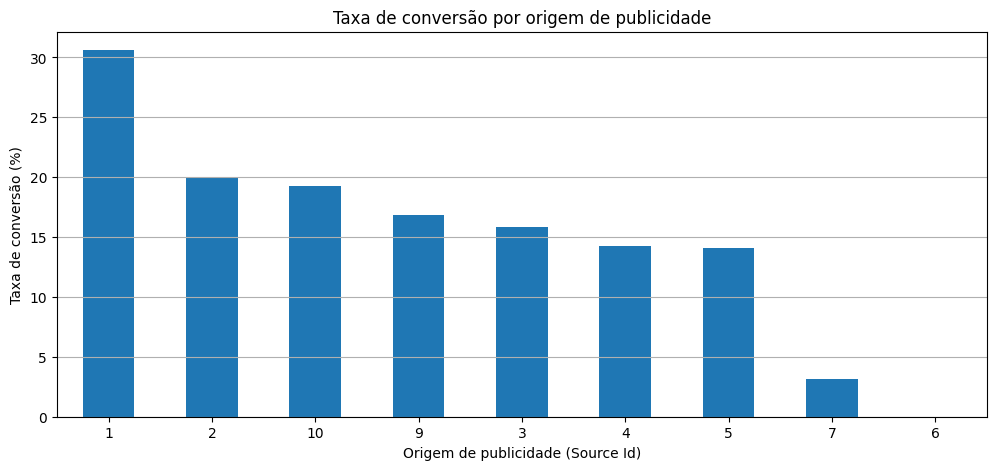

In [65]:
# Visualizar a taxa de conversão por origem de publicidade
conversion_by_source['conversion_rate'].plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Taxa de conversão por origem de publicidade')
plt.xlabel('Origem de publicidade (Source Id)')
plt.ylabel('Taxa de conversão (%)')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

#### 4.8.4 Calcular a conversão por dispositivo
Agora vamos repetir a análise, mas desta vez agrupando os utilizadores pelo dispositivo utilizado na primeira visita.

Isto permitirá comparar a eficácia da conversão entre os diferentes dispositivos.

In [66]:
# Calcular a conversão por dispositivo
conversion_by_device = visitor_conversion.groupby('Device').agg(
    visitors=('Uid', 'nunique'),
    buyers=('converted', 'sum')
)

# Calcular a taxa de conversão em percentagem
conversion_by_device['conversion_rate'] = (
    conversion_by_device['buyers'] /
    conversion_by_device['visitors'] * 100
)

# Ordenar pela taxa de conversão
conversion_by_device = conversion_by_device.sort_values(
    'conversion_rate',
    ascending=False
)

# Apresentar os resultados
display(conversion_by_device)

,visitors,buyers,conversion_rate
Device,,,
desktop,160795,29211,18.166610
touch,67374,7312,10.852851


#### 4.8.5 Visualizar a conversão por dispositivo
Vamos utilizar um gráfico de barras para comparar as taxas de conversão entre os dispositivos.

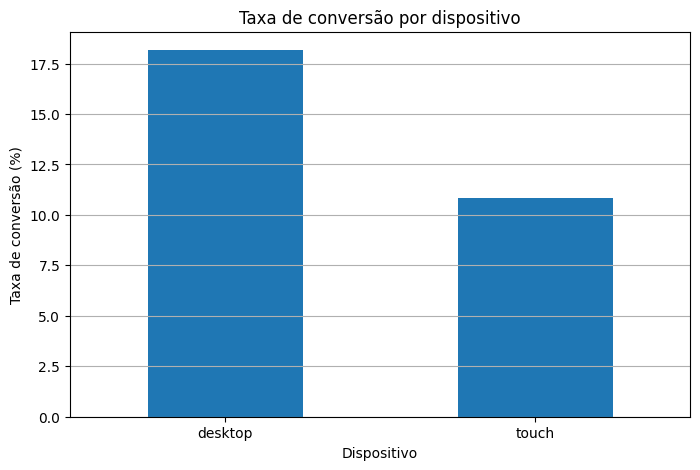

In [67]:
# Visualizar a taxa de conversão por dispositivo
conversion_by_device['conversion_rate'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Taxa de conversão por dispositivo')
plt.xlabel('Dispositivo')
plt.ylabel('Taxa de conversão (%)')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

**Interpretação e conclusão — Conversão por origem de publicidade e dispositivo**

A análise da taxa de conversão por origem de publicidade revelou diferenças significativas no desempenho dos canais de aquisição.

- **Origem 1:** apresentou a maior taxa de conversão, com aproximadamente 30,62%.
- **Origens 2 e 10:** também demonstraram um desempenho interessante, com taxas próximas de 20%.
- **Origens 3, 4 e 5:** atraíram um elevado volume de visitantes, mas apresentaram taxas de conversão inferiores, entre 14% e 16%.
- **Origens 6 e 7:** apresentaram um número demasiado reduzido de visitantes para permitir conclusões fiáveis.

Na comparação por dispositivo, verificámos que os utilizadores de desktop apresentam uma taxa de conversão de 18,17%, superior aos 10,85% registados nos dispositivos touch. Isto significa que a conversão no desktop é aproximadamente 1,67 vezes superior à conversão nos dispositivos touch.

**Dedução:** os resultados demonstram que tanto a origem de publicidade como o dispositivo estão associados a diferenças relevantes no comportamento de compra. A origem 1 destaca-se pela sua capacidade de transformar visitantes em compradores, enquanto o desktop apresenta melhores resultados de conversão do que os dispositivos touch.

Estes resultados justificam uma investigação mais aprofundada sobre o desempenho combinado das origens de publicidade e dos dispositivos. No entanto, a taxa de conversão, isoladamente, não permite determinar quais os canais mais rentáveis, sendo também necessário considerar os custos de aquisição e a receita gerada.

#### 4.8.6 Analisar a conversão por origem de publicidade e dispositivo
Vamos combinar as duas dimensões para identificar diferenças na taxa de conversão entre as origens de publicidade e os dispositivos utilizados.
Esta análise permitirá identificar quais as combinações que apresentam melhores resultados.

In [68]:
# Calcular a conversão por origem de publicidade e dispositivo
conversion_by_source_device = visitor_conversion.groupby(
    ['Source Id', 'Device']
).agg(
    visitors=('Uid', 'nunique'),
    buyers=('converted', 'sum')
)

# Calcular a taxa de conversão em percentagem
conversion_by_source_device['conversion_rate'] = (
    conversion_by_source_device['buyers'] /
    conversion_by_source_device['visitors'] * 100
)

# Apresentar os resultados
display(conversion_by_source_device)

visitors  buyers  conversion_rate
Source Id Device                                    
1         desktop      6347    2264        35.670395
          touch        3122     635        20.339526
2         desktop     11771    2649        22.504460
          touch        5845     857        14.662104
3         desktop     50190    8724        17.381949
          touch       15926    1749        10.982042
4         desktop     46965    7932        16.889173
          touch       25381    2364         9.314054
5         desktop     35822    5705        15.925967
          touch       13415    1226         9.139023
6         desktop         2       0         0.000000
          touch           0       0              NaN
7         desktop        24       1         4.166667
          touch           8       0         0.000000
9         desktop      4828     892        18.475559
          touch        1620     196        12.098765
10        desktop      4846    1044        21.543541
          touch        2057     285        13.855129

#### 4.8.7 Construir uma tabela comparativa
Para facilitar a comparação, vamos reorganizar os resultados numa tabela em que cada origem de publicidade apresenta a taxa de conversão correspondente a cada dispositivo.

In [69]:
# Criar uma tabela comparativa da taxa de conversão
conversion_pivot = conversion_by_source_device.pivot_table(
    index='Source Id',
    columns='Device',
    values='conversion_rate'
)

# Apresentar a tabela
display(conversion_pivot.round(2))

Device,desktop,touch
Source Id,,
1,35.67,20.34
2,22.50,14.66
3,17.38,10.98
4,16.89,9.31
5,15.93,9.14
6,0.00,NaN
7,4.17,0.00
9,18.48,12.10
10,21.54,13.86


#### 4.8.8 Visualizar a comparação
Vamos construir um gráfico de barras agrupadas para comparar a taxa de conversão de desktop e touch em cada origem de publicidade.

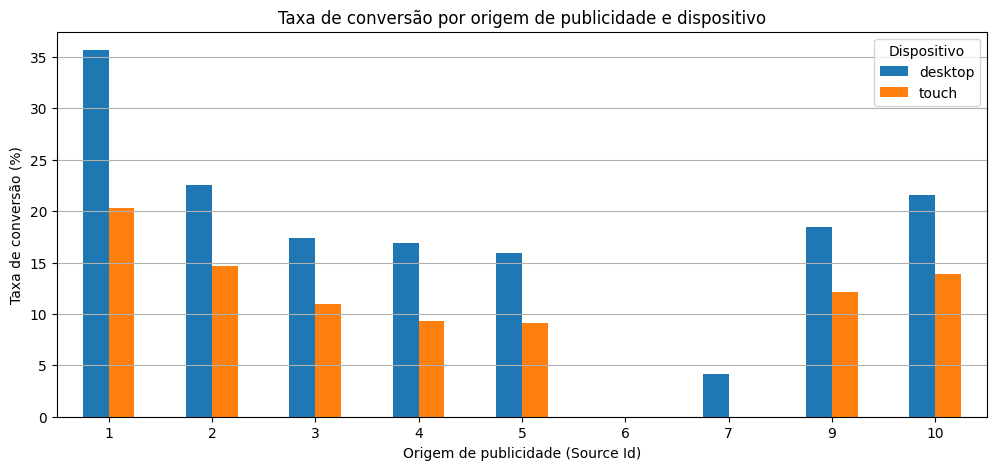

In [70]:
# Visualizar a conversão por origem e dispositivo
conversion_pivot.plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Taxa de conversão por origem de publicidade e dispositivo')
plt.xlabel('Origem de publicidade (Source Id)')
plt.ylabel('Taxa de conversão (%)')
plt.xticks(rotation=0)
plt.legend(title='Dispositivo')
plt.grid(axis='y')
plt.show()

**Interpretação e conclusão — Conversão por origem de publicidade e dispositivo**

A análise conjunta das origens de publicidade e dos dispositivos revelou diferenças importantes nas taxas de conversão.

A origem 1 apresentou o melhor desempenho em ambos os dispositivos, com uma taxa de conversão de 35,67% no desktop e 20,34% no touch, destacando-se claramente das restantes origens.

Verificou-se também que o desktop apresenta taxas de conversão superiores às do touch em todas as origens com dados disponíveis para ambos os dispositivos. Este resultado sugere que os visitantes provenientes de computadores apresentam maior probabilidade de realizar uma compra.

As origens 2 e 10 também demonstraram resultados relativamente positivos, enquanto as origens 3, 4 e 5 apresentaram taxas de conversão mais moderadas.

Por outro lado, as origens 6 e 7 apresentam um número muito reduzido de visitantes, pelo que os seus resultados não permitem avaliações consistentes.

**Em síntese**, a origem 1 destaca-se pela sua capacidade de conversão, independentemente do dispositivo utilizado, e o desktop apresenta melhores resultados do que o touch. Estas diferenças devem ser consideradas na avaliação das estratégias de aquisição de clientes. Contudo, a escolha das origens em que investir deverá também ter em conta os custos de aquisição e o retorno financeiro, que serão analisados na secção de Marketing.

### 5. Quantos pedidos os clientes fazem durante um determinado período de tempo?

#### 5.1 Calcular o número de pedidos por cliente

In [71]:
# Calcular o número de pedidos por cliente
orders_per_user = df_orders.groupby('Uid').size()

# Apresentar as primeiras observações
display(orders_per_user.head())

Uid
313578113262317     1
1575281904278712    2
2429014661409475    1
2464366381792757    1
2551852515556206    2
dtype: int64

#### 5.2 Calcular as estatísticas do número de pedidos

In [72]:
# Calcular as esátisticas dos pedidos por cliente
print(f"Pedidos médios: {orders_per_user.mean():.2f}")

print(f"Pedidos medianos: {orders_per_user.median():.2f}")

print(f"Pedidos mínimos: {orders_per_user.min()}")

print(f"Pedidos máximos: {orders_per_user.max()}")

Pedidos médios: 1.38
Pedidos medianos: 1.00
Pedidos mínimos: 1
Pedidos máximos: 239


**Interpretação**

- Em média, cada cliente realizou 1,38 pedidos durante o período analisado.

- Pelo menos metade dos clientes realizou apenas um pedido. Isto sugere uma baixa frequência de compras recorrentes.

- Todos os clientes incluídos nesta análise realizaram pelo menos uma compra, o que é esperado porque estamos a analisar clientes identificados a partir da tabela de pedidos.

- Existe pelo menos um cliente com 239 pedidos. É um valor bastante superior ao comportamento típico e poderá representar um cliente particularmente ativo ou um caso atípico.

**Dedução:** A diferença entre a média (1,38) e a mediana (1) sugere uma distribuição assimétrica à direita. Ou seja, a maioria dos clientes realiza poucas compras, enquanto um grupo reduzido apresenta uma frequência de compra muito superior.

Este comportamento merece ser investigado porque os clientes recorrentes podem representar uma parcela importante da receita da empresa.

#### 5.3 Visualizar a distribuição

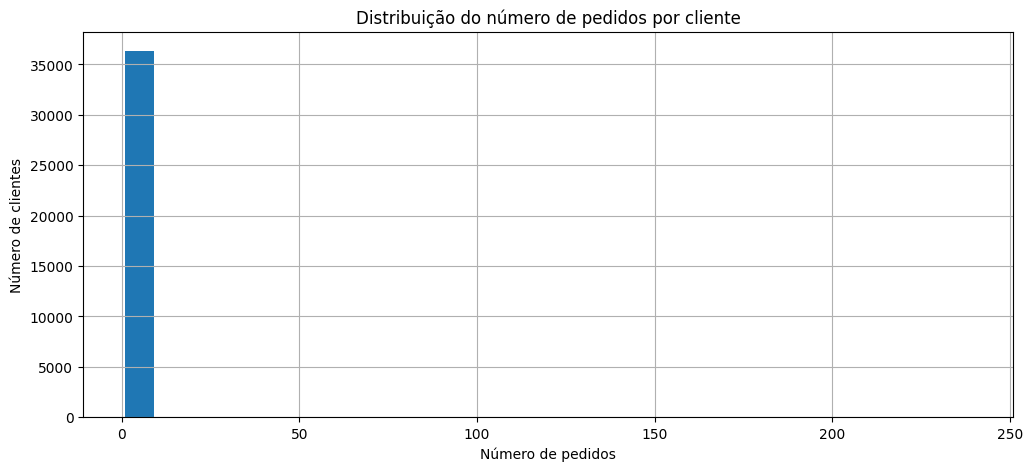

In [73]:
# Visualizar a distribuição do número de pedidos por cliente
orders_per_user.hist(bins=30, figsize=(12, 5))

plt.title('Distribuição do número de pedidos por cliente')
plt.xlabel('Número de pedidos')
plt.ylabel('Número de clientes')
plt.show()

#### 5.4 Uma melhoria na visualização
O gráfico atual apresenta uma limitação: o valor máximo de 239 pedidos faz com que a maior parte dos clientes fique concentrada numa pequena região do eixo horizontal.

Para compreender melhor o comportamento da maioria, vamos construir uma segunda visualização, excluindo temporariamente os clientes com mais de 10 pedidos.

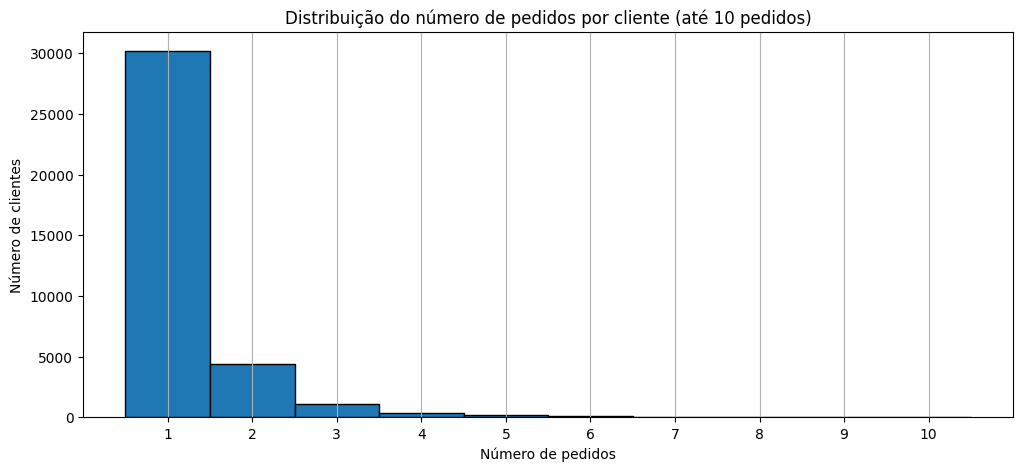

Clientes excluídos da visualização: 123


In [74]:
# Identificar os clientes com mais de 10 pedidos
clients_excluded = (orders_per_user > 10).sum()

# Visualizar a distribuição dos clientes com até 10 pedidos
orders_per_user[orders_per_user <= 10].hist(
    bins=np.arange(0.5, 11.5, 1),
    figsize=(12, 5),
    edgecolor='black'
)

plt.title('Distribuição do número de pedidos por cliente (até 10 pedidos)')
plt.xlabel('Número de pedidos')
plt.ylabel('Número de clientes')
plt.xticks(range(1, 11))
plt.grid(axis='y')
plt.show()

# Apresentar o número de clientes excluídos
print(f'Clientes excluídos da visualização: {clients_excluded}')

**Identificamos três padrões:**

- **Predominância de clientes ocasionais** — A maior concentração encontra-se nos clientes que realizaram apenas um pedido. Isto reforça a conclusão de que a maioria dos clientes não apresenta um comportamento de compra recorrente.

- **Redução acentuada da frequência** — À medida que aumenta o número de pedidos, diminui significativamente a quantidade de clientes.

- **Pequeno grupo de clientes recorrentes** — Existe um grupo reduzido de clientes que realiza entre 2 e 10 pedidos. Estes clientes apresentam maior frequência de compra e poderão ter um contributo importante para a receita.

#### 5.5 Calcular o número de pedidos por mês

In [75]:
# Extrair o ano e o mês de cada pedido
df_orders['order_year'] = df_orders['Buy Ts'].dt.year

df_orders['order_month'] = df_orders['Buy Ts'].dt.month

# Calcular o número de pedidos por ano e mês
monthly_orders = df_orders.groupby(
    ['order_year', 'order_month']
).size()

# Apresentar as primeiras observações
display(monthly_orders.head())

order_year  order_month
2017        6              2354
            7              2363
            8              1807
            9              3387
            10             5679
dtype: int64

#### 5.6 Analisar a frequência de pedidos por coorte, dispositivo e origem de publicidade
Até agora, analisámos o número de pedidos por cliente e a evolução mensal do volume total de pedidos. No entanto, os clientes foram adquiridos em momentos diferentes e, por isso, tiveram períodos de atividade distintos.

Para realizar uma comparação mais justa, vamos organizar os clientes em coortes, de acordo com o mês da primeira visita, e acompanhar o número de pedidos ao longo dos meses seguintes.

Também vamos segmentar os resultados por dispositivo e origem de publicidade, permitindo identificar quais os grupos de clientes que apresentam maior frequência de compras.

#### 5.6.1 Preparar os dados das coortes

In [76]:
# Selecionar os dados da primeira visita de cada cliente
customer_cohorts = first_visits_detail[
    ['Uid', 'Device', 'Source Id', 'Start Ts']
].copy()

# Garantir o formato datetime
customer_cohorts['Start Ts'] = pd.to_datetime(
    customer_cohorts['Start Ts']
)

# Identificar o ano e o mês da primeira visita
customer_cohorts['cohort_year'] = (
    customer_cohorts['Start Ts'].dt.year
)

customer_cohorts['cohort_month'] = (
    customer_cohorts['Start Ts'].dt.month
)

# Identificar os clientes que realizaram pelo menos uma compra
buyers_cohorts = customer_cohorts.merge(
    df_orders[['Uid']].drop_duplicates(),
    on='Uid',
    how='inner'
)

# Verificar o resultado
display(buyers_cohorts.head())

,Uid,Device,Source Id,Start Ts,cohort_year,cohort_month
0,10329302124590727494,desktop,1,2017-06-01 00:09:00,2017,6
1,16109239769442553005,desktop,2,2017-06-01 00:14:00,2017,6
2,11627257723692907447,desktop,2,2017-06-01 00:14:00,2017,6
3,17903680561304213844,desktop,2,2017-06-01 00:25:00,2017,6
4,16945437833757229838,desktop,2,2017-06-01 01:18:00,2017,6


#### 5.6.2 Associar os pedidos às coortes

In [77]:
# Associar cada pedido à coorte, dispositivo e origem de publicidade
orders_cohorts_analysis = df_orders.merge(
    customer_cohorts,
    on='Uid',
    how='inner'
)

# Extrair o ano e o mês de cada pedido
orders_cohorts_analysis['order_year'] = (
    orders_cohorts_analysis['Buy Ts'].dt.year
)

orders_cohorts_analysis['order_month'] = (
    orders_cohorts_analysis['Buy Ts'].dt.month
)

# Calcular a idade da coorte em meses
orders_cohorts_analysis['cohort_age'] = (
    (orders_cohorts_analysis['order_year'] -
     orders_cohorts_analysis['cohort_year']) * 12
    +
    (orders_cohorts_analysis['order_month'] -
     orders_cohorts_analysis['cohort_month'])
)

# Verificar o resultado
display(orders_cohorts_analysis.head())

,Buy Ts,Revenue,Uid,order_year,order_month,Device,Source Id,Start Ts,cohort_year,cohort_month,cohort_age
0,2017-06-01 00:10:00,17.00,10329302124590727494,2017,6,desktop,1,2017-06-01 00:09:00,2017,6,0
1,2017-06-01 00:25:00,0.55,11627257723692907447,2017,6,desktop,2,2017-06-01 00:14:00,2017,6,0
2,2017-06-01 00:27:00,0.37,17903680561304213844,2017,6,desktop,2,2017-06-01 00:25:00,2017,6,0
3,2017-06-01 00:29:00,0.55,16109239769442553005,2017,6,desktop,2,2017-06-01 00:14:00,2017,6,0
4,2017-06-01 07:58:00,0.37,14200605875248379450,2017,6,desktop,3,2017-06-01 07:31:00,2017,6,0


#### 5.6.3 Calcular o número de pedidos por coorte

In [78]:
# Contar todos os utilizadores adquiridos por coorte, dispositivo e origem
cohort_users_size = customer_cohorts.groupby(
    ['cohort_year', 'cohort_month', 'Device', 'Source Id'],
    observed=True
)['Uid'].nunique().reset_index(name='cohort_users')

# Calcular o total de pedidos por coorte, idade, dispositivo e origem
cohort_orders_count = orders_cohorts_analysis.groupby(
    ['cohort_year', 'cohort_month', 'cohort_age', 'Device', 'Source Id'],
    observed=True
).size().reset_index(name='total_orders')

# Associar o número total de utilizadores a cada grupo
cohort_orders_count = cohort_orders_count.merge(
    cohort_users_size,
    on=['cohort_year', 'cohort_month', 'Device', 'Source Id'],
    how='left'
)

# Calcular a média de pedidos por utilizador adquirido
cohort_orders_count['avg_orders_per_user'] = (
    cohort_orders_count['total_orders'] /
    cohort_orders_count['cohort_users']
)

# Verificar os resultados
display(cohort_orders_count.head(10))


,cohort_year,cohort_month,cohort_age,Device,Source Id,total_orders,cohort_users,avg_orders_per_user
0,2017,6,0,desktop,1,233,449,0.518931
1,2017,6,0,desktop,2,235,909,0.258526
2,2017,6,0,desktop,3,618,3205,0.192824
3,2017,6,0,desktop,4,384,2353,0.163196
4,2017,6,0,desktop,5,377,1936,0.194731
5,2017,6,0,desktop,9,70,543,0.128913
6,2017,6,0,desktop,10,77,279,0.275986
7,2017,6,0,touch,1,35,182,0.192308
8,2017,6,0,touch,2,46,353,0.130312
9,2017,6,0,touch,3,86,875,0.098286


#### 5.6.4 Visualizar a evolução
#### 5.6.4.1 Evolução dos pedidos por coorte e dispositivo

Vamos analisar a evolução da média de pedidos por comprador ao longo da idade das coortes, distinguindo os dispositivos utilizados (desktop e touch).

Para facilitar a comparação, construiremos dois mapas de calor: um para desktop e outro para touch.

As linhas representam as coortes de aquisição, as colunas representam a idade da coorte em meses e os valores indicam a média de pedidos por comprador.

Último mês completo: 2018-05


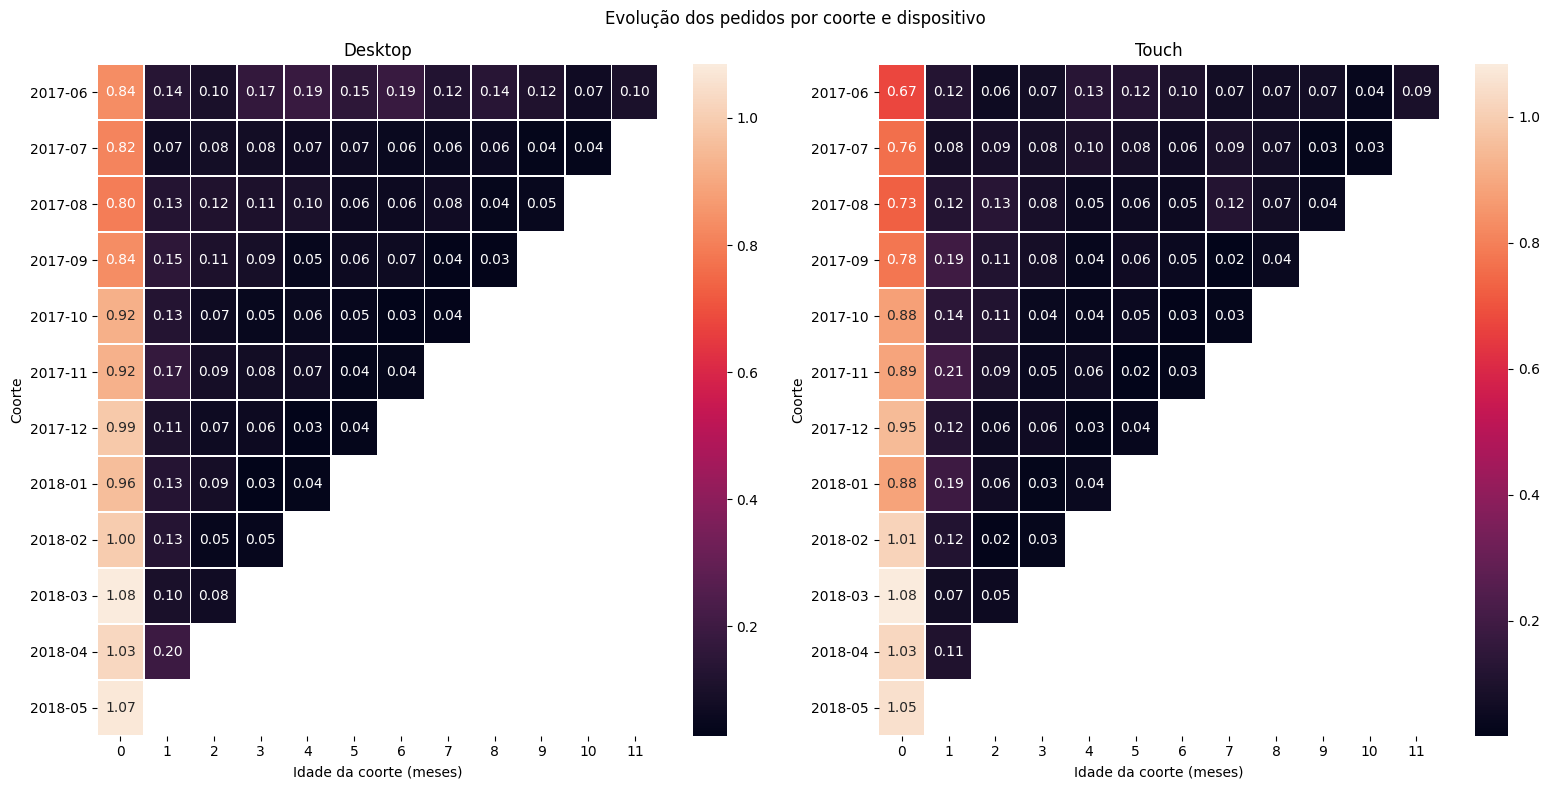

In [79]:
# Agrupar o número de pedidos por coorte, idade e dispositivo
cohort_device_orders = orders_cohorts_analysis.groupby(
    ['cohort_year', 'cohort_month', 'cohort_age', 'Device'],
    observed=True
).size().reset_index(name='total_orders')

# Calcular o número total de compradores por coorte e dispositivo
cohort_buyers_device = buyers_cohorts.groupby(
    ['cohort_year', 'cohort_month', 'Device'],
    observed=True
)['Uid'].nunique().reset_index(name='cohort_buyers')


# Identificar o último mês completo de observação
last_complete_year, last_complete_month = monthly_orders.iloc[:-1].index[-1]

print(
    f'Último mês completo: '
    f'{last_complete_year}-{last_complete_month:02d}'
)

# Calcular a idade máxima observável de cada coorte
cohort_buyers_device['max_age'] = (
    (last_complete_year - cohort_buyers_device['cohort_year']) * 12
    +
    (last_complete_month - cohort_buyers_device['cohort_month'])
)

# Criar uma tabela com todas as idades possíveis
max_cohort_age = int(cohort_buyers_device['max_age'].max())

cohort_ages = pd.DataFrame({
    'cohort_age': range(max_cohort_age + 1)
})


# Criar todas as combinações de coorte, dispositivo e idade
cohort_device_grid = cohort_buyers_device.merge(
    cohort_ages,
    how='cross'
)

# Manter apenas os meses já observáveis
cohort_device_grid = cohort_device_grid[
    cohort_device_grid['cohort_age'] <=
    cohort_device_grid['max_age']
]


# Associar o número de pedidos a cada combinação
cohort_device = cohort_device_grid.merge(
    cohort_device_orders,
    on=['cohort_year', 'cohort_month', 'cohort_age', 'Device'],
    how='left'
)

# Substituir por zero os meses observados sem pedidos
cohort_device['total_orders'] = (
    cohort_device['total_orders'].fillna(0)
)

# Calcular a média de pedidos por comprador
cohort_device['avg_orders_per_buyer'] = (
    cohort_device['total_orders'] /
    cohort_device['cohort_buyers']
)

# Identificar cada coorte pelo ano e mês
cohort_device['cohort'] = (
    cohort_device['cohort_year'].astype(str) + '-' +
    cohort_device['cohort_month'].astype(str).str.zfill(2)
)

# Criar tabelas para cada dispositivo
desktop_pivot = cohort_device[
    cohort_device['Device'] == 'desktop'
].pivot_table(
    index='cohort',
    columns='cohort_age',
    values='avg_orders_per_buyer'
)

touch_pivot = cohort_device[
    cohort_device['Device'] == 'touch'
].pivot_table(
    index='cohort',
    columns='cohort_age',
    values='avg_orders_per_buyer'
)

# Ordenar as coortes cronologicamente
desktop_pivot = desktop_pivot.sort_index()
touch_pivot = touch_pivot.sort_index()


# Criar os dois mapas de calor
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

sns.heatmap(
    desktop_pivot,
    annot=True,
    fmt='.2f',
    linewidths=0.5,
    linecolor='white',
    ax=axes[0]
)

axes[0].set_title('Desktop')
axes[0].set_xlabel('Idade da coorte (meses)')
axes[0].set_ylabel('Coorte')

sns.heatmap(
    touch_pivot,
    annot=True,
    fmt='.2f',
    linewidths=0.5,
    linecolor='white',
    ax=axes[1]
)

axes[1].set_title('Touch')
axes[1].set_xlabel('Idade da coorte (meses)')
axes[1].set_ylabel('Coorte')

plt.suptitle('Evolução dos pedidos por coorte e dispositivo')
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-success">

Boa correção. O último mês observável agora vem do último mês completo (2018-05), então cada coorte mostra apenas as idades que realmente poderia alcançar, e a falsa diagonal de valores 0.00 desapareceu. Os heatmaps usam compradores (buyers) como denominador, o que os mantém consistentes. Sua interpretação agora é uma versão única que corresponde à figura (médias iniciais de 0.80–1.08 para desktop e 0.67–1.08 para touch). Uma sugestão: a idade 0 reflete principalmente o primeiro pedido de cada comprador, então baseie a comparação entre dispositivos nas idades 1 e acima, onde o comportamento de recompra aparece.

</div>

**Interpretação e conclusão — Evolução dos pedidos por coorte e dispositivo**

Os mapas de calor permitem analisar a evolução da média de pedidos por comprador ao longo da idade das coortes, distinguindo os dispositivos Desktop e Touch.

A análise evidencia três padrões principais:

- **Frequência inicial de pedidos:** No primeiro mês de observação, o Desktop apresenta, na maioria das coortes, valores ligeiramente superiores aos do Touch. No entanto, as diferenças são reduzidas e, em algumas coortes, os dois dispositivos apresentam valores iguais ou muito próximos. As médias iniciais variam aproximadamente entre 0,80 e 1,08 pedidos por comprador no Desktop e entre 0,67 e 1,08 no Touch.

- **Redução da frequência ao longo do tempo:** Em ambos os dispositivos, observa-se uma tendência geral de diminuição da média de pedidos por comprador à medida que aumenta a idade da coorte. Esta evolução apresenta algumas oscilações, mas os valores tendem a ser mais reduzidos nos meses posteriores à aquisição.

- **Comportamento semelhante entre dispositivos:** Apesar de o Desktop apresentar uma frequência inicial ligeiramente superior na maioria das coortes, os dois dispositivos revelam padrões de evolução semelhantes. Não se observa uma diferença suficientemente expressiva que permita concluir, apenas com esta análise, que um dispositivo proporciona um comportamento de compra claramente superior ao outro.

**Conclusão:**

A análise demonstra que a frequência de pedidos tende a diminuir ao longo do tempo, tanto para os compradores que utilizaram Desktop como para os que utilizaram Touch. Embora o Desktop apresente médias iniciais ligeiramente superiores na maioria das coortes, os resultados indicam um comportamento global semelhante entre os dispositivos.

Estes resultados reforçam a importância de desenvolver estratégias de retenção e incentivo à recompra, independentemente do dispositivo utilizado. Para determinar qual dispositivo gera maior valor financeiro para a empresa, será necessário complementar esta análise com os indicadores de receita, LTV e rentabilidade.

Importa ainda salientar que as coortes mais recentes possuem menos meses de observação, pelo que a comparação da sua evolução completa com a das coortes mais antigas deve ser feita com cautela.

#### 5.6.4.2 Evolução dos pedidos por coorte e origem de publicidade

Nesta etapa, vamos analisar a evolução da média de pedidos por comprador, considerando as diferentes origens de publicidade.

Para facilitar a comparação, construiremos mapas de calor individuais para cada origem de publicidade.

As linhas representam as coortes de aquisição, as colunas representam a idade da coorte em meses e os valores indicam a média de pedidos por comprador.

Esta visualização permitirá identificar quais origens apresentam maior frequência de compras ao longo do tempo.

In [80]:
# Contar o número de compradores por coorte e origem
cohort_source_buyers = buyers_cohorts.groupby(
    ['cohort_year', 'cohort_month', 'Source Id'],
    observed=True
)['Uid'].nunique().reset_index(name='cohort_buyers')

# Calcular o total de pedidos por coorte, idade e origem
cohort_source_orders = orders_cohorts_analysis.groupby(
    ['cohort_year', 'cohort_month', 'cohort_age', 'Source Id'],
    observed=True
).size().reset_index(name='total_orders')

# Calcular a idade máxima observável de cada coorte
# utilizando o último mês completo: maio de 2018
cohort_source_buyers['max_age'] = (
    (last_complete_year - cohort_source_buyers['cohort_year']) * 12
    +
    (last_complete_month - cohort_source_buyers['cohort_month'])
)

# Criar todas as combinações de coorte, origem e idade
cohort_source_grid = cohort_source_buyers.merge(
    cohort_ages,
    how='cross'
)

# Manter apenas os meses já observáveis
cohort_source_grid = cohort_source_grid[
    cohort_source_grid['cohort_age'] <=
    cohort_source_grid['max_age']
]

# Associar o número de pedidos a cada combinação
cohort_source_grid = cohort_source_grid.merge(
    cohort_source_orders,
    on=['cohort_year', 'cohort_month', 'cohort_age', 'Source Id'],
    how='left'
)

# Preencher com zero os meses observáveis sem pedidos
cohort_source_grid['total_orders'] = (
    cohort_source_grid['total_orders'].fillna(0)
)

# Calcular a média de pedidos por comprador
cohort_source_grid['avg_orders_per_buyer'] = (
    cohort_source_grid['total_orders'] /
    cohort_source_grid['cohort_buyers']
)

# Identificar cada coorte pelo ano e mês
cohort_source_grid['cohort'] = (
    cohort_source_grid['cohort_year'].astype(str) + '-' +
    cohort_source_grid['cohort_month'].astype(str).str.zfill(2)
)

# Identificar as origens de publicidade
sources = sorted(cohort_source_grid['Source Id'].unique())

# Definir uma escala comum para comparar os mapas
global_vmax = cohort_source_grid['avg_orders_per_buyer'].max()

# Verificar os resultados
display(cohort_source_grid.head(10))

print(
    'Último mês completo utilizado:',
    f'{last_complete_year}-{last_complete_month:02d}'
)

print(
    'Idade máxima apresentada:',
    cohort_source_grid['cohort_age'].max()
)

,cohort_year,cohort_month,Source Id,cohort_buyers,max_age,cohort_age,total_orders,avg_orders_per_buyer,cohort
0,2017,6,1,240,11,0,268.0,1.116667,2017-06
1,2017,6,1,240,11,1,99.0,0.412500,2017-06
2,2017,6,1,240,11,2,111.0,0.462500,2017-06
3,2017,6,1,240,11,3,176.0,0.733333,2017-06
4,2017,6,1,240,11,4,139.0,0.579167,2017-06
5,2017,6,1,240,11,5,119.0,0.495833,2017-06
6,2017,6,1,240,11,6,152.0,0.633333,2017-06
7,2017,6,1,240,11,7,109.0,0.454167,2017-06
8,2017,6,1,240,11,8,106.0,0.441667,2017-06
9,2017,6,1,240,11,9,71.0,0.295833,2017-06


Último mês completo utilizado: 2018-05
Idade máxima apresentada: 11


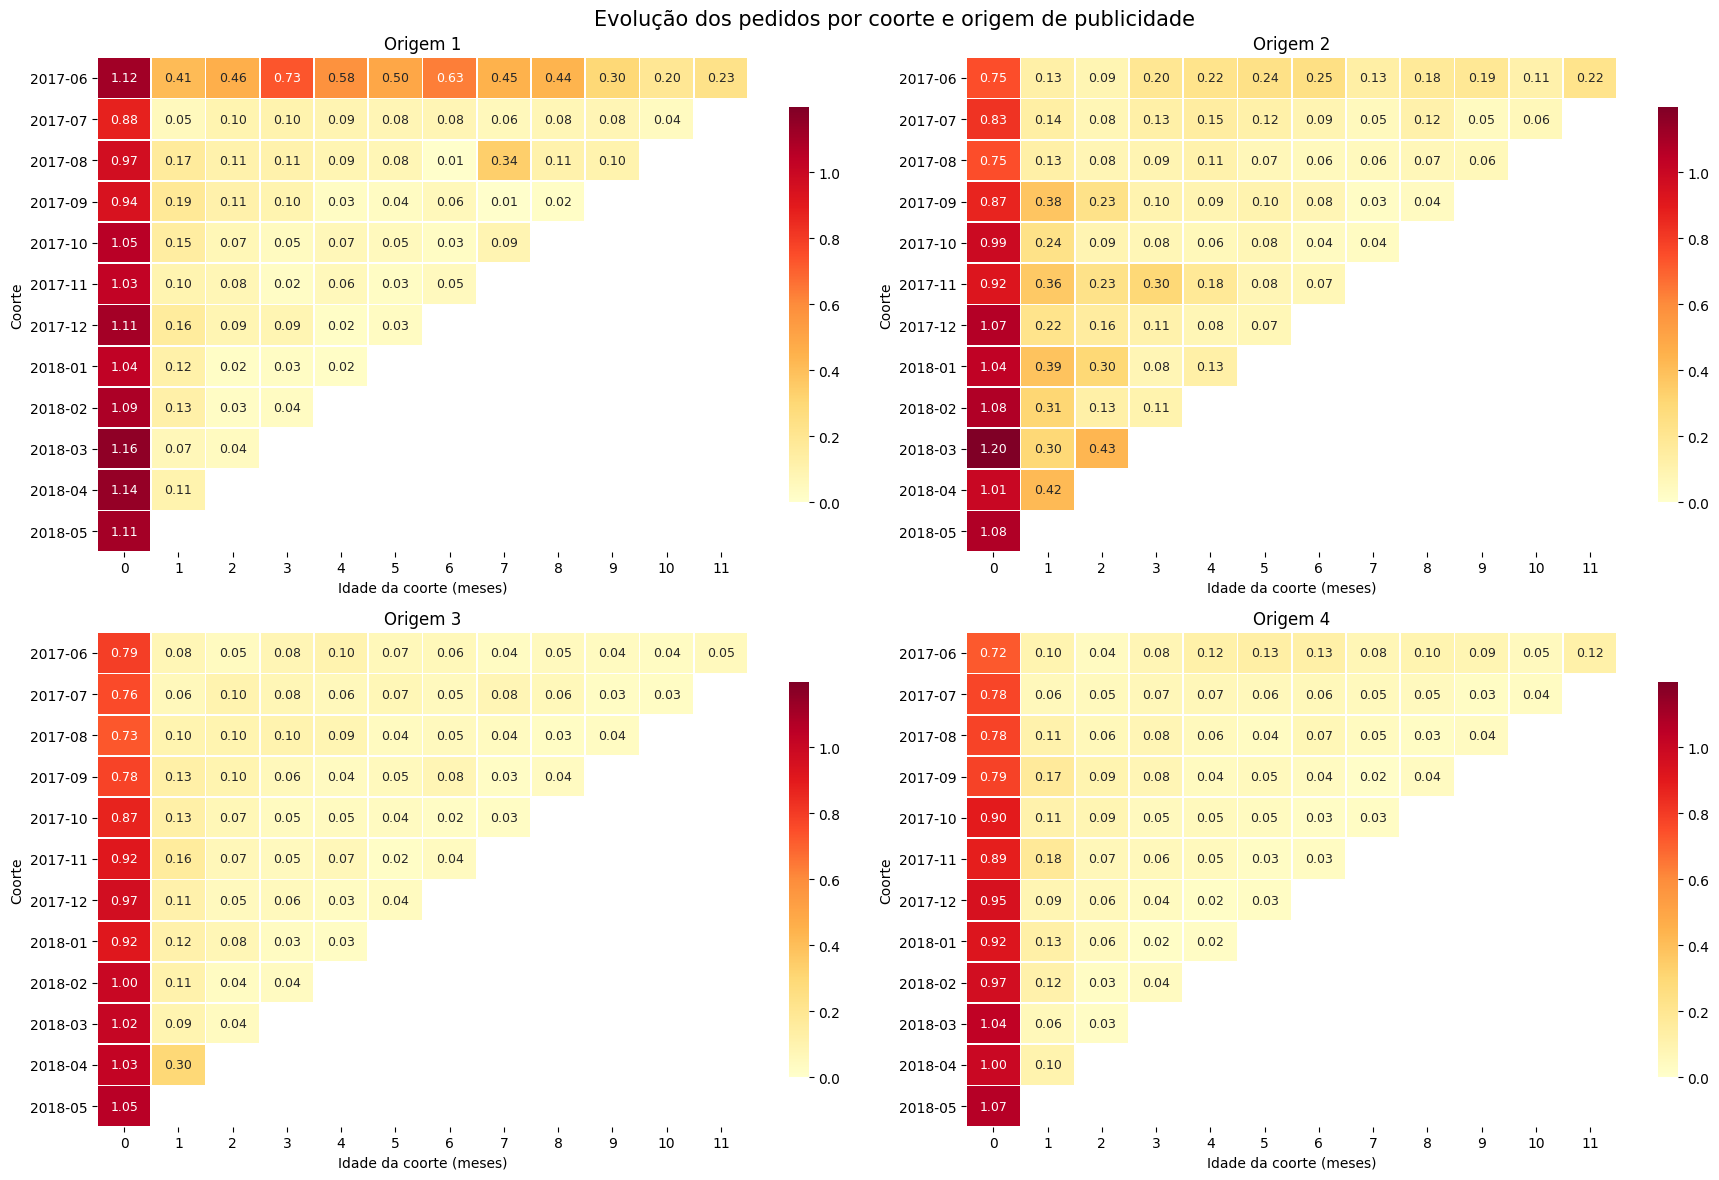

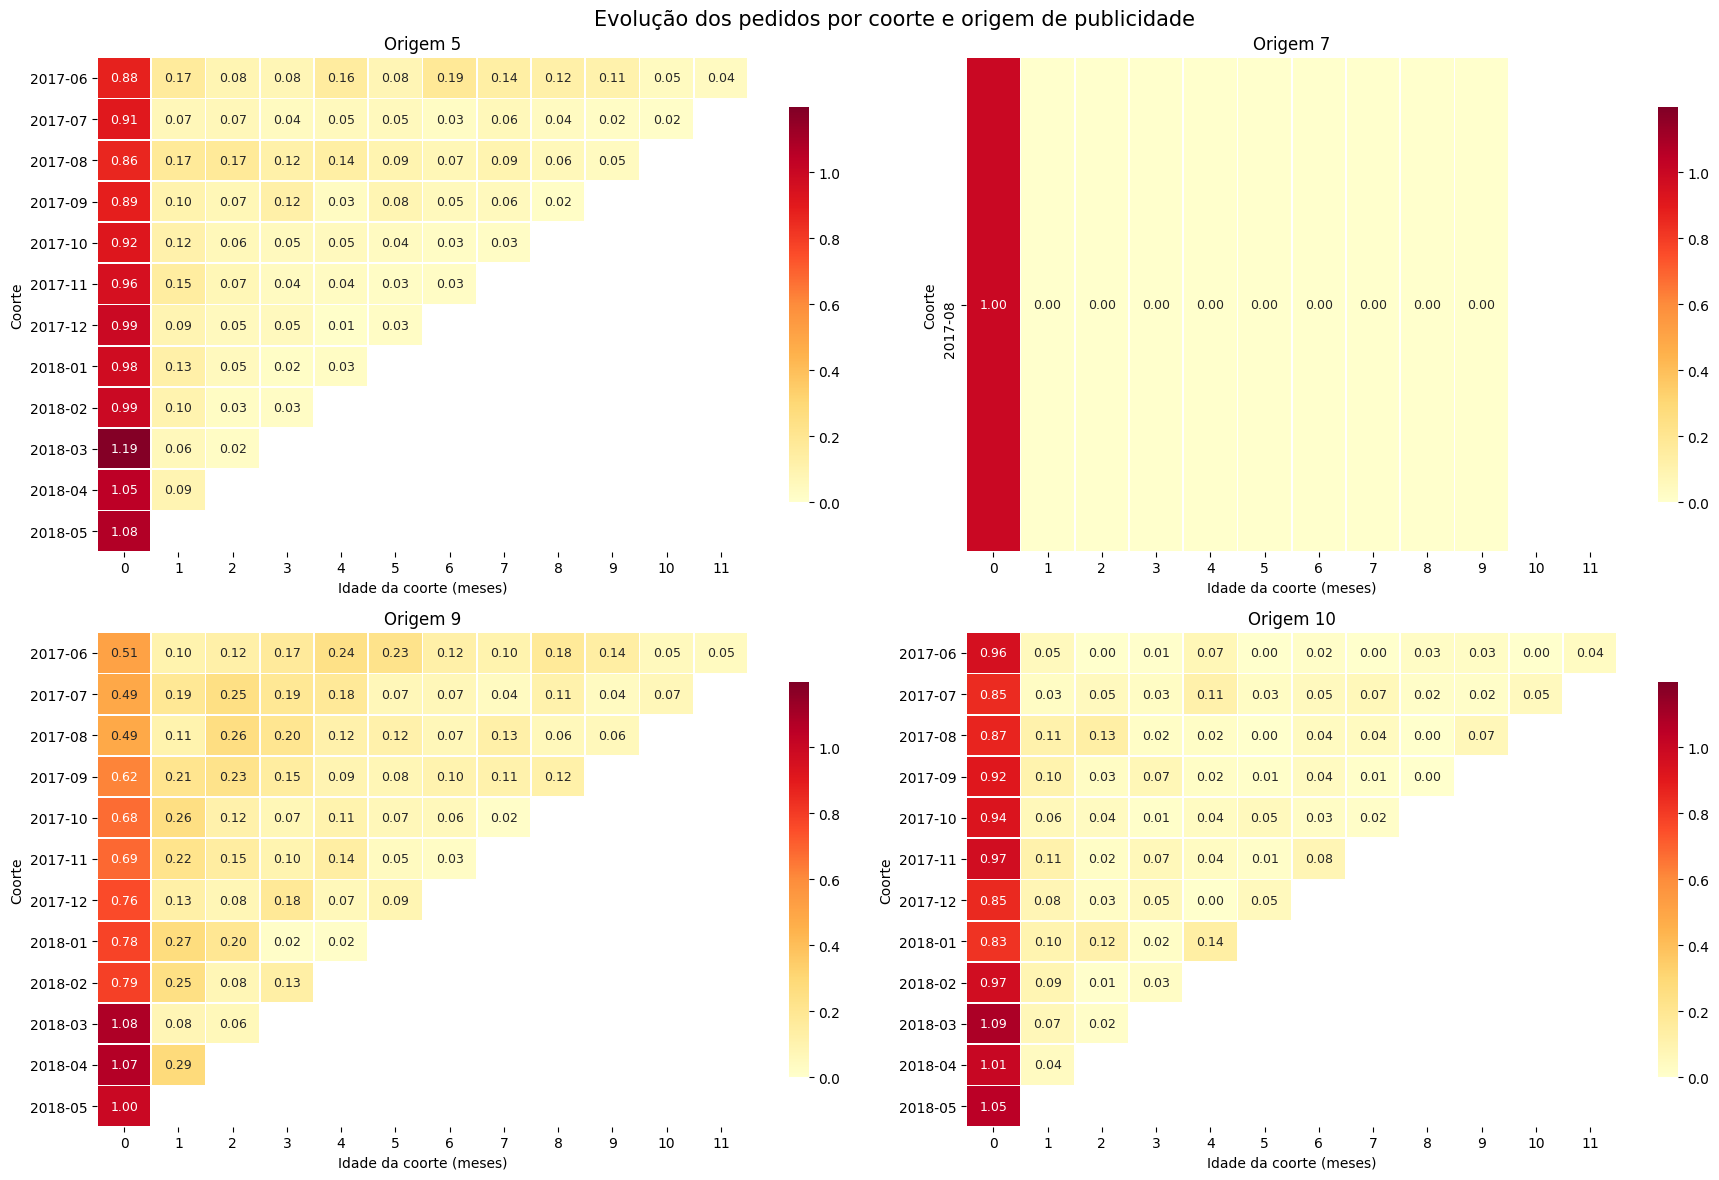

In [81]:
# Criar mapas de calor em grupos de quatro origens

for start in range(0, len(sources), 4):

    batch_sources = sources[start:start + 4]

    fig, axes = plt.subplots(
        2, 2,
        figsize=(18, 12)
    )

    axes = axes.flatten()

    for i, source in enumerate(batch_sources):

        # Selecionar os dados da origem
        source_data = cohort_source_grid[
            cohort_source_grid['Source Id'] == source
        ]

        # Organizar os dados numa tabela dinâmica
        source_pivot = source_data.pivot(
            index='cohort',
            columns='cohort_age',
            values='avg_orders_per_buyer'
        )

        source_pivot = source_pivot.sort_index()

        # Garantir que todos os mapas têm as mesmas colunas
        source_pivot = source_pivot.reindex(
            columns=range(
                int(cohort_source_grid['cohort_age'].max()) + 1
            )
        )

        # Criar o mapa de calor
        sns.heatmap(
            source_pivot,
            annot=True,
            fmt='.2f',
            annot_kws={'size': 9},
            linewidths=0.5,
            linecolor='white',
            cmap='YlOrRd',
            vmin=0,
            vmax=global_vmax,
            cbar_kws={'shrink': 0.8},
            ax=axes[i]
        )

        axes[i].set_title(f'Origem {source}', fontsize=12)
        axes[i].set_xlabel('Idade da coorte (meses)')
        axes[i].set_ylabel('Coorte')

    # Ocultar espaços não utilizados
    for j in range(len(batch_sources), len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(
        'Evolução dos pedidos por coorte e origem de publicidade',
        fontsize=15
    )

    plt.tight_layout()
    plt.show()

**Interpretação e conclusão — Evolução dos pedidos por coorte e origem de publicidade**

Os mapas de calor permitem analisar a evolução da média de pedidos por comprador ao longo da idade das coortes, considerando as diferentes origens de publicidade.

A análise evidencia diferenças no comportamento de compra entre as origens:

- **Origens 1 e 5:** apresentam valores iniciais expressivos em algumas coortes. A origem 1 atinge 1,12 pedidos por comprador na coorte de junho de 2017, enquanto a origem 5 chega a 1,19 na coorte de março de 2018.
- **Origem 2:** apresenta valores iniciais elevados em várias coortes, destacando-se a coorte de março de 2018, com 1,20 pedidos por comprador.
- **Origens 3 e 4:** apresentam, em geral, valores iniciais inferiores aos observados nas origens 1, 2 e 5, embora também revelem diferenças entre coortes.
- **Origem 9:** apresenta um comportamento variável, com algumas coortes a registarem aumentos na frequência de pedidos durante os primeiros meses.
- **Origem 10:** apresenta valores iniciais elevados em várias coortes, mas observa-se uma redução da frequência de pedidos nos meses seguintes.
- **Origem 7:** apresenta apenas um comprador, que realizou um pedido no mês de aquisição. Devido à dimensão reduzida da amostra, não é possível retirar conclusões representativas sobre esta origem.

De forma geral, observa-se uma tendência de redução da média de pedidos por comprador à medida que aumenta a idade da coorte. Este comportamento sugere que a frequência de compras tende a ser mais elevada nos primeiros meses após a aquisição, diminuindo nos períodos seguintes, embora existam oscilações em algumas origens e coortes.

**Conclusão:**

A análise demonstra que a frequência de pedidos varia entre as diferentes origens de publicidade e ao longo do tempo de atividade dos compradores. As origens 1, 2 e 5 apresentam valores iniciais expressivos em determinadas coortes, enquanto as origens 3 e 4 revelam, em geral, frequências iniciais mais reduzidas.

Esta análise permite comparar o comportamento de compra dos clientes considerando períodos de atividade equivalentes, complementando a análise anterior por dispositivo.

Importa salientar que as coortes mais recentes possuem menos meses de observação e que as origens com poucos compradores devem ser interpretadas com cautela. Além disso, uma frequência de pedidos mais elevada não significa necessariamente maior rentabilidade, sendo necessário relacionar estes resultados com o valor das compras e os custos de aquisição nas análises seguintes.

<div class="alert alert-block alert-warning">

Comparar as fontes com heatmaps de coortes é uma boa maneira de colocar os clientes na mesma base temporal, e sua cautela em relação à fonte 7 e às coortes recentes está correta. Parte da leitura, porém, ainda se apoia em células isoladas. As fontes 3 e 4 terem valores iniciais mais baixos vale principalmente para as coortes de 2017, já que em 2018 elas também chegam a cerca de 1,0. Os heatmaps mostram diferenças mais claras que você não menciona. A fonte 2 tem uma recompra visivelmente maior no mês 1 (cerca de 0,2 a 0,43). A fonte 9 tem valores muito mais baixos na idade 0 (cerca de 0,5 a 0,8 até o início de 2018). A coorte de junho de 2017 da fonte 1 tem valores incomumente altos nas idades 1 a 8, então verifique se alguns compradores muito intensivos, como o cliente com 239 pedidos que você encontrou, explicam isso antes de concluir. Reescreva a comparação com base em padrões que se repetem em várias coortes e idades. A idade 0 domina a escala de cores, então uma visualização começando na idade 1, ou o número cumulativo de pedidos por comprador, tornaria as diferenças mais fáceis de ver.

</div>

#### 5.7 Visualizar a evolução mensal dos pedidos

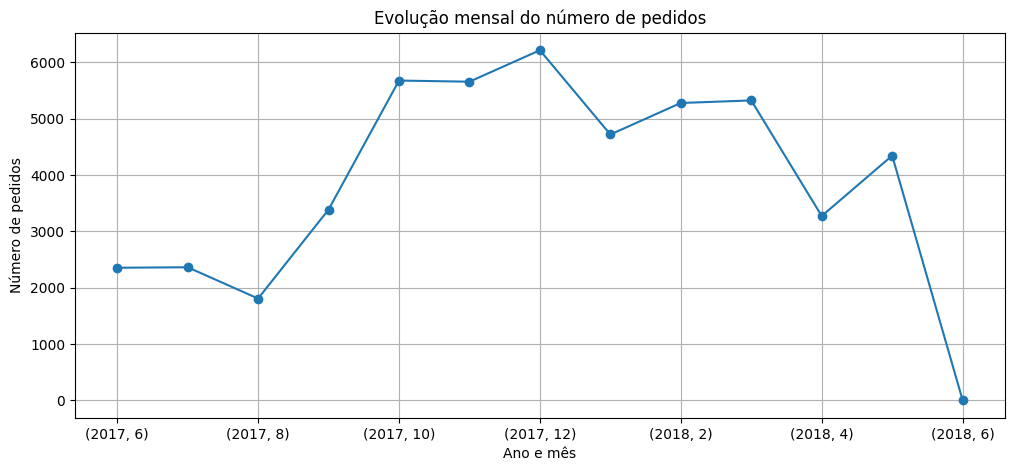

In [82]:
# Visualizar a evolução mensal dos pedidos
monthly_orders.plot(kind='line', figsize=(12, 5), marker='o')

plt.title('Evolução mensal do número de pedidos')
plt.xlabel('Ano e mês')
plt.ylabel('Número de pedidos')
plt.grid()
plt.show()

In [83]:
# Verificar o período abrangido pelos pedidos
print(f"Primeiro pedido: {df_orders['Buy Ts'].min()}")
print(f"Último pedido: {df_orders['Buy Ts'].max()}")

# Consultar os últimos meses
display(monthly_orders.tail())

Primeiro pedido: 2017-06-01 00:10:00
Último pedido: 2018-06-01 00:02:00


order_year  order_month
2018        2              5281
            3              5326
            4              3273
            5              4346
            6                 1
dtype: int64

#### 5.8 Ajustanto a vizualização (excluindo temporariamente o mês de junho)

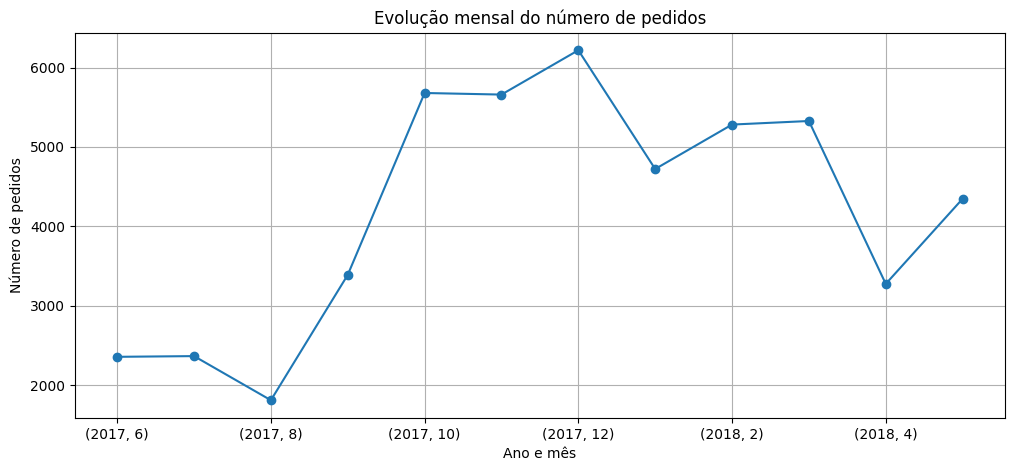

In [84]:
# Excluir o último mês incompleto
monthly_orders_complete = monthly_orders.iloc[:-1]

# Visualizar a evolução mensal dos pedidos
monthly_orders_complete.plot(
    kind='line',
    figsize=(12, 5),
    marker='o'
)

plt.title('Evolução mensal do número de pedidos')
plt.xlabel('Ano e mês')
plt.ylabel('Número de pedidos')
plt.grid()
plt.show()


**Interpretação e conclusão — Evolução dos pedidos**

A evolução mensal dos pedidos evidencia um crescimento expressivo da atividade comercial da Y.Afisha durante o segundo semestre de 2017, atingindo o pico em dezembro, com aproximadamente 6.200 pedidos.

Em 2018, observa-se uma maior oscilação no volume de pedidos, com períodos de queda e recuperação, sugerindo possíveis efeitos sazonais ou alterações na procura.

A análise temporal revelou que junho de 2018 contém apenas um pedido, registado no primeiro dia do mês. Por representar um período incompleto, este mês deve ser excluído das comparações mensais, evitando interpretações distorcidas.

Embora o crescimento dos pedidos seja um indicador positivo de atividade comercial, será necessário analisar o ticket médio e o LTV para compreender se esse crescimento se traduz em maior geração de receita e valor para a empresa.

### 6. Qual é o volume médio de uma compra? (Ticket médio)

In [85]:
# Calcular o ticket médio
average_order_value = df_orders['Revenue'].mean()

print(f"Ticket médio: {average_order_value:.2f}")

Ticket médio: 5.00


#### 6.1 Calcular outras estatísticas
Além da média, vamos calcular a mediana, o valor mínimo e o máximo. Isto permite perceber melhor como os valores dos pedidos estão distribuídos.

In [86]:
# Calcular estatísticas do valor dos pedidos
print(f"Ticket médio: {df_orders['Revenue'].mean():.2f}")

print(f"Ticket mediano: {df_orders['Revenue'].median():.2f}")

print(f"Pedido mínimo: {df_orders['Revenue'].min():.2f}")

print(f"Pedido máximo: {df_orders['Revenue'].max():.2f}")

Ticket médio: 5.00
Ticket mediano: 2.50
Pedido mínimo: 0.00
Pedido máximo: 2633.28


**Interpretação dos resultados**
- Em média, cada pedido gera 5 unidades monetárias de receita.

- 50% dos pedidos apresentam um valor igual ou inferior a 2,50 e os outros 50% apresentam um valor igual ou superior.

- Existem pedidos sem receita registada. Será interessante investigar a sua origem.

- Existe pelo menos um pedido com um valor bastante elevado relativamente à maioria dos restantes.

#### 6.1.1 Analisar os pedidos com receita zero

In [87]:
# Identificar pedidos com receita igual a zero
zero_orders = (df_orders['Revenue'] == 0).sum()

# Calcular a proporção de pedidos com receita zero
zero_percentage = (zero_orders / len(df_orders)) * 100

# Calcular o ticket médio incluindo todos os pedidos
average_with_zero = df_orders['Revenue'].mean()

# Calcular o ticket médio excluindo pedidos com receita zero
average_without_zero = df_orders.loc[
    df_orders['Revenue'] > 0, 'Revenue'
].mean()

# Apresentar os resultados
print(f'Pedidos com receita zero: {zero_orders}')
print(f'Percentagem de pedidos com receita zero: {zero_percentage:.2f}%')
print(f'Ticket médio incluindo pedidos zero: {average_with_zero:.2f}')
print(f'Ticket médio excluindo pedidos zero: {average_without_zero:.2f}')

Pedidos com receita zero: 51
Percentagem de pedidos com receita zero: 0.10%
Ticket médio incluindo pedidos zero: 5.00
Ticket médio excluindo pedidos zero: 5.00


**Interpretação e conclusão — Pedidos com receita zero**

A análise identificou 51 pedidos com receita igual a zero, representando apenas 0,10% do total de 50.415 pedidos.

A comparação entre o ticket médio calculado com todos os pedidos (5,00) e aquele que exclui os pedidos com receita zero (5,00) demonstra que estes registos não influenciam significativamente o valor médio das compras.

Assim, concluímos que os pedidos com receita zero representam uma proporção muito reduzida e não comprometem a interpretação do ticket médio global. Por esse motivo, manteremos todos os registos na análise.

#### 6.2 Preparar os dados para analisar o ticket médio por origem e dispositivo
Vamos acrescentar aos pedidos duas informações: o dispositivo e a origem de publicidade através dos quais cada cliente chegou inicialmente ao site.

Utilizaremos how='left' para preservar todos os pedidos da tabela original.

In [88]:
# Associar os pedidos à origem e ao dispositivo da primeira visita
orders_analysis = df_orders.merge(
    first_visits_detail[['Uid', 'Device', 'Source Id']],
    on='Uid',
    how='left'
)

# Verificar o resultado
display(orders_analysis.head())

# Verificar se existem valores em falta
print(orders_analysis[['Device', 'Source Id']].isna().sum())

,Buy Ts,Revenue,Uid,order_year,order_month,Device,Source Id
0,2017-06-01 00:10:00,17.00,10329302124590727494,2017,6,desktop,1
1,2017-06-01 00:25:00,0.55,11627257723692907447,2017,6,desktop,2
2,2017-06-01 00:27:00,0.37,17903680561304213844,2017,6,desktop,2
3,2017-06-01 00:29:00,0.55,16109239769442553005,2017,6,desktop,2
4,2017-06-01 07:58:00,0.37,14200605875248379450,2017,6,desktop,3


Device       0
Source Id    0
dtype: int64


#### 6.2.1 Calcular o ticket médio por dispositivo e origem
Agora vamos comparar o valor médio dos pedidos entre os diferentes dispositivos e origens de publicidade. Vamos acrescentar o número de pedidos, assim, evitamos tirar conclusões com base em poucas transações. Ou seja, uma origem com ticket médio de 10,00, mas apenas 2 pedidos, por exemplo, não deve necessariamente ser considerada melhor do que outra com ticket médio de 7,00 e 2.000 pedidos.

In [89]:
# Calcular o ticket médio e o número de pedidos
average_ticket = orders_analysis.groupby(
    ['Device', 'Source Id']
).agg(
    orders=('Revenue', 'count'),
    average_ticket=('Revenue', 'mean')
).reset_index()

# Apresentar os resultados
display(average_ticket.round(2))

,Device,Source Id,orders,average_ticket
0,desktop,1,4327,6.01
1,desktop,2,5225,7.73
2,desktop,3,11052,4.19
3,desktop,4,9875,4.40
4,desktop,5,7865,5.95
5,desktop,7,1,1.22
6,desktop,9,1368,3.56
7,desktop,10,1214,2.94
8,touch,1,896,5.69
9,touch,2,1167,5.60


#### 6.2.2 Construir um gráfico comparativo

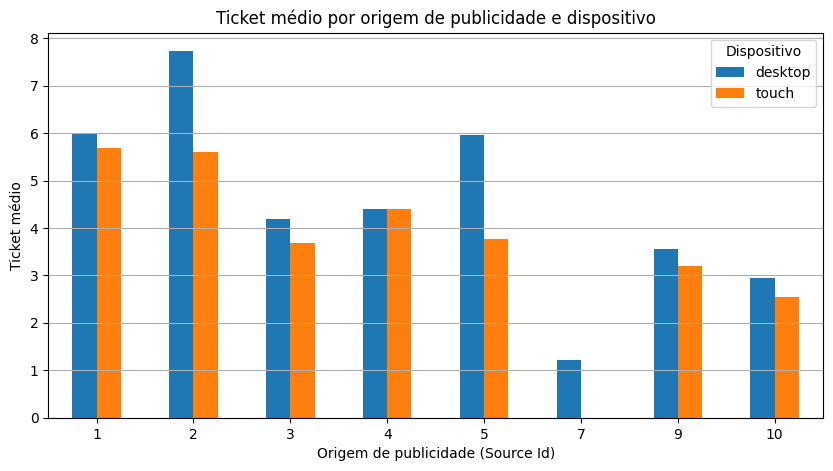

In [90]:
# Comparar o ticket médio por dispositivo e origem
ticket_pivot = average_ticket.pivot(
    index='Source Id',
    columns='Device',
    values='average_ticket'
)

# Criar o gráfico
ticket_pivot.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Ticket médio por origem de publicidade e dispositivo')
plt.xlabel('Origem de publicidade (Source Id)')
plt.ylabel('Ticket médio')
plt.xticks(rotation=0)
plt.legend(title='Dispositivo')
plt.grid(axis='y')
plt.show()

**Interpretação e conclusão — Ticket médio por dispositivo e origem de publicidade**

A análise do ticket médio por dispositivo e origem de publicidade revelou diferenças importantes no valor médio das compras.

No desktop, a origem 2 apresenta o melhor desempenho, com um ticket médio de 7,73, seguida das origens 1 (6,01) e 5 (5,95). No dispositivo touch, destacam-se as origens 1 (5,69) e 2 (5,60).

A comparação entre dispositivos mostra que o desktop apresenta um ticket médio superior na maioria das origens analisadas. A origem 1 apresenta resultados relativamente próximos entre os dois dispositivos, enquanto a origem 4 regista exatamente o mesmo ticket médio (4,40).

A origem 7 não permite uma comparação representativa, uma vez que apresenta apenas um pedido no desktop e nenhum no touch.

Concluímos que a origem de publicidade e o dispositivo utilizado estão associados a diferenças no valor médio das compras. A origem 2 no desktop destaca-se como a combinação mais promissora, tanto pelo ticket médio elevado como pelo volume de pedidos registado.

Estes resultados podem ajudar a orientar futuras decisões de marketing, mas será necessário considerar também os custos de aquisição e a rentabilidade de cada origem antes de definir a distribuição do investimento publicitário.

<div class="alert alert-block alert-warning">

Os valores que você cita correspondem à tabela (origem 2 desktop 7,73, origem 1 6,01, origem 5 5,95). Porém, uma afirmação não corresponde à sua própria tabela. Você diz que a origem 2 no desktop se destaca tanto pelo ticket elevado quanto pelo volume de pedidos. Os 5.225 pedidos dela estão bem abaixo da origem 3 (11.052) e da origem 4 (9.875) no desktop, portanto ela se destaca pelo ticket, não pelo volume. Por exemplo: 'A origem 2 no desktop destaca-se pelo ticket médio mais elevado (7,73), embora tenha menos pedidos do que as origens 3 e 4.' Além disso, como os valores dos pedidos são muito assimétricos (mediana 2,50 vs. média 5,00, máximo 2.633), alguns pedidos extremos podem inflar a média de um segmento. Confirme as principais diferenças com `orders_analysis.groupby(['Device','Source Id'])['Revenue'].median()` antes de chamar uma combinação de a mais promissora.

</div>

#### 6.2.3 Evolução temporal do ticket médio por dispositivo e origem de publicidade

In [91]:
# Calcular o ticket médio mensal por dispositivo e origem
monthly_ticket = orders_analysis.groupby(
    ['order_year', 'order_month', 'Device', 'Source Id'],
    observed=True
).agg(
    orders=('Revenue', 'count'),
    average_ticket=('Revenue', 'mean')
).reset_index()

# Criar uma coluna com o ano e o mês
monthly_ticket['month'] = (
    monthly_ticket['order_year'].astype(str) + '-' +
    monthly_ticket['order_month'].astype(str).str.zfill(2)
)

# Verificar os resultados
display(monthly_ticket.head(10))

,order_year,order_month,Device,Source Id,orders,average_ticket,month
0,2017,6,desktop,1,233,5.361245,2017-06
1,2017,6,desktop,2,235,3.907787,2017-06
2,2017,6,desktop,3,618,4.114450,2017-06
3,2017,6,desktop,4,384,4.111250,2017-06
4,2017,6,desktop,5,377,4.362334,2017-06
5,2017,6,desktop,9,70,3.015857,2017-06
6,2017,6,desktop,10,77,2.294935,2017-06
7,2017,6,touch,1,35,3.700857,2017-06
8,2017,6,touch,2,46,2.725000,2017-06
9,2017,6,touch,3,86,3.041977,2017-06


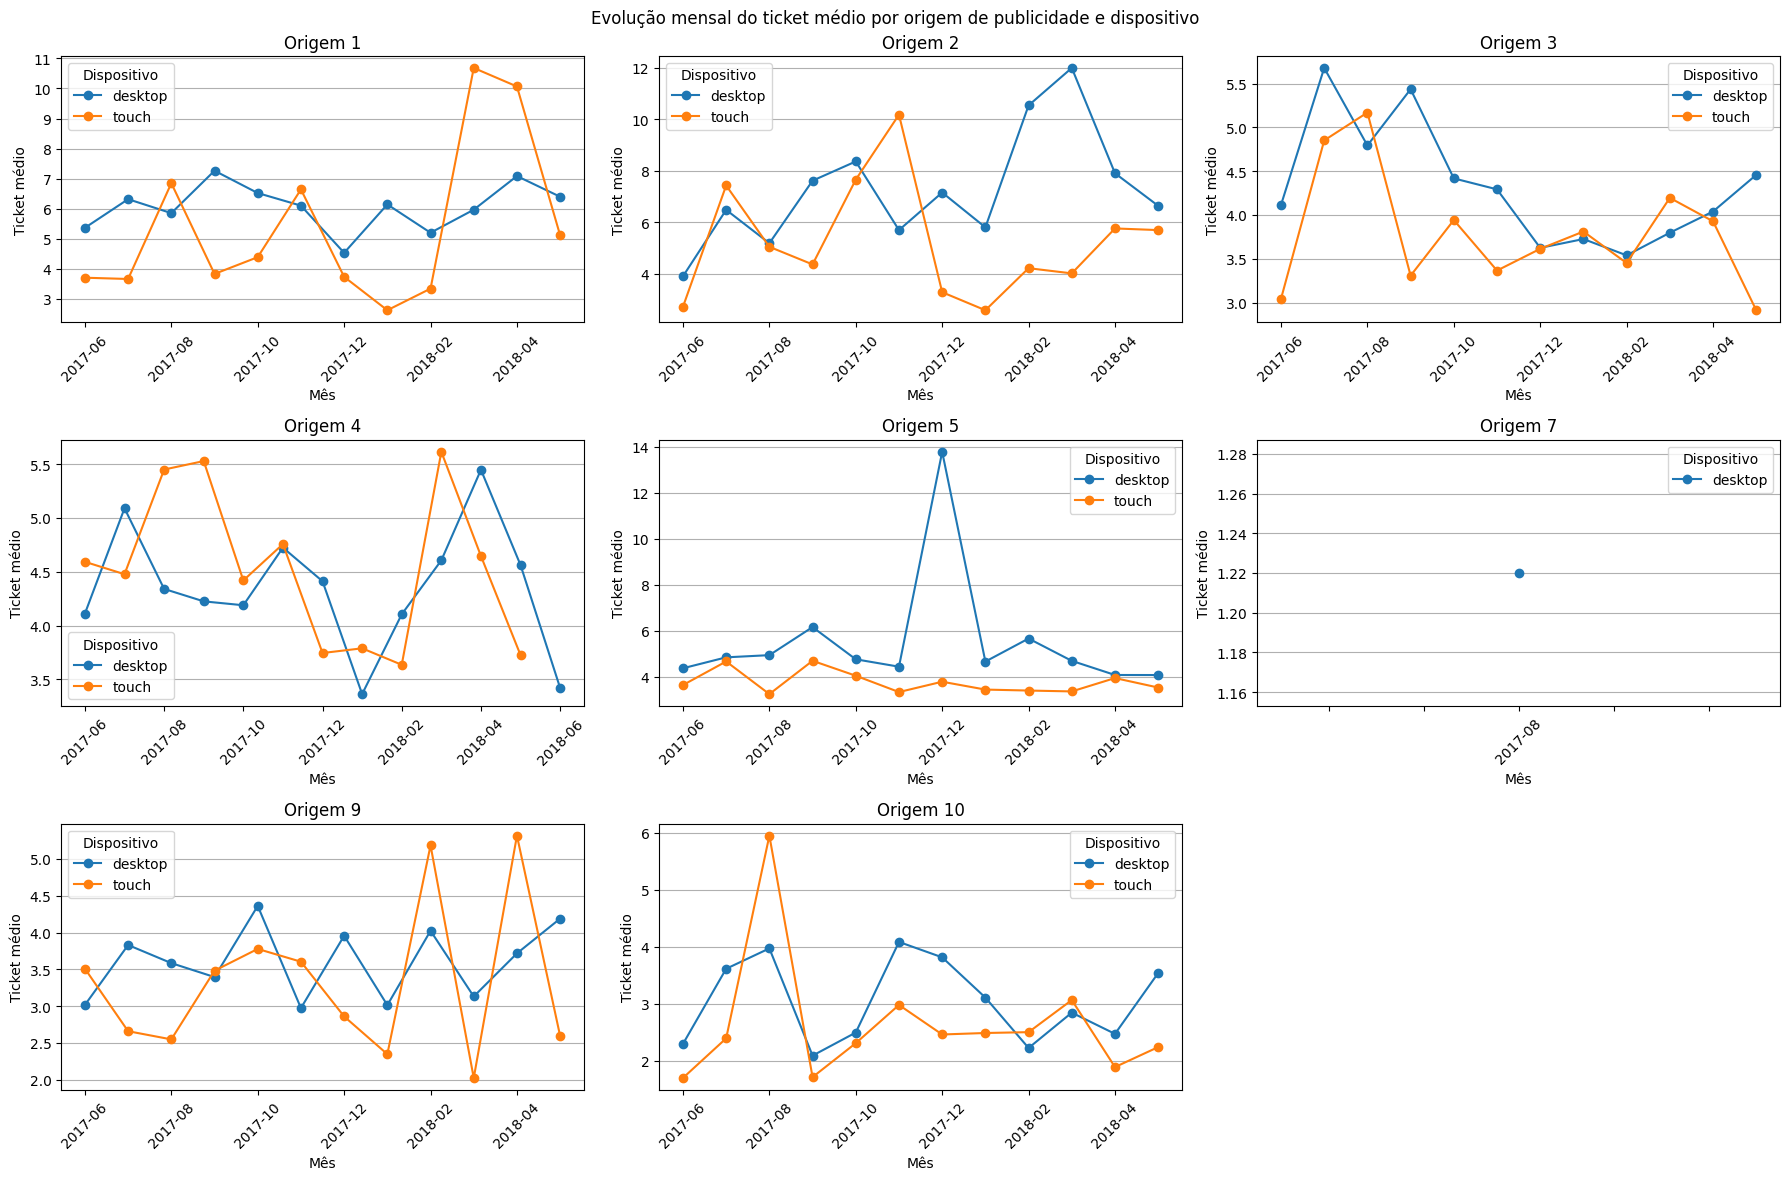

In [92]:
# Identificar as origens de publicidade
sources = sorted(monthly_ticket['Source Id'].unique())

# Criar os oito gráficos
fig, axes = plt.subplots(3, 3, figsize=(18, 12))

axes = axes.flatten()

for i, source in enumerate(sources):

    # Selecionar os dados da origem
    source_data = monthly_ticket[
        monthly_ticket['Source Id'] == source
    ]

    # Organizar os dados por mês e dispositivo
    ticket_pivot = source_data.pivot(
        index='month',
        columns='Device',
        values='average_ticket'
    )

    # Construir o gráfico
    ticket_pivot.plot(
        kind='line',
        marker='o',
        ax=axes[i]
    )

    # Configurar o gráfico
    axes[i].set_title(f'Origem {source}')
    axes[i].set_xlabel('Mês')
    axes[i].set_ylabel('Ticket médio')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend(title='Dispositivo')
    axes[i].grid(axis='y')

# Ocultar o espaço não utilizado
axes[8].set_visible(False)

plt.suptitle(
    'Evolução mensal do ticket médio por origem de publicidade e dispositivo'
)

plt.tight_layout()
plt.show()

**Interpretação e conclusão — Evolução temporal do ticket médio**

A análise da evolução mensal do ticket médio por dispositivo e origem de publicidade revelou variações significativas ao longo do período observado.

No desktop, a origem 2 destacou-se em março de 2018, com um ticket médio de 11,99 e 617 pedidos. A origem 5 também apresentou um resultado expressivo em dezembro de 2017, atingindo um ticket médio de 13,77, com 1.000 pedidos registados.

No dispositivo touch, a origem 1 alcançou um ticket médio de 10,68 em março de 2018, enquanto a origem 2 registou 10,18 em novembro de 2017.

A análise dos volumes de pedidos permitiu verificar que estes resultados não estão necessariamente associados a pequenas quantidades de transações. Pelo contrário, alguns dos maiores tickets médios foram acompanhados por volumes expressivos de pedidos.

Por outro lado, a origem 7 apresentou apenas um pedido durante todo o período analisado, com um ticket médio de 1,22. Por esse motivo, não existem dados suficientes para avaliar a sua evolução temporal ou estabelecer comparações representativas com as restantes origens.

Concluímos que o ticket médio varia tanto em função da origem de publicidade como do dispositivo utilizado, não apresentando um comportamento uniforme ao longo do tempo.

Estes resultados permitem identificar combinações potencialmente interessantes para aprofundar a análise de marketing. Contudo, para determinar quais as origens mais rentáveis, será necessário relacionar o valor das compras com os respetivos custos de aquisição de clientes e investimento publicitário.

<div class="alert alert-block alert-warning">

Sua leitura dos picos corresponde ao gráfico, e mostrar a evolução ao longo do tempo foi uma adição valiosa. Uma conclusão exige cuidado. Você afirma que os tickets mensais altos não estão ligados a poucas ordens, mas o pico de dezembro de 2017 para a source 5 em desktop (13,77) se destaca muito em uma linha que, fora isso, permanece entre 4 e 6. Isso é típico de um punhado de pedidos muito grandes e não de uma mudança real de comportamento, portanto uma grande quantidade de pedidos não descarta essa possibilidade. Verifique os maiores pedidos daquele mês e daquela source, ou compare a média e a mediana, antes de apresentar isso como um resultado. Além disso, as contagens de pedidos que você cita (617 e 1.000) não estão visíveis em nenhum output, pois apenas as primeiras linhas foram exibidas; portanto, imprima essas linhas.

</div>

#### 6.3 Visualizar a distribuição do valor dos pedidos
Vamos utilizar um histograma para perceber onde se concentra a maioria dos valores dos pedidos e identificar possíveis compras de valores muito elevados.

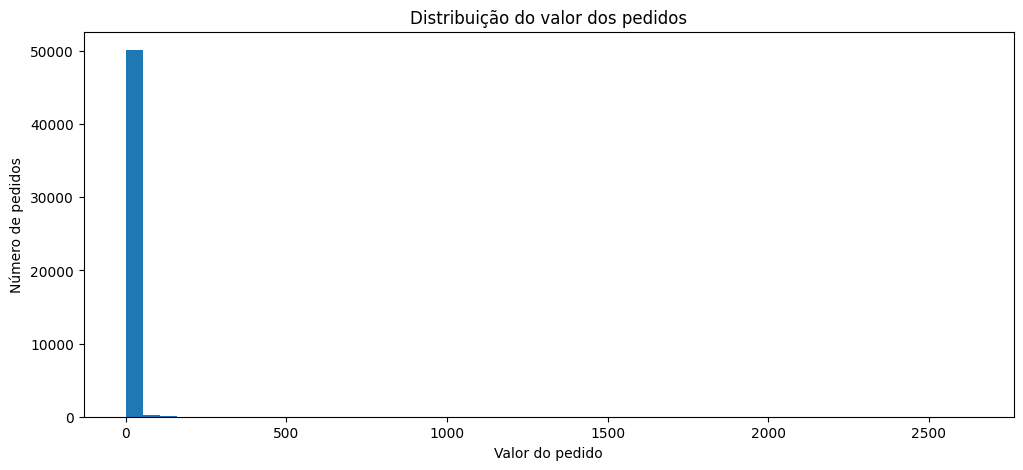

In [93]:
# Visualizar a distribuição do valor dos pedidos
df_orders['Revenue'].hist(bins=50, figsize=(12, 5))

plt.title('Distribuição do valor dos pedidos')
plt.xlabel('Valor do pedido')
plt.ylabel('Número de pedidos')
plt.grid()
plt.show()

**Interpretação**

O histograma apresenta uma distribuição fortemente assimétrica à direita (right-skewed distribution).

Isto significa que:
- A grande maioria dos pedidos concentra-se em valores relativamente baixos.
- Existe uma pequena quantidade de pedidos com valores muito elevados.
- Esses pedidos de valor elevado puxam a média para cima.

#### 6.4 Investigar a distribuição dos pedidos
O histograma tem um problema de visualização: o pedido máximo de 2.633,28 faz com que a grande maioria dos pedidos fique comprimida junto ao zero.

Vamos melhorar a análise sem eliminar nenhum dado original. Isto permitirá perceber melhor onde se concentram os valores dos pedidos e qual é a dimensão da influência dos valores extremos.

In [94]:
# Analisar os percentis do valor dos pedidos
df_orders['Revenue'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    50415.000000
mean         4.999647
std         21.818359
min          0.000000
25%          1.220000
50%          2.500000
75%          4.890000
90%          9.170000
95%         13.750000
99%         36.670000
max       2633.280000
Name: Revenue, dtype: float64

**Interpretação**

- 75% dos pedidos não ultrapassam 4,89.
- 95% dos pedidos não ultrapassam 13,75.
- Apenas 1% dos pedidos apresenta valores superiores a 36,67.
E temos um dado particularmente interessante: o pedido máximo é de 2.633,28, enquanto 99% dos pedidos não ultrapassam 36,67.

Isto demonstra a presença de valores extremos (outliers).

#### 6.5 Melhorar a visualização do histograma
Agora vamos observar a distribuição sem deixar que os valores extremos comprimam visualmente os restantes pedidos.

Vamos utilizar o percentil 99 como limite de visualização.

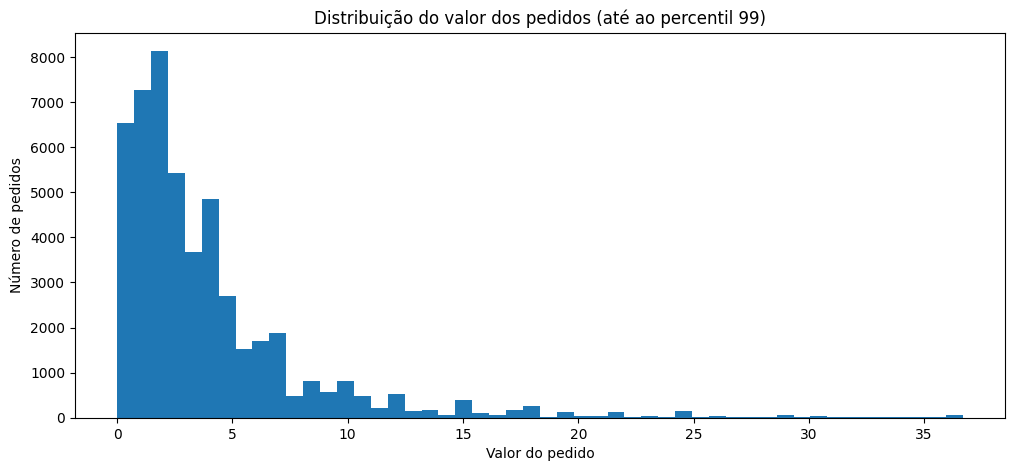

In [95]:
# Identificar o percentil 99
percentile_99 = df_orders['Revenue'].quantile(0.99)

# Visualizar os pedidos até ao percentil 99
df_orders[df_orders['Revenue'] <= percentile_99]['Revenue'].hist(
    bins=50,
    figsize=(12, 5)
)

plt.title('Distribuição do valor dos pedidos (até ao percentil 99)')
plt.xlabel('Valor do pedido')
plt.ylabel('Número de pedidos')
plt.grid()
plt.show()

**Interpretação e conclusão — Ticket médio**

A análise revelou que o ticket médio dos pedidos da Y.Afisha é de 5,00, enquanto a mediana é de 2,50. Esta diferença evidencia uma distribuição assimétrica à direita, indicando que uma pequena proporção de pedidos com valores elevados influencia significativamente a média.

Os percentis confirmam esta concentração: 75% dos pedidos apresentam valores até 4,89, enquanto 99% não ultrapassam 36,67. A análise também identificou valores extremos, com um pedido máximo de 2.633,28. Apesar disso, a visualização limitada ao percentil 99 permitiu compreender melhor a distribuição da maioria das transações sem eliminar os dados originais.

A investigação dos pedidos com receita zero identificou 51 ocorrências, correspondentes a apenas 0,10% do total. A exclusão temporária desses pedidos não alterou significativamente o ticket médio, que se manteve em 5,00.

A análise por dispositivo e origem de publicidade revelou diferenças no valor médio das compras. O desktop apresentou, na maioria das origens, tickets médios superiores aos do dispositivo touch. Destaca-se a origem 2 no desktop, com um ticket médio de 7,73 e 5.225 pedidos, seguida da origem 1, com 6,01. No dispositivo touch, a origem 1 apresentou o melhor resultado, com 5,69.

Concluímos que a Y.Afisha depende predominantemente de pedidos de baixo valor, embora exista uma pequena proporção de transações significativamente superiores. Além disso, determinadas combinações de dispositivo e origem de publicidade apresentam maior capacidade de gerar compras de valor elevado.

Estes resultados sugerem oportunidades para otimizar as estratégias de marketing, melhorar a experiência de compra nos dispositivos e incentivar o aumento do valor médio das transações. Contudo, para determinar quais os canais mais rentáveis, será necessário considerar também os custos de aquisição de clientes e o retorno do investimento publicitário.aliar oportunidades para elevar o valor médio das transações e compreender o contributo dos clientes para a receita ao longo do tempo.

### 7. Quanto dinheiro eles trazem para a empresa (LTV)?

### Parte A — Análise geral do LTV por coorte

#### 7.1 Identificar a coorte de cada cliente

In [96]:
# Criar um DataFrame com a primeira compra de cada cliente
first_orders_df = first_orders.reset_index()

# Renomear a coluna da primeira compra
first_orders_df.columns = ['Uid', 'first_order_date']

# Extrair o ano e o mês da primeira compra
first_orders_df['cohort_year'] = first_orders_df['first_order_date'].dt.year

first_orders_df['cohort_month'] = first_orders_df['first_order_date'].dt.month

# Verificar o resultado
display(first_orders_df.head())

,Uid,first_order_date,cohort_year,cohort_month
0,313578113262317,2018-01-03 21:51:00,2018,1
1,1575281904278712,2017-06-03 10:13:00,2017,6
2,2429014661409475,2017-10-11 18:33:00,2017,10
3,2464366381792757,2018-01-28 15:54:00,2018,1
4,2551852515556206,2017-11-24 10:14:00,2017,11


#### 7.2 Calcular o tamanho de cada coorte

In [97]:
# Calcular o número de clientes por coorte
cohort_sizes = first_orders_df.groupby(
    ['cohort_year', 'cohort_month']
)['Uid'].nunique()

# Apresentar os resultados
display(cohort_sizes)

cohort_year  cohort_month
2017         6               2023
             7               1923
             8               1370
             9               2581
             10              4340
             11              4081
             12              4383
2018         1               3373
             2               3651
             3               3533
             4               2276
             5               2988
             6                  1
Name: Uid, dtype: int64

#### 7.3 Calcular a receita por cliente e por mês
Agora precisamos de combinar duas informações: a coorte à qual pertence cada cliente, e a receita gerada por esse cliente em cada mês.

In [98]:
# Adicionar a data da primeira compra de cada cliente aos pedidos
orders_cohorts = df_orders.merge(
    first_orders_df,
    on='Uid'
)

# Verificar o resultado
display(orders_cohorts.head())

,Buy Ts,Revenue,Uid,order_year,order_month,first_order_date,cohort_year,cohort_month
0,2017-06-01 00:10:00,17.00,10329302124590727494,2017,6,2017-06-01 00:10:00,2017,6
1,2017-06-01 00:25:00,0.55,11627257723692907447,2017,6,2017-06-01 00:25:00,2017,6
2,2017-06-01 00:27:00,0.37,17903680561304213844,2017,6,2017-06-01 00:27:00,2017,6
3,2017-06-01 00:29:00,0.55,16109239769442553005,2017,6,2017-06-01 00:29:00,2017,6
4,2017-06-01 07:58:00,0.37,14200605875248379450,2017,6,2017-06-01 07:58:00,2017,6


In [99]:
# Calcular a receita por coorte e por mês
cohort_revenue = orders_cohorts.groupby(
    ['cohort_year', 'cohort_month', 'order_year', 'order_month']
)['Revenue'].sum()

# Verificar o resultado
display(cohort_revenue.head(10))

cohort_year  cohort_month  order_year  order_month
2017         6             2017        6              9557.49
                                       7               981.82
                                       8               885.34
                                       9              1931.30
                                       10             2068.58
                                       11             1487.92
                                       12             1922.74
                           2018        1              1176.56
                                       2              1119.15
                                       3              1225.51
Name: Revenue, dtype: float64

#### 7.4 Calcular a idade das coortes
Agora precisamos de criar uma métrica que nos permita comparar coortes de meses diferentes.

In [100]:
# Calcular a idade de cada coorte em meses
cohort_revenue = cohort_revenue.reset_index()

cohort_revenue['cohort_age'] = (
    (cohort_revenue['order_year'] - cohort_revenue['cohort_year']) * 12
    + (cohort_revenue['order_month'] - cohort_revenue['cohort_month'])
)

# Verificar o resultado
display(cohort_revenue.head(10))

,cohort_year,cohort_month,order_year,order_month,Revenue,cohort_age
0,2017,6,2017,6,9557.49,0
1,2017,6,2017,7,981.82,1
2,2017,6,2017,8,885.34,2
3,2017,6,2017,9,1931.30,3
4,2017,6,2017,10,2068.58,4
5,2017,6,2017,11,1487.92,5
6,2017,6,2017,12,1922.74,6
7,2017,6,2018,1,1176.56,7
8,2017,6,2018,2,1119.15,8
9,2017,6,2018,3,1225.51,9


#### 7.5 Calcular a receita acumulada por coorte

In [101]:
# Calcular a receita acumulada por coorte
cohort_revenue['cumulative_revenue'] = cohort_revenue.groupby(
    ['cohort_year', 'cohort_month']
)['Revenue'].cumsum()

# Verificar o resultado
display(cohort_revenue.head(10))

,cohort_year,cohort_month,order_year,order_month,Revenue,cohort_age,cumulative_revenue
0,2017,6,2017,6,9557.49,0,9557.49
1,2017,6,2017,7,981.82,1,10539.31
2,2017,6,2017,8,885.34,2,11424.65
3,2017,6,2017,9,1931.30,3,13355.95
4,2017,6,2017,10,2068.58,4,15424.53
5,2017,6,2017,11,1487.92,5,16912.45
6,2017,6,2017,12,1922.74,6,18835.19
7,2017,6,2018,1,1176.56,7,20011.75
8,2017,6,2018,2,1119.15,8,21130.90
9,2017,6,2018,3,1225.51,9,22356.41


#### 7.6 Calcular o LTV por coorte

In [102]:
# Calcular o LTV por coorte
cohort_ltv = cohort_revenue.merge(
    cohort_sizes.reset_index(name='cohort_size'),
    on=['cohort_year', 'cohort_month']
)

cohort_ltv['ltv'] = (
    cohort_ltv['cumulative_revenue'] / cohort_ltv['cohort_size']
)

# Verificar o resultado
display(cohort_ltv.head(10))

,cohort_year,cohort_month,order_year,order_month,Revenue,cohort_age,cumulative_revenue,cohort_size,ltv
0,2017,6,2017,6,9557.49,0,9557.49,2023,4.724414
1,2017,6,2017,7,981.82,1,10539.31,2023,5.209743
2,2017,6,2017,8,885.34,2,11424.65,2023,5.647380
3,2017,6,2017,9,1931.30,3,13355.95,2023,6.602051
4,2017,6,2017,10,2068.58,4,15424.53,2023,7.624582
5,2017,6,2017,11,1487.92,5,16912.45,2023,8.360084
6,2017,6,2017,12,1922.74,6,18835.19,2023,9.310524
7,2017,6,2018,1,1176.56,7,20011.75,2023,9.892116
8,2017,6,2018,2,1119.15,8,21130.90,2023,10.445329
9,2017,6,2018,3,1225.51,9,22356.41,2023,11.051117


#### 7.7 Construir a tabela de coortes do LTV

In [103]:
# Criar a tabela de coortes do LTV
cohort_ltv_pivot = cohort_ltv.pivot_table(
    index=['cohort_year', 'cohort_month'],
    columns='cohort_age',
    values='ltv'
)

# Verificar o resultado
display(cohort_ltv_pivot)

cohort_age                      0         1         2          3          4   \
cohort_year cohort_month                                                       
2017        6             4.724414  5.209743  5.647380   6.602051   7.624582   
            7             6.010218  6.345429  6.968960   7.327936   7.504727   
            8             5.276518  5.748511  6.206993   6.598270   7.092321   
            9             5.644529  6.762115  7.283045  11.258838  11.659396   
            10            5.003733  5.539495  5.730889   5.888035   6.039594   
            11            5.154683  5.553916  5.753472   6.078424   6.226437   
            12            4.738191  4.998565  5.923662   6.988937   7.301866   
2018        1             4.135636  4.430394  4.734675   4.877453   4.940151   
            2             4.156987  4.435262  4.513777   4.587921        NaN   
            3             4.838803  5.139694  5.455253        NaN        NaN   
            4             4.657597  5.189196       NaN        NaN        NaN   
            5             4.660562       NaN       NaN        NaN        NaN   
            6             3.420000       NaN       NaN        NaN        NaN   

cohort_age                       5          6          7          8   \
cohort_year cohort_month                                               
2017        6              8.360084   9.310524   9.892116  10.445329   
            7              7.660775   7.780983   7.922803   8.084035   
            8              7.375861   7.586526   7.991533   8.283745   
            9             12.306463  13.008071  13.251220  13.435227   
            10             6.159956   6.244772   6.360242        NaN   
            11             6.280316   6.395244        NaN        NaN   
            12             7.639913        NaN        NaN        NaN   
2018        1                   NaN        NaN        NaN        NaN   
            2                   NaN        NaN        NaN        NaN   
            3                   NaN        NaN        NaN        NaN   
            4                   NaN        NaN        NaN        NaN   
            5                   NaN        NaN        NaN        NaN   
            6                   NaN        NaN        NaN        NaN   

cohort_age                       9          10         11  
cohort_year cohort_month                                   
2017        6             11.051117  11.622378  11.879234  
            7              8.231180   8.386854        NaN  
            8              8.471723        NaN        NaN  
            9                   NaN        NaN        NaN  
            10                  NaN        NaN        NaN  
            11                  NaN        NaN        NaN  
            12                  NaN        NaN        NaN  
2018        1                   NaN        NaN        NaN  
            2                   NaN        NaN        NaN  
            3                   NaN        NaN        NaN  
            4                   NaN        NaN        NaN  
            5                   NaN        NaN        NaN  
            6                   NaN        NaN        NaN

#### 7.8 Visualizar o LTV através de um mapa de calor

Text(128.75, 0.5, 'coorte de aquisição')

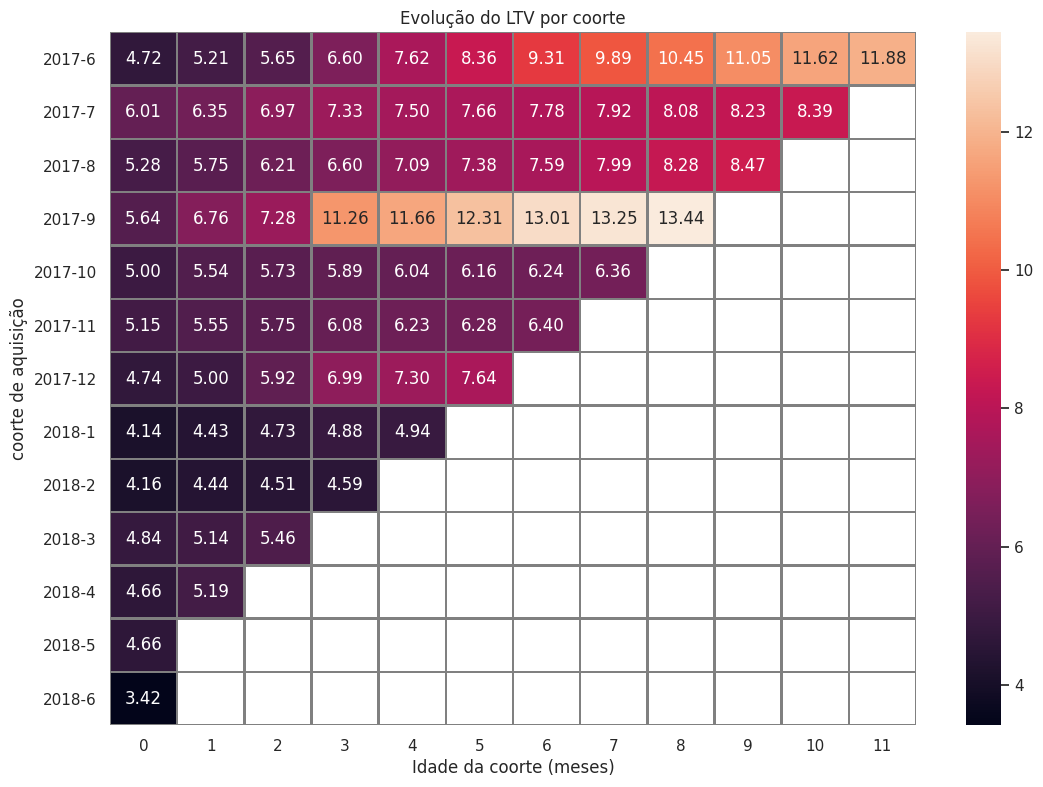

In [104]:
# Criar uma mapa de calor do LTV por coorte
plt.figure(figsize=(13, 9))

sns.set(style='white')

sns.heatmap(
    cohort_ltv_pivot,
    annot=True,
    fmt='.2f',
    linewidths=1,
    linecolor='gray',
)

plt.title('Evolução do LTV por coorte')
plt.xlabel('Idade da coorte (meses)')
plt.ylabel('coorte de aquisição')

**Interpretação e conclusão — Análise do LTV por coorte**

O mapa de calor demonstra uma tendência geral de crescimento do LTV ao longo do tempo, indicando que os clientes continuam a gerar receita para a Y.Afisha após a primeira compra.

A coorte de junho de 2017 apresenta uma evolução consistente, passando de 4,72 na idade 0 para 11,88 na idade 11. Este comportamento evidencia o crescimento progressivo da receita acumulada por cliente ao longo do período analisado.

Destaca-se também a coorte de setembro de 2017, que apresenta o maior LTV observado, atingindo 13,44 na idade 8 meses. Contudo, verifica-se um aumento expressivo entre as idades 2 e 3, passando de 7,28 para 11,26. Esta variação merece investigação adicional, nomeadamente para verificar se foi influenciada por compras de valor elevado ou por um pequeno número de clientes com contribuições particularmente significativas.

Em contrapartida, as coortes de 2018 apresentam valores iniciais mais modestos. No entanto, por serem mais recentes, ainda não dispõem de um período de observação suficiente para uma comparação direta com as coortes mais antigas.

É importante salientar que a coorte de junho de 2018 possui apenas um cliente, apresentando um LTV de 3,42. Por esse motivo, este resultado não é representativo do comportamento de um grupo de clientes e deve ser interpretado com especial cautela.

**Em síntese**, a análise demonstra que o valor gerado por cliente tende a aumentar ao longo do tempo, mas existem diferenças relevantes entre as coortes. A dimensão de cada grupo, a idade da coorte e a possível influência de compras de valor elevado devem ser consideradas para garantir interpretações mais fiáveis sobre o comportamento e o valor dos clientes.

<div class="alert alert-block alert-warning">

Sua interpretação é sólida. Você usa uma idade de coorte consistente, sinaliza as coortes imaturas de 2018 e alerta sobre a coorte de junho de 2018, que tem apenas um cliente. Para o salto de setembro de 2017 (de 7,28 para 11,26 entre as idades 2 e 3), você diz que merece uma investigação mais aprofundada, mas nunca executa a verificação. Observe os maiores pedidos dessa coorte por volta das idades 2 e 3, ou compare o LTV dela com e sem eles. Isso transformaria uma hipótese em uma descoberta. Além disso, deixe claro que essas coortes são definidas pelo mês da primeira compra, enquanto os heatmaps de frequência de pedidos usam o mês da primeira visita, para que os leitores não comparem números entre as seções.

</div>

### Parte B — Análise segmentada por dispositivo e origem publicitária

#### 7.10 Associar o dispositivo e a origem de publicidade a cada cliente

In [105]:
# Associar o dispositivo e a origem de publicidade a cada cliente
first_orders_segmented = first_orders_df.merge(
    first_visits_detail[['Uid', 'Device', 'Source Id']],
    on='Uid',
    how='left'
)

# Verificar o resultado
display(first_orders_segmented.head(10))

,Uid,first_order_date,cohort_year,cohort_month,Device,Source Id
0,313578113262317,2018-01-03 21:51:00,2018,1,desktop,2
1,1575281904278712,2017-06-03 10:13:00,2017,6,touch,10
2,2429014661409475,2017-10-11 18:33:00,2017,10,desktop,3
3,2464366381792757,2018-01-28 15:54:00,2018,1,desktop,5
4,2551852515556206,2017-11-24 10:14:00,2017,11,desktop,5
5,3077748354309989,2018-03-03 12:33:00,2018,3,touch,3
6,3605148382144603,2017-09-21 20:56:00,2017,9,desktop,2
7,3753586865891862,2018-03-03 13:50:00,2018,3,desktop,4
8,4808417689019433,2018-01-09 23:32:00,2018,1,desktop,4
9,4992223027560440,2018-04-04 13:54:00,2018,4,touch,5


#### 7.11 Associar cada pedido à respetiva coorte, dispositivo e origem

In [106]:
# Associar cada pedido à respetiva coorte, dispositivo e origem
orders_ltv_segmented = df_orders.merge(
    first_orders_segmented[
        ['Uid', 'cohort_year', 'cohort_month', 'Device', 'Source Id']
    ],
    on='Uid',
    how='inner'
)

# Verificar o resultado
display(orders_ltv_segmented.head())

,Buy Ts,Revenue,Uid,order_year,order_month,cohort_year,cohort_month,Device,Source Id
0,2017-06-01 00:10:00,17.00,10329302124590727494,2017,6,2017,6,desktop,1
1,2017-06-01 00:25:00,0.55,11627257723692907447,2017,6,2017,6,desktop,2
2,2017-06-01 00:27:00,0.37,17903680561304213844,2017,6,2017,6,desktop,2
3,2017-06-01 00:29:00,0.55,16109239769442553005,2017,6,2017,6,desktop,2
4,2017-06-01 07:58:00,0.37,14200605875248379450,2017,6,2017,6,desktop,3


#### 7.12 Calcular o tamanho das coortes segmentadas

In [107]:
# Calcular o número de clientes por coorte, dispositivo e origem
cohort_sizes_segmented = first_orders_segmented.groupby(
    ['cohort_year', 'cohort_month', 'Device', 'Source Id'],
    observed=True
)['Uid'].nunique().reset_index(name='cohort_size')

# Verificar os resultados
display(cohort_sizes_segmented.head(10))

,cohort_year,cohort_month,Device,Source Id,cohort_size
0,2017,6,desktop,1,163
1,2017,6,desktop,2,191
2,2017,6,desktop,3,564
3,2017,6,desktop,4,339
4,2017,6,desktop,5,319
5,2017,6,desktop,9,60
6,2017,6,desktop,10,66
7,2017,6,touch,1,27
8,2017,6,touch,2,44
9,2017,6,touch,3,74


 #### 7.13 Receita mensal por coorte, dispositivo e origem

In [108]:
# Calcular a receita mensal por coorte, dispositivo e origem
cohort_revenue_segmented = orders_ltv_segmented.groupby(
    [
        'cohort_year',
        'cohort_month',
        'Device',
        'Source Id',
        'order_year',
        'order_month'
    ],
    observed=True
)['Revenue'].sum().reset_index()

# Verificar o resultado
display(cohort_revenue_segmented.head(10))

,cohort_year,cohort_month,Device,Source Id,order_year,order_month,Revenue
0,2017,6,desktop,1,2017,6,1249.17
1,2017,6,desktop,1,2017,7,413.15
2,2017,6,desktop,1,2017,8,419.43
3,2017,6,desktop,1,2017,9,692.92
4,2017,6,desktop,1,2017,10,768.36
5,2017,6,desktop,1,2017,11,386.90
6,2017,6,desktop,1,2017,12,490.48
7,2017,6,desktop,1,2018,1,471.90
8,2017,6,desktop,1,2018,2,428.48
9,2017,6,desktop,1,2018,3,306.03


#### 7.14 Calcular a idade das coortes segmentadas

In [109]:
# Calcular a idade de cada coorte em meses
cohort_revenue_segmented['cohort_age'] = (
    (cohort_revenue_segmented['order_year'] -
     cohort_revenue_segmented['cohort_year']) * 12
    +
    (cohort_revenue_segmented['order_month'] -
     cohort_revenue_segmented['cohort_month'])
)

# Verificar o resultado
display(cohort_revenue_segmented.head(10))

,cohort_year,cohort_month,Device,Source Id,order_year,order_month,Revenue,cohort_age
0,2017,6,desktop,1,2017,6,1249.17,0
1,2017,6,desktop,1,2017,7,413.15,1
2,2017,6,desktop,1,2017,8,419.43,2
3,2017,6,desktop,1,2017,9,692.92,3
4,2017,6,desktop,1,2017,10,768.36,4
5,2017,6,desktop,1,2017,11,386.90,5
6,2017,6,desktop,1,2017,12,490.48,6
7,2017,6,desktop,1,2018,1,471.90,7
8,2017,6,desktop,1,2018,2,428.48,8
9,2017,6,desktop,1,2018,3,306.03,9


#### 7.15 Calcular a receita acumulada por coorte, dispositivo e origem

In [110]:
# Calcular a receita acumulada por coorte, dispositivo e origem
cohort_revenue_segmented['cumulative_revenue'] = (
    cohort_revenue_segmented
    .groupby(
        ['cohort_year', 'cohort_month', 'Device', 'Source Id']
    )['Revenue']
    .cumsum()
)

# Verificar o resultado
display(cohort_revenue_segmented.head(10))

,cohort_year,cohort_month,Device,Source Id,order_year,order_month,Revenue,cohort_age,cumulative_revenue
0,2017,6,desktop,1,2017,6,1249.17,0,1249.17
1,2017,6,desktop,1,2017,7,413.15,1,1662.32
2,2017,6,desktop,1,2017,8,419.43,2,2081.75
3,2017,6,desktop,1,2017,9,692.92,3,2774.67
4,2017,6,desktop,1,2017,10,768.36,4,3543.03
5,2017,6,desktop,1,2017,11,386.90,5,3929.93
6,2017,6,desktop,1,2017,12,490.48,6,4420.41
7,2017,6,desktop,1,2018,1,471.90,7,4892.31
8,2017,6,desktop,1,2018,2,428.48,8,5320.79
9,2017,6,desktop,1,2018,3,306.03,9,5626.82


#### 7.16 Calcular o LTV segmentado

In [111]:
# Calcular o LTV por coorte, dispositivo e origem
cohort_ltv_segmented = cohort_revenue_segmented.merge(
    cohort_sizes_segmented,
    on=['cohort_year', 'cohort_month', 'Device', 'Source Id']
)

cohort_ltv_segmented['ltv'] = (
    cohort_ltv_segmented['cumulative_revenue'] /
    cohort_ltv_segmented['cohort_size']
)

# Verificar o resultado
display(cohort_ltv_segmented.head(10))

,cohort_year,cohort_month,Device,Source Id,order_year,order_month,Revenue,cohort_age,cumulative_revenue,cohort_size,ltv
0,2017,6,desktop,1,2017,6,1249.17,0,1249.17,163,7.663620
1,2017,6,desktop,1,2017,7,413.15,1,1662.32,163,10.198282
2,2017,6,desktop,1,2017,8,419.43,2,2081.75,163,12.771472
3,2017,6,desktop,1,2017,9,692.92,3,2774.67,163,17.022515
4,2017,6,desktop,1,2017,10,768.36,4,3543.03,163,21.736380
5,2017,6,desktop,1,2017,11,386.90,5,3929.93,163,24.110000
6,2017,6,desktop,1,2017,12,490.48,6,4420.41,163,27.119080
7,2017,6,desktop,1,2018,1,471.90,7,4892.31,163,30.014172
8,2017,6,desktop,1,2018,2,428.48,8,5320.79,163,32.642883
9,2017,6,desktop,1,2018,3,306.03,9,5626.82,163,34.520368


#### 7.17 Visualizar o LTV por origem de publicidade e dispositivo.

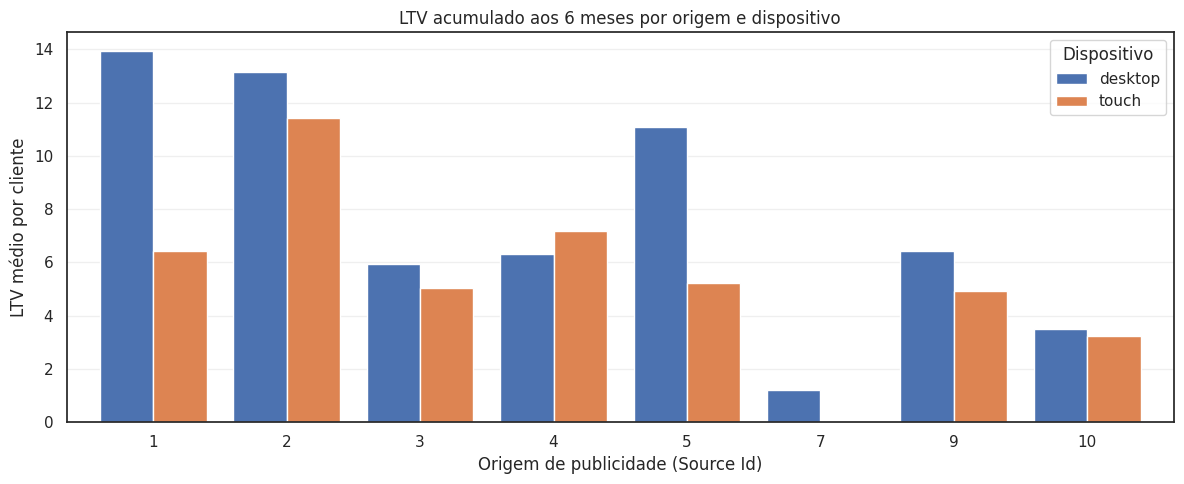

,Source Id,Device,total_cumulative_revenue,total_clients,ltv_6_months
0,1,desktop,15546.91,1115,13.943417
1,1,touch,1539.93,239,6.443222
2,2,desktop,15995.50,1218,13.132594
3,2,touch,4141.09,363,11.407961
4,3,desktop,23402.95,3940,5.939835
5,3,touch,3505.07,696,5.036020
6,4,desktop,20570.25,3262,6.306024
7,4,touch,6795.05,945,7.190529
8,5,desktop,30856.94,2782,11.091639
9,5,touch,3203.51,612,5.234493


In [112]:
# Definir o horizonte de comparação: 6 meses
comparison_age = 6

# Calcular a idade máxima observável de cada coorte
eligible_cohorts = cohort_sizes_segmented.copy()

eligible_cohorts['max_age'] = (
    (last_complete_year - eligible_cohorts['cohort_year']) * 12
    +
    (last_complete_month - eligible_cohorts['cohort_month'])
)

# Manter apenas as coortes que já completaram 6 meses
eligible_cohorts = eligible_cohorts[
    eligible_cohorts['max_age'] >= comparison_age
].copy()

# Criar as idades de 0 a 6 meses
cohort_ages_ltv = pd.DataFrame({
    'cohort_age': range(comparison_age + 1)
})

# Criar todas as combinações de coorte, dispositivo, origem e idade
ltv_grid = eligible_cohorts.merge(
    cohort_ages_ltv,
    how='cross'
)

# Associar a receita mensal a cada combinação
ltv_grid = ltv_grid.merge(
    cohort_revenue_segmented[
        [
            'cohort_year',
            'cohort_month',
            'Device',
            'Source Id',
            'cohort_age',
            'Revenue'
        ]
    ],
    on=[
        'cohort_year',
        'cohort_month',
        'Device',
        'Source Id',
        'cohort_age'
    ],
    how='left'
)

# Preencher com zero os meses sem receita
ltv_grid['Revenue'] = ltv_grid['Revenue'].fillna(0)

# Ordenar os dados antes de calcular a receita acumulada
ltv_grid = ltv_grid.sort_values(
    [
        'cohort_year',
        'cohort_month',
        'Device',
        'Source Id',
        'cohort_age'
    ]
)

# Calcular a receita acumulada até aos 6 meses
ltv_grid['cumulative_revenue'] = ltv_grid.groupby(
    ['cohort_year', 'cohort_month', 'Device', 'Source Id'],
    observed=True
)['Revenue'].cumsum()

# Selecionar os dados correspondentes à idade de 6 meses
ltv_6m = ltv_grid[
    ltv_grid['cohort_age'] == comparison_age
].copy()

# Agregar a receita acumulada e os clientes das mesmas coortes
ltv_comparison = ltv_6m.groupby(
    ['Source Id', 'Device'],
    observed=True
).agg(
    total_cumulative_revenue=('cumulative_revenue', 'sum'),
    total_clients=('cohort_size', 'sum')
)

# Calcular o LTV médio ponderado aos 6 meses
ltv_comparison['ltv_6_months'] = (
    ltv_comparison['total_cumulative_revenue'] /
    ltv_comparison['total_clients']
)

# Preparar os dados para o gráfico
ltv_plot = ltv_comparison['ltv_6_months'].unstack()

# Criar o gráfico
ltv_plot.plot(
    kind='bar',
    figsize=(12, 5),
    width=0.8
)

plt.title('LTV acumulado aos 6 meses por origem e dispositivo')
plt.xlabel('Origem de publicidade (Source Id)')
plt.ylabel('LTV médio por cliente')
plt.legend(title='Dispositivo')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Apresentar os valores utilizados no gráfico
display(ltv_comparison.reset_index())

<div class="alert alert-block alert-success">

Excelente correção. O LTV segmentado agora compara a receita acumulada por cliente em uma idade fixa de 6 meses, mantendo apenas as coortes antigas o suficiente para tê-la atingido. A receita e o tamanho das coortes são somados sobre as mesmas coortes antes da divisão, os meses sem receita são preenchidos com zero, e os valores por trás do gráfico são exibidos. O gráfico corresponde à tabela (fonte 1 desktop cerca de 13,9, fonte 2 desktop cerca de 13,1), e sua interpretação expõe claramente os limites: ausência de custos por dispositivo, horizonte de 6 meses e fonte 7 com um único cliente.

</div>

**Interpretação e conclusão — LTV por origem de publicidade e dispositivo**

A análise do LTV acumulado aos 6 meses revela diferenças no valor gerado pelos clientes, consoante a origem publicitária e o dispositivo utilizado.

A origem 1 apresenta o maior LTV no Desktop, com aproximadamente 13,94 por cliente. A origem 2 também se destaca, com 13,13 no Desktop e 11,41 no Touch, apresentando o melhor resultado neste último dispositivo. Estes valores indicam que os clientes provenientes destas origens geraram mais receita acumulada, em média, durante os primeiros seis meses.

A origem 5 apresenta igualmente um resultado expressivo no Desktop, com um LTV de aproximadamente 11,09. Já a origem 4 destaca-se no Touch, com cerca de 7,19, valor superior ao registado no Desktop, de 6,31.

Nas origens 3, 9 e 10, o LTV no Desktop também é superior ao do Touch. A origem 10 apresenta os valores mais baixos entre as origens com dados nos dois dispositivos, com aproximadamente 3,49 no Desktop e 3,25 no Touch.

É importante destacar a origem 7, que apresenta apenas um cliente no Desktop, com um LTV de 1,22, não existindo clientes registados no Touch. Devido à dimensão extremamente reduzida desta amostra, não é possível retirar conclusões representativas sobre o desempenho desta origem.

Em síntese, as origens 1 e 2 apresentam os resultados mais expressivos, embora com diferenças entre dispositivos. A origem 5 também se destaca pelo valor gerado no Desktop.

**Limitação da análise:** os resultados por dispositivo representam a receita acumulada média por cliente ao longo de seis meses. Como os custos de marketing não estão discriminados por dispositivo, não é possível avaliar a rentabilidade de Desktop e Touch separadamente. Além disso, o LTV calculado corresponde ao valor acumulado no horizonte observado de seis meses, não representando necessariamente o valor total gerado durante toda a vida do cliente.

### Conclusão geral — Análise das Vendas

A análise das vendas permitiu compreender o comportamento dos clientes da Y.Afisha, desde a primeira visita ao site até à realização de compras e à receita gerada ao longo do tempo.

A análise dos pedidos revelou que o ticket médio é de 5,00 unidades monetárias, enquanto a mediana é de 2,50. Esta diferença evidencia uma distribuição assimétrica à direita, indicando que a maioria das compras apresenta valores relativamente baixos, enquanto um número reduzido de pedidos de valor elevado influencia a média. A análise dos percentis confirmou esta concentração: 75% dos pedidos não ultrapassam 4,89 e 99% apresentam valores até 36,67.

A investigação dos pedidos com receita zero identificou 51 ocorrências, correspondentes a aproximadamente 0,10% dos pedidos. Embora representem uma proporção reduzida, estes registos foram identificados e considerados na análise.

A análise de coortes demonstrou que o valor gerado por cliente tende a aumentar ao longo do tempo, evidenciando a importância das compras recorrentes. Destaca-se a coorte de junho de 2017, cujo LTV evoluiu de 4,72 no primeiro mês para 11,88 ao fim de 11 meses. A coorte de setembro de 2017 apresentou o maior LTV observado, atingindo 13,44 aos 8 meses de idade. Contudo, as diferenças entre coortes devem ser interpretadas considerando o respetivo período de observação e a dimensão de cada grupo.

A segmentação do LTV acumulado aos 6 meses por origem publicitária e dispositivo revelou diferenças no valor gerado pelos clientes. A origem 1 através do Desktop apresentou o maior LTV, aproximadamente 13,94, seguida da origem 2 através do Desktop, com 13,13. No dispositivo Touch, a origem 2 destacou-se com um LTV de aproximadamente 11,41. A origem 5 também apresentou um resultado expressivo no Desktop, com cerca de 11,09. Estes resultados demonstram que um maior volume de clientes não significa necessariamente maior valor gerado por cliente. Importa ainda salientar que a origem 7 conta com apenas um cliente, pelo que não permite conclusões representativas. Como os custos de marketing não estão discriminados por dispositivo, esta análise avalia o valor gerado por cliente e não a rentabilidade de cada dispositivo.

Em síntese, a análise das vendas permitiu identificar padrões no comportamento de compra, compreender a distribuição dos valores dos pedidos e avaliar a evolução da receita gerada pelos clientes. Os resultados mostram a importância de acompanhar não apenas o número de compras, mas também o valor médio das transações, a evolução das coortes e as diferenças entre os segmentos de clientes.

Esta análise constitui uma base importante para a próxima etapa do projeto: avaliar as despesas de Marketing, o custo de aquisição de clientes e a relação entre os investimentos publicitários e o valor gerado pelos clientes.

## Análise das despesas de Marketing
### 8. Quanto dinheiro foi gasto? No total/por origem/ao longo do tempo

#### 8.1 Calcular as despesas totais de Marketing

In [113]:
# Calcular as despesas totais de marketing
total_costs = df_costs['costs'].sum()

print(f'Despesas totais de marketing: ${total_costs:,.2f}')

Despesas totais de marketing: $329,131.62


#### 8.2 Calcular as despesas por origem de anúncios

In [114]:
# Calcular as despesas por origem de anúncios
costs_by_source = df_costs.groupby('source_id')['costs'].sum()

# Ordenar as despesas da maior para a menor
costs_by_source = costs_by_source.sort_values(ascending=False)

display(costs_by_source)

source_id
3     141321.63
4      61073.60
5      51757.10
2      42806.04
1      20833.27
10      5822.49
9       5517.49
Name: costs, dtype: float64

#### 8.2.1 Visualizar as despesas de marketing por origem

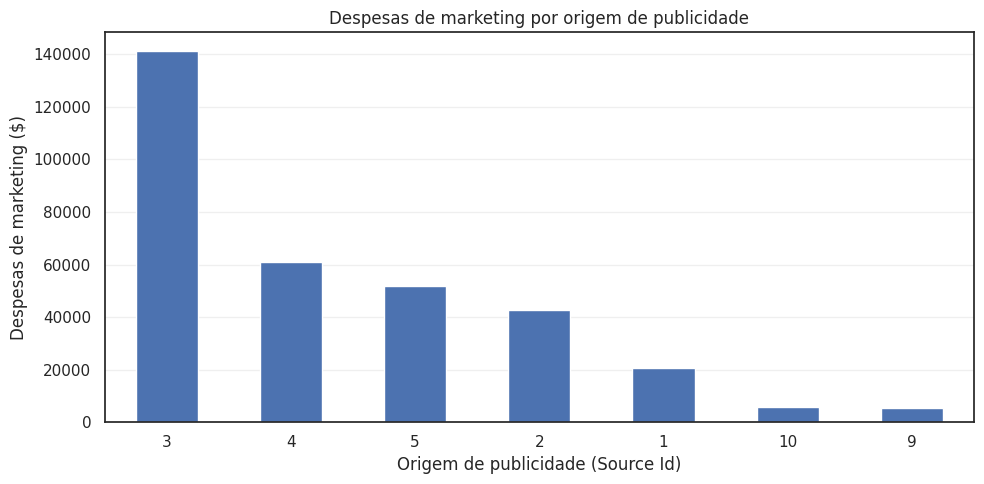

In [115]:
# Visualizar as despesas de marketing por origem
costs_by_source.sort_values(ascending=False).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Despesas de marketing por origem de publicidade')
plt.xlabel('Origem de publicidade (Source Id)')
plt.ylabel('Despesas de marketing ($)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretação e Conclusão — Distribuição das despesas de marketing por origem**

O gráfico evidencia uma distribuição desigual do orçamento de marketing entre as diferentes origens de publicidade.

A origem 3 concentrou a maior parcela do investimento, absorvendo aproximadamente 42,9% das despesas totais. Seguem-se as origens 4 e 5, que também receberam investimentos significativos.

Em contrapartida, as origens 9 e 10 apresentaram os menores níveis de investimento.

Esta distribuição demonstra que a empresa concentrou uma parte considerável dos seus recursos em poucas origens de publicidade. Contudo, um investimento elevado não significa necessariamente maior eficiência ou retorno financeiro.

Por isso, será fundamental relacionar as despesas com o número de clientes adquiridos (CAC) e a receita gerada por cada origem, de forma a identificar quais os investimentos que proporcionam melhores resultados.

#### 8.3 Calcular as despesas ao longo do tempo

In [116]:
# Extrair o ano e o mês
df_costs['cost_year'] = df_costs['dt'].dt.year
df_costs['cost_month'] = df_costs['dt'].dt.month

# Calcular as despesas mensais
monthly_costs = df_costs.groupby(
    ['cost_year', 'cost_month']
)['costs'].sum()

display(monthly_costs)

cost_year  cost_month
2017       6             18015.00
           7             18240.59
           8             14790.54
           9             24368.91
           10            36322.88
           11            37907.88
           12            38315.35
2018       1             33518.52
           2             32723.03
           3             30415.27
           4             22289.38
           5             22224.27
Name: costs, dtype: float64

#### 8.4 Visualizar a evolução mensal das despesas

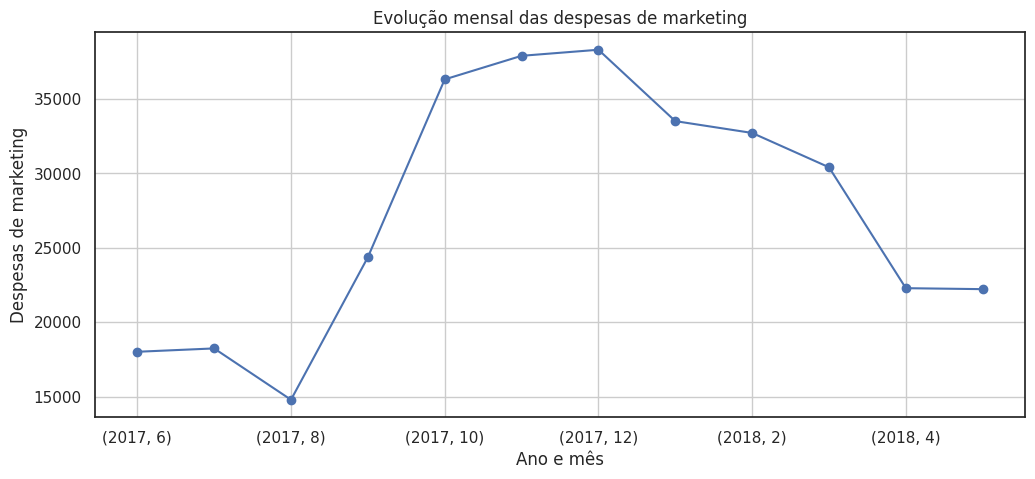

In [117]:
# Visualizar a evolução mensal das despesas
monthly_costs.plot(
    kind='line',
    figsize=(12, 5),
    marker='o'
)

plt.title('Evolução mensal das despesas de marketing')
plt.xlabel('Ano e mês')
plt.ylabel('Despesas de marketing')
plt.grid()
plt.show()

**Interpretação e Conclusão — Distribuição das despesas de marketing**

Durante o período analisado, a Y.Afisha investiu um total de 329 131,62 $ em marketing.

A distribuição por origem revela uma forte concentração do orçamento: a origem 3 representou aproximadamente 42,9% das despesas totais, seguida pelas origens 4 e 5, que também absorveram parcelas significativas do investimento.

Ao longo do tempo, verificou-se um crescimento expressivo das despesas entre setembro e dezembro de 2017, atingindo o valor máximo em dezembro. A partir de janeiro de 2018, os investimentos diminuíram progressivamente.

Estes resultados permitem identificar onde e quando a empresa concentrou os seus recursos financeiros. No entanto, um investimento elevado não significa necessariamente maior eficiência. Para avaliar a rentabilidade de cada origem, será necessário relacionar as despesas com o número de clientes adquiridos e a receita gerada.

### 9. Quanto custou a aquisição de clientes para cada origem (CAC)?

#### 9.1 Identificar a origem de aquisição de cada cliente
Aqui temos um detalhe importante: precisamos de identificar através de qual origem de publicidade cada cliente chegou inicialmente ao site.

Como um utilizador pode realizar várias sessões, vamos considerar a origem da sua primeira visita.

In [118]:
# Identificar a primeira visita de cada utilizador
first_visits_source = df_visits.sort_values('Start Ts').drop_duplicates('Uid')

# Selecionar os clientes que realizaram pelo menos uma compra
buyers = df_orders[['Uid']].drop_duplicates()

# Associar cada cliente à sua origem de aquisição
buyers['Source Id'] = buyers['Uid'].map(
    first_visits_source.set_index('Uid')['Source Id']
)

# Verificar o resultado
display(buyers.head())

,Uid,Source Id
0,10329302124590727494,1
1,11627257723692907447,2
2,17903680561304213844,2
3,16109239769442553005,2
4,14200605875248379450,3


#### 9.2 Calcular o número de clientes por origem

In [119]:
# Calcular o número de clientes adquiridos por origem
buyers_by_source = buyers.groupby('Source Id').size()

# Verificar os resultados
display(buyers_by_source)

Source Id
1      2899
2      3506
3     10473
4     10296
5      6931
7         1
9      1088
10     1329
dtype: int64

#### 9.3 Calcular o CAC por origem

In [120]:
# Combinar despesas e número de clientes por origem
cac_by_source = pd.concat(
    [costs_by_source, buyers_by_source],
    axis=1
)

# Renomear as colunas
cac_by_source.columns = ['total_costs', 'buyers']

# Calcular o CAC apenas quando existe despesa registada
cac_by_source['cac'] = (
    cac_by_source['total_costs'] /
    cac_by_source['buyers']
)

# Identificar as origens sem despesas registadas
cac_by_source['status'] = np.where(
    cac_by_source['total_costs'].isna(),
    'Sem gasto registado — CAC não calculável',
    'CAC calculado'
)

# Ordenar pelo CAC, mantendo as origens sem CAC no final
cac_by_source = cac_by_source.sort_values(
    'cac',
    na_position='last'
)

# Apresentar os resultados
display(cac_by_source)

,total_costs,buyers,cac,status
10,5822.49,1329,4.381106,CAC calculado
9,5517.49,1088,5.071222,CAC calculado
4,61073.60,10296,5.931779,CAC calculado
1,20833.27,2899,7.186364,CAC calculado
5,51757.10,6931,7.467479,CAC calculado
2,42806.04,3506,12.209367,CAC calculado
3,141321.63,10473,13.493901,CAC calculado
7,NaN,1,NaN,Sem gasto registado — CAC não calculável


<div class="alert alert-block alert-success">

Bom tratamento da fonte 7. Ela permanece na tabela com um estado explícito ('Sem gasto registado — CAC não calculável') e é colocada em último lugar, de modo que fica visível sem distorcer o ranking. Os valores de CAC estão corretos (por exemplo, 141,321.63 / 10,473 = 13.49 para a fonte 3). Acrescente uma frase na interpretação do CAC dizendo que a fonte 7 tem um comprador e nenhum gasto registado.

</div>

#### 9.3.1 Visualizar o CAC por origem


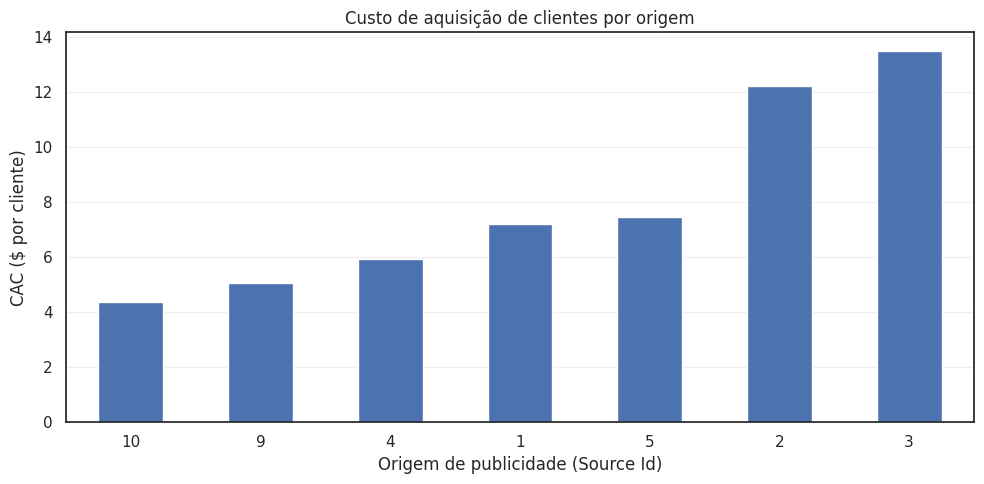

In [121]:
# Visualizar o CAC por origem de publicidade

cac_by_source['cac'].dropna().sort_values().plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Custo de aquisição de clientes por origem')
plt.xlabel('Origem de publicidade (Source Id)')
plt.ylabel('CAC ($ por cliente)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### 9.4 Comparar o número de clientes por origem e dispositivo

In [122]:
# Comparar o número de clientes por origem e dispositivo
client_comparison = first_orders_segmented.groupby(
    ['Source Id', 'Device'],
    observed=True
)['Uid'].nunique().unstack(fill_value=0)

# Apresentar os resultados
display(client_comparison)

Device,desktop,touch
Source Id,,
1,2264,635
2,2649,857
3,8724,1749
4,7932,2364
5,5705,1226
7,1,0
9,892,196
10,1044,285


#### 9.4.1 Visualizar a comparação

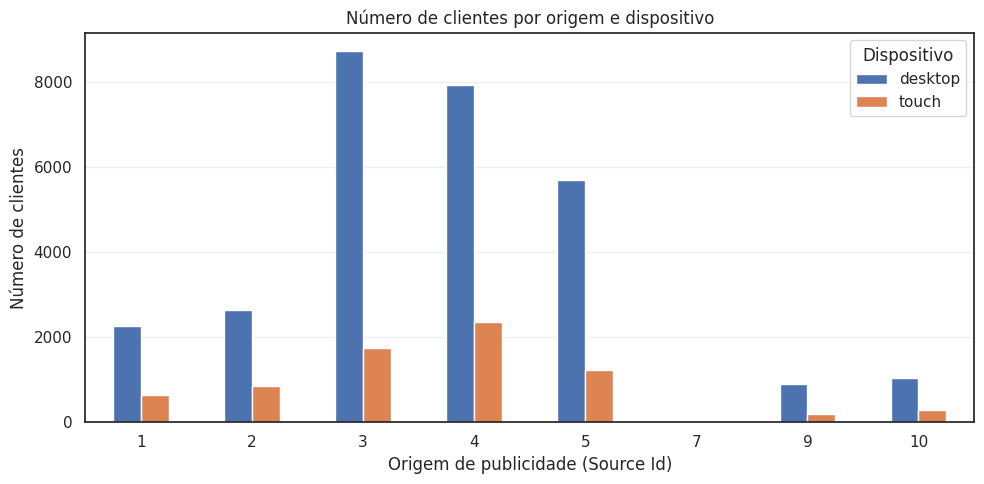

In [123]:
# Visualizar o número de clientes por origem e dispositivo
client_comparison.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Número de clientes por origem e dispositivo')
plt.xlabel('Origem de publicidade (Source Id)')
plt.ylabel('Número de clientes')
plt.xticks(rotation=0)
plt.legend(title='Dispositivo')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretação e Conclusão — Número de clientes por origem e dispositivo**

A análise da aquisição de clientes por origem publicitária e dispositivo revela uma predominância consistente do desktop em todas as origens analisadas.

A origem 3 apresentou o maior volume de aquisição, com 10 473 clientes, dos quais 8 724 utilizaram desktop e 1 749 utilizaram touch. A origem 4 registou um resultado semelhante, com 10 296 clientes, enquanto a origem 5 alcançou 6 931 clientes.

Observa-se também que o desktop concentra a maior parte dos clientes em todas as origens, indicando que este dispositivo teve um papel predominante na aquisição durante o período analisado.

Contudo, um maior número de clientes não significa necessariamente maior eficiência ou rentabilidade. Para avaliar o desempenho financeiro das origens, é necessário considerar conjuntamente os custos de aquisição e o valor gerado pelos clientes (LTV).

Importa salientar que os dados de despesas de marketing não incluem uma divisão por dispositivo. Por esse motivo, não é possível calcular o CAC separadamente para desktop e touch.

Em síntese, a análise evidencia a importância do desktop no volume de aquisição, mas reforça que as decisões de investimento devem considerar também os custos e o valor gerado por cada origem publicitária.

**Interpretação e Conclusão — Custo de aquisição de clientes por origem**

A análise do CAC revelou diferenças significativas na eficiência das origens de publicidade.

A origem 10 apresentou o menor custo de aquisição, aproximadamente 4,38 \\$ por cliente, seguida das origens 9 e 4, com valores de 5,07 \\$ e 5,93 \\$, respetivamente.

Destaca-se particularmente a origem 4, que conseguiu adquirir 10.296 clientes mantendo um CAC relativamente reduzido. Este resultado demonstra uma combinação interessante entre eficiência de investimento e volume de aquisição.

Em contrapartida, a origem 3 apresentou o CAC mais elevado, aproximadamente 13,49 \\$, apesar de ter adquirido 10.473 clientes. A origem 2 também registou um custo elevado, de aproximadamente 12,21 \\$ por cliente.

Estes resultados sugerem que as origens 4, 9 e 10 apresentam vantagens em termos de custo de aquisição. Contudo, um CAC reduzido não garante, por si só, maior rentabilidade. Será necessário comparar estes valores com a receita gerada e o LTV dos clientes para avaliar a eficiência financeira de cada origem.

### 10. Avaliar se os investimentos em marketing valeram a pena (ROI/ROMI).

#### 10.1 Calcular a receita gerada por origem

In [124]:
# Associar cada pedido à origem de aquisição do cliente
orders_by_source = df_orders.merge(
    buyers,
    on='Uid'
)

# Calcular a receita total por origem
revenue_by_source = orders_by_source.groupby('Source Id')['Revenue'].sum()

# Verificar os resultados
display(revenue_by_source)

Source Id
1     31090.55
2     46923.61
3     54511.24
4     56696.83
5     52624.02
7         1.22
9      5759.40
10     4450.33
Name: Revenue, dtype: float64

#### 10.2 Calcular o ROMI por origem publicitária

In [125]:
# Combinar despesas e receita por origem
marketing_return = pd.concat(
    [costs_by_source, revenue_by_source],
    axis=1
)

# Renomear as colunas
marketing_return.columns = ['total_costs', 'revenue']

# Calcular o ROMI apenas para origens com investimento registado
marketing_return['romi'] = (
    (marketing_return['revenue'] - marketing_return['total_costs'])
    / marketing_return['total_costs']
) * 100

# Identificar origens sem despesas registadas
marketing_return['status'] = np.where(
    marketing_return['total_costs'].isna(),
    'Sem gasto registado — ROMI não calculável',
    'ROMI calculado'
)

# Ordenar pelo ROMI, mantendo valores não calculáveis no final
marketing_return = marketing_return.sort_values(
    'romi',
    ascending=False,
    na_position='last'
)

# Apresentar os resultados
display(marketing_return)

,total_costs,revenue,romi,status
1,20833.27,31090.55,49.235094,ROMI calculado
2,42806.04,46923.61,9.619133,ROMI calculado
9,5517.49,5759.40,4.384421,ROMI calculado
5,51757.10,52624.02,1.674978,ROMI calculado
4,61073.60,56696.83,-7.166386,ROMI calculado
10,5822.49,4450.33,-23.566550,ROMI calculado
3,141321.63,54511.24,-61.427532,ROMI calculado
7,NaN,1.22,NaN,Sem gasto registado — ROMI não calculável


<div class="alert alert-block alert-success">

Agora você calcula o ROMI com a fórmula padrão, (receita − custo) / custo × 100, de modo que o resultado seja lido diretamente como ganho ou perda. Para a fonte 1, (31.090,55 − 20.833,27) / 20.833,27 = +49,24%, e a fonte 3 apresenta −61,43%. A fonte 7 é mantida como NaN com um status explícito e uma explicação, e a sua observação de que o payback por coorte é a referência mais confiável foi muito bem pensada. Opcionalmente, destaque que as fontes 9 (+4,4%) e 5 (+1,7%) estão próximas do ponto de equilíbrio (break-even), portanto podem se tornar negativas quando outros custos forem considerados.

</div>

**Interpretação e limitações do ROMI por origem publicitária**

A análise do ROMI baseado na receita total observada revela que a origem 1 apresenta o resultado mais elevado, com aproximadamente 49,24%, seguida das origens 2, 9 e 5, que também apresentam resultados positivos. Por outro lado, as origens 4, 10 e 3 registam valores negativos, indicando que a receita observada foi inferior ao investimento em marketing.

A origem 7 apresenta um comprador e uma receita de 1,22, mas não possui despesas de marketing registadas. Por esse motivo, não é possível calcular o CAC nem o ROMI desta origem. A ausência de despesa registada não significa necessariamente que a aquisição tenha sido gratuita.

**Limitação da análise:** este ROMI compara a receita total observada com o investimento por origem, mas não considera períodos de observação iguais para todas as coortes. Assim, clientes adquiridos em momentos diferentes tiveram tempos distintos para gerar receita. Além disso, como não dispomos da margem de contribuição nem de todos os custos operacionais, este indicador representa um retorno baseado na receita, e não o lucro efetivo.

Para avaliar de forma mais adequada a recuperação do investimento ao longo do tempo, a análise de payback por coortes será utilizada como principal referência para comparar o desempenho das origens publicitárias.

#### 10.3 Calcular o CAC por origem e coorte de aquisição

#### 10.3.1 Calcular as despesas mensais por origem 

In [126]:
# Calcular as despesas mensais por origem publicitária
monthly_costs_source = df_costs.groupby(
    ['source_id', 'cost_year', 'cost_month']
)['costs'].sum().reset_index()

# Verificar os resultados
display(monthly_costs_source.head(10))

,source_id,cost_year,cost_month,costs
0,1,2017,6,1125.61
1,1,2017,7,1072.88
2,1,2017,8,951.81
3,1,2017,9,1502.01
4,1,2017,10,2315.75
5,1,2017,11,2445.16
6,1,2017,12,2341.20
7,1,2018,1,2186.18
8,1,2018,2,2204.48
9,1,2018,3,1893.09


#### 10.3.2 Contar os clientes adquiridos por origem e coorte

In [127]:
# Calcular o número de clientes por origem e coorte
buyers_by_cohort_source = first_orders_segmented.groupby(
    ['Source Id', 'cohort_year', 'cohort_month'],
    observed=True
)['Uid'].nunique().reset_index(name='buyers')

# Verificar os resultados
display(buyers_by_cohort_source.head(10))

,Source Id,cohort_year,cohort_month,buyers
0,1,2017,6,190
1,1,2017,7,160
2,1,2017,8,113
3,1,2017,9,227
4,1,2017,10,340
5,1,2017,11,324
6,1,2017,12,331
7,1,2018,1,238
8,1,2018,2,275
9,1,2018,3,281


#### 10.3.3 Associar despesas aos clientes adquiridos
Vamos associar: as despesas de cada origem em cada mês, e o número de novos clientes adquiridos pela mesma origem e no mesmo mês.

In [128]:
# Associar as despesas ao número de clientes adquiridos
cac_by_cohort_source = monthly_costs_source.merge(
    buyers_by_cohort_source,
    left_on=['source_id', 'cost_year', 'cost_month'],
    right_on=['Source Id', 'cohort_year', 'cohort_month'],
    how='left'
)

# Calcular o CAC por origem e coorte
cac_by_cohort_source['cac'] = (
    cac_by_cohort_source['costs'] /
    cac_by_cohort_source['buyers']
)

# Ordenar os resultados
cac_by_cohort_source = cac_by_cohort_source.sort_values(
    ['source_id', 'cost_year', 'cost_month']
)

# Verificar os resultados
display(cac_by_cohort_source.head(15))

,source_id,cost_year,cost_month,costs,Source Id,cohort_year,cohort_month,buyers,cac
0,1,2017,6,1125.61,1,2017,6,190,5.924263
1,1,2017,7,1072.88,1,2017,7,160,6.705500
2,1,2017,8,951.81,1,2017,8,113,8.423097
3,1,2017,9,1502.01,1,2017,9,227,6.616784
4,1,2017,10,2315.75,1,2017,10,340,6.811029
5,1,2017,11,2445.16,1,2017,11,324,7.546790
6,1,2017,12,2341.20,1,2017,12,331,7.073112
7,1,2018,1,2186.18,1,2018,1,238,9.185630
8,1,2018,2,2204.48,1,2018,2,275,8.016291
9,1,2018,3,1893.09,1,2018,3,281,6.736975


#### 10.4 Calcular o LTV acumulado por origem e coorte

#### 10.4.1 Calcular a receita mensal por origem e coorte

In [129]:
# Calcular a receita mensal por origem e coorte
revenue_by_cohort_source = orders_ltv_segmented.groupby(
    ['Source Id', 'cohort_year', 'cohort_month',
     'order_year', 'order_month'],
    observed=True
)['Revenue'].sum().reset_index()

# Calcular a idade da coorte em meses
revenue_by_cohort_source['cohort_age'] = (
    (revenue_by_cohort_source['order_year'] -
     revenue_by_cohort_source['cohort_year']) * 12
    +
    (revenue_by_cohort_source['order_month'] -
     revenue_by_cohort_source['cohort_month'])
)

# Ordenar cronologicamente
revenue_by_cohort_source = revenue_by_cohort_source.sort_values(
    ['Source Id', 'cohort_year', 'cohort_month', 'cohort_age']
)

# Verificar os resultados
display(revenue_by_cohort_source.head(10))

,Source Id,cohort_year,cohort_month,order_year,order_month,Revenue,cohort_age
0,1,2017,6,2017,6,1378.70,0
1,1,2017,6,2017,7,414.98,1
2,1,2017,6,2017,8,419.43,2
3,1,2017,6,2017,9,714.24,3
4,1,2017,6,2017,10,811.20,4
5,1,2017,6,2017,11,389.34,5
6,1,2017,6,2017,12,490.48,6
7,1,2017,6,2018,1,479.23,7
8,1,2017,6,2018,2,432.15,8
9,1,2017,6,2018,3,316.30,9


#### 10.4.2 Calcular a receita acumulada por origem e coorte
A receita acumulada representa todo o dinheiro que os clientes de uma determinada coorte geraram desde o mês da aquisição até cada mês seguinte.

In [130]:
# Calcular a receita acumulada por origem e coorte
revenue_by_cohort_source['cumulative_revenue'] = (
    revenue_by_cohort_source.groupby(
        ['Source Id', 'cohort_year', 'cohort_month'],
        observed=True
    )['Revenue'].cumsum()
)

# Verificar os resultados
display(revenue_by_cohort_source.head(15))

,Source Id,cohort_year,cohort_month,order_year,order_month,Revenue,cohort_age,cumulative_revenue
0,1,2017,6,2017,6,1378.70,0,1378.70
1,1,2017,6,2017,7,414.98,1,1793.68
2,1,2017,6,2017,8,419.43,2,2213.11
3,1,2017,6,2017,9,714.24,3,2927.35
4,1,2017,6,2017,10,811.20,4,3738.55
5,1,2017,6,2017,11,389.34,5,4127.89
6,1,2017,6,2017,12,490.48,6,4618.37
7,1,2017,6,2018,1,479.23,7,5097.60
8,1,2017,6,2018,2,432.15,8,5529.75
9,1,2017,6,2018,3,316.30,9,5846.05


#### 10.4.3 Calcular o LTV por origem e coorte

In [131]:
# Calcular o LTV por origem e coorte
ltv_by_cohort_source = revenue_by_cohort_source.merge(
    buyers_by_cohort_source,
    on=['Source Id', 'cohort_year', 'cohort_month'],
    how='left'
)

# Calcular o LTV acumulado
ltv_by_cohort_source['ltv'] = (
    ltv_by_cohort_source['cumulative_revenue'] /
    ltv_by_cohort_source['buyers']
)

# Verificar os resultados
display(ltv_by_cohort_source.head(15))

,Source Id,cohort_year,cohort_month,order_year,order_month,Revenue,cohort_age,cumulative_revenue,buyers,ltv
0,1,2017,6,2017,6,1378.70,0,1378.70,190,7.256316
1,1,2017,6,2017,7,414.98,1,1793.68,190,9.440421
2,1,2017,6,2017,8,419.43,2,2213.11,190,11.647947
3,1,2017,6,2017,9,714.24,3,2927.35,190,15.407105
4,1,2017,6,2017,10,811.20,4,3738.55,190,19.676579
5,1,2017,6,2017,11,389.34,5,4127.89,190,21.725737
6,1,2017,6,2017,12,490.48,6,4618.37,190,24.307211
7,1,2017,6,2018,1,479.23,7,5097.60,190,26.829474
8,1,2017,6,2018,2,432.15,8,5529.75,190,29.103947
9,1,2017,6,2018,3,316.30,9,5846.05,190,30.768684


#### 10.4.4 Comparar o LTV com o CAC por origem e coorte
O objetivo é perceber se a receita acumulada gerada por cada cliente já conseguiu cobrir o custo necessário para adquiri-lo.

Vamos aproveitar os dois DataFrames que já temos:
- ltv_by_cohort_source: contém o LTV acumulado por origem e coorte.
- cac_by_cohort_source: contém o CAC por origem e coorte.

In [132]:
# Associar o CAC ao LTV por origem e coorte
ltv_cac_comparison = ltv_by_cohort_source.merge(
    cac_by_cohort_source[
        ['Source Id', 'cohort_year', 'cohort_month', 'cac']
    ],
    on=['Source Id', 'cohort_year', 'cohort_month'],
    how='left'
)

# Calcular a diferença entre LTV e CAC
ltv_cac_comparison['ltv_cac_difference'] = (
    ltv_cac_comparison['ltv'] -
    ltv_cac_comparison['cac']
)

# Identificar se a receita já cobriu o custo de aquisição
ltv_cac_comparison['acquisition_cost_recovered'] = (
    ltv_cac_comparison['ltv'] >=
    ltv_cac_comparison['cac']
)

# Verificar os resultados
display(ltv_cac_comparison.head(15))

,Source Id,cohort_year,cohort_month,order_year,order_month,Revenue,cohort_age,cumulative_revenue,buyers,ltv,cac,ltv_cac_difference,acquisition_cost_recovered
0,1,2017,6,2017,6,1378.70,0,1378.70,190,7.256316,5.924263,1.332053,True
1,1,2017,6,2017,7,414.98,1,1793.68,190,9.440421,5.924263,3.516158,True
2,1,2017,6,2017,8,419.43,2,2213.11,190,11.647947,5.924263,5.723684,True
3,1,2017,6,2017,9,714.24,3,2927.35,190,15.407105,5.924263,9.482842,True
4,1,2017,6,2017,10,811.20,4,3738.55,190,19.676579,5.924263,13.752316,True
5,1,2017,6,2017,11,389.34,5,4127.89,190,21.725737,5.924263,15.801474,True
6,1,2017,6,2017,12,490.48,6,4618.37,190,24.307211,5.924263,18.382947,True
7,1,2017,6,2018,1,479.23,7,5097.60,190,26.829474,5.924263,20.905211,True
8,1,2017,6,2018,2,432.15,8,5529.75,190,29.103947,5.924263,23.179684,True
9,1,2017,6,2018,3,316.30,9,5846.05,190,30.768684,5.924263,24.844421,True


#### 10.4.5 Visualizar a evolução do LTV e CAC

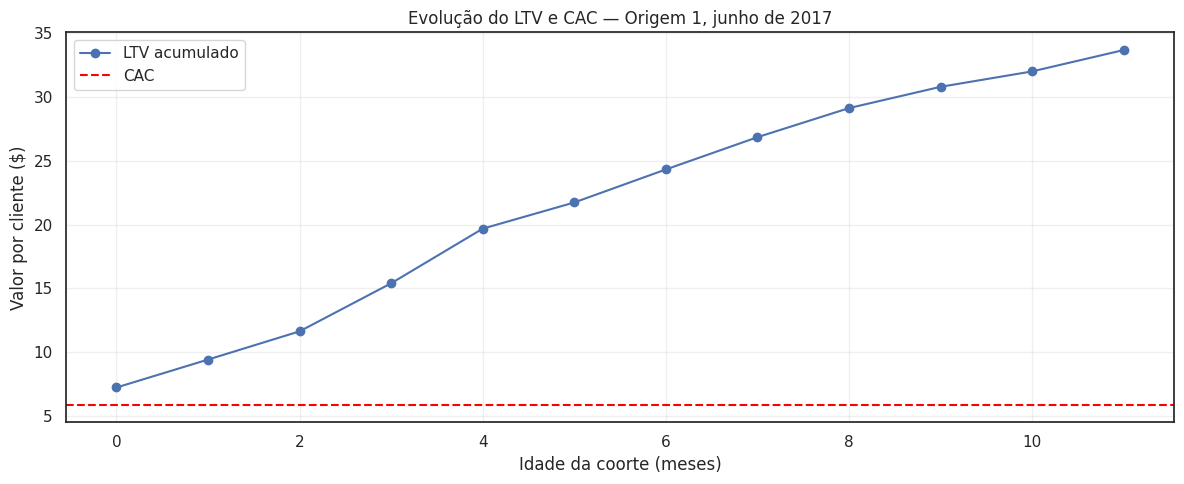

In [133]:
# Selecionar uma origem e uma coorte para visualizar
cohort_example = ltv_cac_comparison[
    (ltv_cac_comparison['Source Id'] == 1) &
    (ltv_cac_comparison['cohort_year'] == 2017) &
    (ltv_cac_comparison['cohort_month'] == 6)
]

# Criar o gráfico
plt.figure(figsize=(12, 5))

plt.plot(
    cohort_example['cohort_age'],
    cohort_example['ltv'],
    marker='o',
    label='LTV acumulado'
)

plt.axhline(
    y=cohort_example['cac'].iloc[0],
    linestyle='--',
    color='red',
    label='CAC'
)

plt.title('Evolução do LTV e CAC — Origem 1, junho de 2017')
plt.xlabel('Idade da coorte (meses)')
plt.ylabel('Valor por cliente ($)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretação e Conclusão — Evolução do LTV e CAC**

O gráfico demonstra que a coorte de junho de 2017, adquirida através da origem publicitária 1, recuperou o custo de aquisição logo no primeiro mês observado.

O LTV inicial foi de aproximadamente 7,26 \\$, enquanto o CAC foi de 5,92 \\$. Ao longo dos meses seguintes, o LTV aumentou progressivamente, atingindo cerca de 33,64 \\$ no 11.º mês.

Estes resultados indicam que a origem 1 apresentou uma evolução positiva na geração de receita por cliente, superando o custo de aquisição desde o início do período analisado.

É importante salientar que a recuperação do CAC representa a cobertura do custo de aquisição através da receita, não significando necessariamente lucro líquido, uma vez que existem outros custos associados à atividade da empresa.

<div class="alert alert-block alert-warning">

Sua leitura do gráfico está correta (LTV de 7,26 contra um CAC de 5,92, subindo para cerca de 33,64 na idade 11). Tenha cuidado com a generalização: o gráfico mostra apenas uma coorte da source 1, junho de 2017, e ela é uma das mais favoráveis. Sua própria tabela de payback mostra que apenas 7 das 12 coortes da source 1 recuperaram o CAC. Limite a afirmação a essa coorte ou apresente-a como um exemplo e aponte para o resumo entre coortes logo abaixo.

</div>

#### 10.5 Comparar o tempo de recuperação do CAC por origem

#### 10.5.1 Identificar o mês de recuperação do CAC

In [134]:
# Identificar o primeiro mês em que o LTV iguala ou supera o CAC
payback_by_cohort = (
    ltv_cac_comparison[
        ltv_cac_comparison['acquisition_cost_recovered']
    ]
    .groupby(
        ['Source Id', 'cohort_year', 'cohort_month'],
        observed=True
    )['cohort_age']
    .min()
    .reset_index(name='payback_month')
)

# Verificar os resultados
display(payback_by_cohort.head(15))

,Source Id,cohort_year,cohort_month,payback_month
0,1,2017,6,0
1,1,2017,7,0
2,1,2017,8,1
3,1,2017,9,1
4,1,2017,10,1
5,1,2017,11,1
6,1,2018,3,0
7,2,2017,6,6
8,2,2017,7,10
9,2,2017,9,1


#### 10.5.2 Resumir os resultados por origem

In [135]:
# Calcular o CAC e o último LTV observado por coorte
cohort_metrics = (
    ltv_cac_comparison
    .sort_values('cohort_age')
    .groupby(
        ['Source Id', 'cohort_year', 'cohort_month'],
        observed=True
    )
    .agg(
        cac=('cac', 'first'),
        final_ltv=('ltv', 'last'),
        last_cohort_age=('cohort_age', 'max')
    )
    .reset_index()
)

# Associar o mês de recuperação a cada coorte
cohort_metrics = cohort_metrics.merge(
    payback_by_cohort,
    on=['Source Id', 'cohort_year', 'cohort_month'],
    how='left'
)

# Identificar coortes com CAC calculável que não recuperaram o investimento
unrecovered = (
    cohort_metrics['cac'].notna() &
    cohort_metrics['payback_month'].isna()
)

# Calcular quanto do CAC foi recuperado pelas coortes não recuperadas
cohort_metrics['ltv_recovery_pct'] = (
    cohort_metrics['final_ltv'] /
    cohort_metrics['cac'] * 100
).where(unrecovered)

# Calcular a diferença entre o CAC e o LTV final observado
cohort_metrics['gap_to_cac'] = (
    cohort_metrics['cac'] -
    cohort_metrics['final_ltv']
).where(unrecovered)

# Resumir os resultados por origem publicitária
source_payback_summary = (
    cohort_metrics
    .groupby('Source Id', observed=True)
    .agg(
        total_cohorts=('cac', 'size'),
        eligible_cohorts=('cac', 'count'),
        recovered_cohorts=('payback_month', 'count'),
        median_payback_months=('payback_month', 'median'),
        mean_cac=('cac', 'mean'),
        median_final_ltv_unrecovered=('final_ltv', 'median'),
        median_last_cohort_age_unrecovered=('last_cohort_age', 'median'),
        median_ltv_recovery_pct_unrecovered=('ltv_recovery_pct', 'median'),
        median_gap_to_cac=('gap_to_cac', 'median')
    )
)

# Calcular o número de coortes que não recuperaram o CAC
source_payback_summary['unrecovered_cohorts'] = (
    source_payback_summary['eligible_cohorts'] -
    source_payback_summary['recovered_cohorts']
)

# Calcular a taxa de recuperação apenas entre coortes com CAC calculável
source_payback_summary['recovery_rate'] = (
    source_payback_summary['recovered_cohorts'] /
    source_payback_summary['eligible_cohorts'] * 100
)

# Identificar origens sem despesa registada
source_payback_summary['status'] = 'CAC calculável'

source_payback_summary.loc[
    source_payback_summary['eligible_cohorts'] == 0,
    'status'
] = 'Sem despesa registada — CAC não calculável'

# Ordenar primeiro pela taxa de recuperação e depois pelo tempo mediano
source_payback_summary = source_payback_summary.sort_values(
    ['recovery_rate', 'median_payback_months'],
    ascending=[False, True],
    na_position='last'
)

# Apresentar os resultados
display(source_payback_summary)

,total_cohorts,eligible_cohorts,recovered_cohorts,median_payback_months,mean_cac,median_final_ltv_unrecovered,median_last_cohort_age_unrecovered,median_ltv_recovery_pct_unrecovered,median_gap_to_cac,unrecovered_cohorts,recovery_rate,status
Source Id,,,,,,,,,,,,
1,12,12,7,1.0,7.212107,9.277359,5.5,76.494616,1.893018,5,58.333333,CAC calculável
2,12,12,6,4.0,12.504068,9.017201,5.5,55.429187,6.451959,6,50.000000,CAC calculável
9,12,12,5,1.0,5.413892,5.343834,5.5,76.913871,1.515714,7,41.666667,CAC calculável
5,12,12,3,2.0,7.451938,5.314195,5.5,59.762468,3.170060,9,25.000000,CAC calculável
10,12,12,2,0.0,4.867125,3.359323,5.5,66.902569,1.248248,10,16.666667,CAC calculável
4,13,12,2,3.0,6.439374,5.140776,5.0,84.272691,0.960474,10,16.666667,CAC calculável
3,12,12,0,NaN,13.802743,5.347891,5.5,37.058983,8.361732,12,0.000000,CAC calculável
7,1,0,0,NaN,NaN,1.220000,0.0,NaN,NaN,0,NaN,Sem despesa registada — CAC não calculável


<div class="alert alert-block alert-warning">

O resumo de payback está bem construído. As colunas de percentual de recuperação e de gap estão corretamente limitadas às coortes não recuperadas, a fonte 4 (13 coortes, 12 com CAC) e a fonte 7 são tratadas de forma explícita, e a ordenação pela taxa de recuperação corrige o ranking enganoso anterior. Um detalhe precisa ser corrigido: as colunas `median_final_ltv_unrecovered` e `median_last_cohort_age_unrecovered` têm nomes que sugerem que cobrem apenas coortes não recuperadas, mas `final_ltv` e `last_cohort_age` nunca são filtradas, então ambas as medianas são calculadas sobre todas as coortes. A saída mostra isso: a idade mediana é 5,5 para todas as fontes. Corrija com `cohort_metrics['final_ltv_unrec'] = cohort_metrics['final_ltv'].where(unrecovered)` e `cohort_metrics['last_age_unrec'] = cohort_metrics['last_cohort_age'].where(unrecovered)`, e depois agregue essas duas colunas com a mediana. Alternativamente, renomeie ou remova as colunas se você não precisar delas. Sua interpretação se baseia nas colunas corretas, portanto suas conclusões não são afetadas.

</div>

**Interpretação**

- **Origem 1:** apresenta o melhor desempenho global, com 58,33% das coortes a recuperarem o CAC. Entre as coortes que conseguiram recuperar o investimento, a mediana do payback é de 1 mês. Nas coortes ainda não recuperadas, o LTV final observado corresponde a cerca de 76,49% do CAC, ficando uma diferença mediana de 1,89 $ por recuperar.

- **Origem 2:** apresenta a segunda melhor taxa de recuperação, com 50% das coortes a recuperarem o CAC. No entanto, o tempo mediano de recuperação é superior, situando-se em 4 meses. Nas coortes não recuperadas, o LTV final representa aproximadamente 55,43% do CAC, com uma diferença mediana de 6,45 $.

- **Origem 9:** apresenta uma taxa de recuperação de 41,67% e uma mediana de payback de 1 mês. Nas coortes que ainda não recuperaram o CAC, o LTV final corresponde a cerca de 76,91% do investimento, faltando uma mediana de 1,52 $ para atingir o ponto de equilíbrio.

- **Origem 5:** apresenta uma taxa de recuperação de 25% e uma mediana de payback de 2 meses. Nas coortes não recuperadas, o LTV final cobre aproximadamente 59,76% do CAC, permanecendo uma diferença mediana de 3,17 $.

- **Origem 10:** embora apresente o CAC médio mais baixo (4,87 $), apenas 16,67% das coortes recuperaram o investimento. A mediana de payback é de 0 meses, mas este valor considera apenas as duas coortes que recuperaram o CAC, não representando o desempenho de todas as coortes. Nas restantes, o LTV final corresponde a cerca de 66,90% do CAC.

- **Origem 4:** também apresenta uma taxa de recuperação de 16,67%, com uma mediana de payback de 3 meses. Apesar da baixa proporção de coortes recuperadas, as coortes ainda não recuperadas alcançaram, em termos medianos, 84,27% do CAC, ficando a uma distância de apenas 0,96 $ do investimento inicial.

- **Origem 3:** apresenta o resultado mais preocupante. Nenhuma das 12 coortes com CAC calculável recuperou o investimento durante o período observado. O LTV final das coortes não recuperadas representa apenas 37,06% do CAC, mantendo uma diferença mediana de 8,36 $.

- **Origem 7:** não é possível avaliar a recuperação do CAC, uma vez que existe um comprador, mas não há despesa de publicidade registada. Por esse motivo, esta origem é mantida na tabela, mas excluída do cálculo das taxas de recuperação e do tempo de payback.

**Conclusão:** a Origem 1 destaca-se pela maior taxa de recuperação do CAC e por um tempo mediano de payback reduzido. A Origem 2 também apresenta resultados positivos, embora necessite de mais tempo para recuperar o investimento. A Origem 4 merece atenção, pois, apesar de poucas coortes terem recuperado o CAC, as restantes chegaram relativamente perto desse objetivo. Por outro lado, a Origem 3 apresenta o desempenho mais fraco, tanto na taxa de recuperação como na distância entre o LTV observado e o CAC.

Importa salientar que o tempo mediano de payback considera apenas as coortes que conseguiram recuperar o CAC. Além disso, o LTV final das coortes não recuperadas depende da sua idade no momento da última observação. Assim, estes resultados devem ser interpretados tendo em conta o período de acompanhamento disponível para cada coorte.

#### 10.5.3 Visualizar a taxa de recuperação do CAC por origem
Vamos construir um gráfico de barras para comparar a percentagem de coortes que recuperaram o CAC em cada origem.

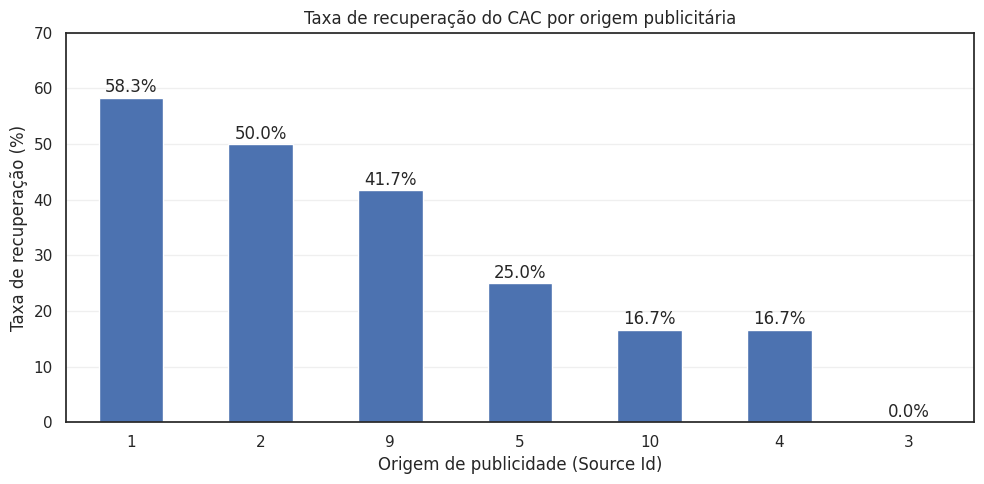

In [136]:
# Selecionar as taxas de recuperação calculáveis e ordenar da maior para a menor
recovery_rates = (
    source_payback_summary['recovery_rate']
    .dropna()
    .sort_values(ascending=False)
)

# Construir o gráfico de barras
ax = recovery_rates.plot(
    kind='bar',
    figsize=(10, 5)
)

# Adicionar os valores percentuais sobre as barras
for position, value in enumerate(recovery_rates):
    ax.text(
        position,
        value + 1,
        f'{value:.1f}%',
        ha='center'
    )

# Personalizar o gráfico
plt.title('Taxa de recuperação do CAC por origem publicitária')
plt.xlabel('Origem de publicidade (Source Id)')
plt.ylabel('Taxa de recuperação (%)')
plt.xticks(rotation=0)
plt.ylim(0, 70)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Conclusão geral e recomendações estratégicas

A análise dos dados da Y.Afisha permitiu avaliar o comportamento dos utilizadores, compreender os padrões de compra, identificar o valor gerado pelos clientes e medir a eficiência dos investimentos em marketing. Os resultados revelam oportunidades de melhoria na utilização do produto, na conversão de visitantes em compradores e na distribuição do orçamento publicitário.

### 1. Produto

A análise da atividade dos utilizadores revelou uma média de 908 utilizadores ativos diariamente (DAU), 5.716 semanalmente (WAU) e 23.228 mensalmente (MAU). Os Sticky Factors foram de 15,88% na periodicidade semanal e 3,91% na mensal, indicando margem para aumentar a frequência de utilização do produto.

A evolução temporal mostrou um crescimento significativo da atividade entre setembro e novembro de 2017, quando o MAU atingiu o seu valor máximo. A partir desse momento, observou-se uma redução gradual da atividade durante parte de 2018.

Em média, foram registadas 987,36 sessões por dia e 1,58 sessões por utilizador. A mediana foi de apenas uma sessão por utilizador. Relativamente à duração, a média foi de 10,72 minutos, enquanto a mediana foi de 5 minutos. Esta diferença evidencia uma distribuição assimétrica à direita, influenciada por algumas sessões particularmente longas.

Apenas 22,85% dos utilizadores realizaram mais de uma sessão durante o período analisado, o que demonstra uma oportunidade para melhorar a retenção e incentivar o regresso dos utilizadores.

O desktop foi o principal dispositivo de acesso, com 164.523 utilizadores únicos, comparativamente aos 71.345 utilizadores únicos registados nos dispositivos touch. Além disso, apresentou sessões mais longas e taxas de retorno superiores na maioria das origens analisadas.

Estes resultados sugerem que a empresa deve investigar os fatores associados à diminuição da atividade em 2018, melhorar a experiência de utilização nos diferentes dispositivos e desenvolver estratégias que incentivem a recorrência.

### 2. Vendas

A análise da conversão revelou que aproximadamente 16% dos visitantes se converteram em compradores. A origem 1 destacou-se com uma taxa de conversão de aproximadamente 30,62%, demonstrando uma capacidade superior para transformar visitantes em clientes.

A comparação por dispositivo revelou uma diferença significativa: o desktop apresentou uma taxa de conversão de 18,17%, enquanto o touch registou 10,85%. Assim, a conversão no desktop foi aproximadamente 1,67 vezes superior à dos dispositivos touch.

Em média, cada cliente realizou 1,38 pedidos. O ticket médio foi de 5,00 \\$, enquanto a mediana foi de 2,50 \\$. Esta diferença demonstra que uma pequena proporção de pedidos de valor elevado influencia significativamente a média. De facto, 75% dos pedidos não ultrapassaram 4,89 \\$, enquanto 99% apresentaram valores até 36,67 \\$.

A análise das coortes demonstrou que o LTV tende a aumentar à medida que os clientes permanecem na empresa. A coorte de setembro de 2017 destacou-se com um LTV de 13,44 \\$ ao oitavo mês de observação. Contudo, este resultado deve ser interpretado com cautela, uma vez que alguns pedidos de valor muito elevado podem influenciar significativamente o LTV de determinadas coortes.

Na análise segmentada do LTV ao fim de seis meses, destacaram-se as seguintes combinações:

- **Origem 1 — Desktop:** LTV de aproximadamente 13,94 \\$.
- **Origem 2 — Desktop:** LTV de aproximadamente 13,13 \\$.
- **Origem 2 — Touch:** LTV de aproximadamente 11,41 \\$.

Estes resultados reforçam o interesse das origens 1 e 2, sobretudo no segmento desktop. No entanto, o LTV representa receita acumulada por cliente e não lucro líquido.

Em termos gerais, os dados indicam que a Y.Afisha apresenta oportunidades para melhorar a conversão, incentivar compras recorrentes e aumentar o valor gerado pelos clientes ao longo do tempo.

### 3. Marketing

Durante o período analisado, a Y.Afisha investiu um total de 329.131,62 \\$ em marketing. A origem 3 concentrou 141.321,63 \\$, correspondentes a aproximadamente 42,9% do orçamento total.

A análise do retorno do investimento em marketing (ROMI), calculado considerando a receita menos o investimento publicitário, revelou diferenças importantes entre as origens:

- **Origem 1:** apresentou o melhor resultado, com ROMI de aproximadamente +49,24%. Gerou cerca de 1,49 \\$ de receita por cada dólar investido e registou a maior taxa de recuperação do CAC, com 58,33% das coortes.
- **Origem 2:** apresentou ROMI de aproximadamente +9,62%, gerando cerca de 1,10 \\$ de receita por cada dólar investido. A taxa de recuperação do CAC foi de 50%.
- **Origem 9:** apresentou ROMI de aproximadamente +4,38%, com uma relação receita/investimento de 1,04 e taxa de recuperação do CAC de 41,67%.
- **Origem 5:** apresentou ROMI de aproximadamente +1,67%, com uma relação receita/investimento de 1,02 e taxa de recuperação de 25%.
- **Origem 4:** registou ROMI de aproximadamente -7,17%, apesar de apresentar um CAC relativamente reduzido, de cerca de 5,93 \\$. A taxa de recuperação do CAC foi de 16,67%.
- **Origem 10:** apresentou ROMI de aproximadamente -23,57%. Apesar de ter o CAC mais baixo, cerca de 4,38 \\$, apenas 16,67% das coortes recuperaram o investimento.
- **Origem 3:** apresentou o resultado mais desfavorável, com ROMI de aproximadamente -61,43%, CAC de cerca de 13,49 \\$ e nenhuma das 12 coortes elegíveis a recuperar o CAC durante o período observado.

A análise do tempo de recuperação revelou que a origem 1 apresenta uma mediana de payback de 1 mês, enquanto a origem 2 apresenta uma mediana de 4 meses. Estes valores consideram apenas as coortes que conseguiram recuperar o CAC. Na origem 10, por exemplo, a mediana de zero meses corresponde apenas às duas coortes que recuperaram o investimento, representando 16,67% do total.

Importa salientar que o ROMI mede o retorno da receita face ao investimento publicitário, não correspondendo ao lucro líquido da empresa, uma vez que não contempla todos os custos operacionais.

**Análise por dispositivo**

Os resultados demonstram diferenças consistentes entre desktop e touch. O desktop apresentou:

- Uma taxa de conversão superior: 18,17%, contra 10,85% no touch.
- Sessões de maior duração.
- Taxas de retorno superiores na maioria das origens.
- Tickets médios superiores na maioria das origens analisadas.

A análise do LTV ao fim de seis meses também revelou valores superiores no desktop em várias origens, nomeadamente nas origens 1 e 2.

Apesar destes indicadores, não é possível calcular o CAC nem o ROMI por dispositivo, porque as despesas de marketing não estão discriminadas por plataforma. Assim, não podemos concluir que o desktop é necessariamente mais rentável em termos de investimento, embora apresente indicadores de comportamento e conversão mais favoráveis.

**Tratamento da origem 7**

A origem 7 apresentou um comprador e uma receita registada de 1,22 \\$, mas não possui despesas de marketing registadas. Por esse motivo, não foi possível calcular o CAC nem o ROMI. Esta origem foi mantida nas análises em que os dados estavam disponíveis, mas excluída dos indicadores que dependem de custos publicitários.

### Recomendações estratégicas

Com base nos resultados obtidos, recomendamos as seguintes ações:

1. **Redistribuir gradualmente uma parte do orçamento da origem 3 para as origens 1 e 2.**

   A origem 3 absorveu 141.321,63 \\$, mas apresentou ROMI de -61,43%, CAC de 13,49 \\$ e nenhuma coorte recuperada. Propomos, como primeiro teste, reduzir em 10% o investimento atualmente atribuído a esta origem, libertando aproximadamente 14.132,16 \\$.

   Esse montante poderá ser redistribuído da seguinte forma:
   - Cerca de 8.479,30 \\$ para a origem 1, correspondente a 60% do montante transferido.
   - Cerca de 5.652,86 \\$ para a origem 2, correspondente aos restantes 40%.

   Esta proposta justifica-se pelo desempenho das origens 1 e 2: ambas apresentam ROMI positivo, taxas de recuperação do CAC superiores às restantes origens e LTV de seis meses particularmente interessante, sobretudo no desktop.

   A redistribuição deverá ser gradual e acompanhada por testes, comparando a evolução do CAC, ROMI, conversão, LTV e taxa de recuperação das novas campanhas com os resultados anteriores.

2. **Manter as origens 9 e 5 sob acompanhamento.**

   Ambas apresentam ROMI ligeiramente positivo, embora com margens reduzidas. Recomenda-se acompanhar a evolução das coortes e verificar se conseguem manter uma relação receita/investimento superior a 1 antes de considerar aumentos significativos do orçamento.

3. **Reavaliar a origem 4.**

   Apesar do CAC relativamente baixo e do elevado volume de clientes adquiridos, a origem 4 apresenta ROMI negativo de aproximadamente -7,17% e uma taxa de recuperação de apenas 16,67%. Recomenda-se investigar a qualidade dos clientes adquiridos e acompanhar a evolução do LTV das coortes ainda não recuperadas antes de decidir manter ou reduzir o investimento.

4. **Investigar a origem 10.**

   O baixo CAC não se traduziu num retorno positivo. Recomenda-se avaliar a qualidade dos clientes, a frequência de compra e a evolução do LTV, evitando aumentar o orçamento apenas com base no custo reduzido de aquisição.

5. **Melhorar a experiência de utilização nos dispositivos touch.**

   A diferença de conversão entre desktop e touch justifica investigar o processo de navegação e compra em dispositivos móveis, identificando possíveis obstáculos que possam estar a reduzir a conversão.

6. **Acompanhar continuamente os indicadores de aquisição e valor do cliente.**

   Recomenda-se monitorizar o CAC, ROMI, taxa de conversão, LTV e tempo de recuperação por origem e coorte. Esta abordagem permitirá avaliar se as alterações na distribuição do orçamento estão efetivamente a melhorar os resultados.

### Síntese final

A análise demonstra que a eficiência dos investimentos em marketing varia significativamente entre as origens de publicidade. A origem 1 destaca-se pelo melhor desempenho global, seguida da origem 2, enquanto a origem 3 apresenta os resultados mais preocupantes, apesar de concentrar a maior parcela do orçamento.

A principal recomendação é testar uma redistribuição inicial de aproximadamente 14.132,16 \\$ da origem 3 para as origens 1 e 2, acompanhando cuidadosamente os resultados antes de implementar alterações adicionais.

Ao mesmo tempo, a Y.Afisha deverá trabalhar na retenção dos utilizadores, melhorar a conversão nos dispositivos touch e acompanhar a evolução do valor gerado pelas diferentes coortes.

Por fim, a tomada de decisão deverá combinar indicadores de aquisição, comportamento, receita e recuperação do investimento, evitando avaliar uma origem apenas pelo volume de clientes ou pelo baixo CAC. Esta abordagem permitirá utilizar o orçamento de marketing de forma mais fundamentada e melhorar progressivamente a eficiência dos investimentos.